# 📓 Cas d'usage certification Cisia Atlas — Orientation et tri multimodal des demandeurs d'emploi par l'Intelligence Artificielle

**Auteur** : `Julien DE DOMENICO`  
**Promo** : ATOS Atlas IA — Parcours 2 (Pros IT)  
**Date début** : `11/08/2026`
**Dernière mise à jour** : `04/10/2026`

---

## Objet du notebook

Ce notebook présente les travaux réalisés dans le cadre du développement d'un système d'intelligence artificielle destiné à prédire le délai potentiel de retour à l'emploi d'un usager à partir de données hybrides combinant variables tabulaires et données textuelles.

L'objectif est d'explorer plusieurs scénarios d'entraînement et d'évaluation des modèles de classification supervisée capables d'attribuer chaque situation à l'une des trois classes suivantes : retour rapide à l'emploi (< 6 mois), retour intermédiaire (entre 6 et 12 mois) ou risque de chômage de longue durée (> 12 mois). 

Ce document décrit les étapes de préparation des données, la comparaison des modèles, l'analyse des performances, les enjeux éthiques associés à l'utilisation de données sensibles ainsi que les choix retenus pour une mise en œuvre en contexte réel.

## Conventions de mise en forme

| Symbole | Signification |
|---|---|
| 🎯 | Objectif de la section / ce qu'on attend |
| 💡 | Outils, méthodes, ressources suggérées |
| ⚠️ | Point de vigilance |
| 📝 | Zone de synthèse à compléter |
| ⭐ | Pour aller plus loin |

---

## 0. Imports & configuration

In [3]:
# Imports standards
from pathlib import Path
import time
import sys
from datetime import datetime

# Pipeline ML
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import make_scorer, confusion_matrix, ConfusionMatrixDisplay, f1_score, classification_report
from sklearn.base import clone

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier

from spacy.lang.fr.stop_words import STOP_WORDS

# Explicabilité des modèles
import shap

# Utilitaires python
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns

# Modules pythons
sys.path.append(str(Path("../Scripts").resolve()))

# Reproductibilité
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Affichage
import pandas as pd
pd.set_option("display.max_columns", 50)

# gestion warning lié à la normalisation des tokens
import warnings
warnings.filterwarnings("ignore", message="Your stop_words may be inconsistent with your preprocessing")
# sns.set_theme(style="whitegrid")

d:\Projets\FormationSimplon\Certification-Atlas-Cisia\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0.1 Paramétrage et versions

In [4]:
from importlib.metadata import version
import platform
import psutil

# --- Métadonnées du dataset ---
DATASET_NAME = "dataset_trajectoire_emploi_Sujet Examen CISIA - Promo Upskilling Atlas - mai-oct2026 (Session-00279143).csv"
DATASET_SOURCE = "../data/"
DATASET_VERSION = "2026-07-22"

# --- Métadonnées de la session ---
session_date = datetime.now().isoformat(timespec="minutes")
py_version = sys.version.split()[0]

print(f"Date session : {session_date}")
print(f"Python       : {py_version}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"XGBoost      : {version('xgboost')}")
print(f"LightGBM     : {version('lightgbm')}")
print(f"Scikit-learn : {version('scikit-learn')}")
print(f"SHAP         : {shap.__version__}")
import matplotlib
import spacy
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"spaCy        : {spacy.__version__}")

print(f"Dataset      : {DATASET_NAME} (source={DATASET_SOURCE}, version={DATASET_VERSION})")

print("CPU :", platform.processor())
print("Cœurs physiques :", psutil.cpu_count(logical=False))
print("Threads :", psutil.cpu_count(logical=True))
print("RAM (Go) :", round(psutil.virtual_memory().total / 1024**3, 1))
print("OS :", platform.platform())

Date session : 2026-09-29T21:22
Python       : 3.11.7
NumPy        : 2.4.6
Pandas       : 3.0.5
XGBoost      : 3.2.0
LightGBM     : 4.7.0
Scikit-learn : 1.9.0
SHAP         : 0.51.0
Matplotlib   : 3.11.1
spaCy        : 3.8.16
Dataset      : dataset_trajectoire_emploi_Sujet Examen CISIA - Promo Upskilling Atlas - mai-oct2026 (Session-00279143).csv (source=../data/, version=2026-07-22)
CPU : Intel64 Family 6 Model 141 Stepping 1, GenuineIntel
Cœurs physiques : 8
Threads : 16
RAM (Go) : 31.7
OS : Windows-10-10.0.26200-SP0


---
## 1. 🎯 Cadrage métier & problème

### 1.1 Contexte client

Le client est une agence nationale de l’emploi souhaitant améliorer ses outils d’aide à la décision et l’orientation des demandeurs d’emploi. Le besoin consiste à identifier rapidement le niveau de risque associé au délai potentiel de retour à l’emploi d’un usager, afin d’adapter son parcours et son niveau d’accompagnement.

Le système doit exploiter des données hybrides collectées au sein d'une agence : données administratives, géographiques et socioprofessionnelles, ainsi qu’une synthèse textuelle rédigée par les conseillers. Le recours à l’intelligence artificielle vise à fournir aux conseillers une estimation rapide, fiable et reproductible, sans remplacer sa décision professionnelle.

L’enjeu métier principal est de détecter correctement les situations présentant un risque de chômage de longue durée. Une sous-estimation de ce risque pourrait priver un usager de l’accompagnement renforcé dont il a besoin.

### 1.2 Énoncé du problème

Le problème correspond à une tâche supervisée de **classification multiclasse**.

L’objectif est de prédire la classe de retour à l’emploi d’un usager à partir de données numériques, catégorielles, géographiques et textuelles. La variable cible comporte trois classes :

- **Classe 0 : retour rapide**, inférieur à 6 mois ;
- **Classe 1 : retour intermédiaire**, compris entre 6 et 12 mois ;
- **Classe 2 : risque de longue durée**, supérieur à 12 mois.

### 1.3 Bénéficiaires & impacts

Les **bénéficiaires directs** sont les conseillers de l’agence nationale de l’emploi. Ils utilisent la prédiction comme une aide à l’évaluation de la situation de l’usager et à la définition de son parcours d’accompagnement.

Les **bénéficiaires indirects** sont les demandeurs d’emploi, dont le niveau d’accompagnement peut être influencé par la classe prédite par le modèle.

Les conséquences d’une erreur ne sont pas symétriques. Une situation de classe 2 prédite en classe 0 constitue une erreur critique, car elle peut conduire à sous-estimer les difficultés de l’usager et à ne pas lui proposer l’accompagnement renforcé nécessaire. À l’inverse, une situation de classe 0 classée en niveau 1 ou 2 peut mobiliser davantage de ressources, mais présente un risque humain moins important.

Le modèle est un **outil d’aide à la décision**, la décision finale et la responsabilité de l’orientation restant sous contrôle humain.

### 1.4 Critères de succès

Le sujet ne fixe pas de seuils de performance chiffrés. Les cibles initiales correspondent donc aux exigences qualitatives du client. Elles seront précisées ou révisées après l’analyse exploratoire des données, la construction d’une baseline et l’évaluation des premiers modèles.

| Type | Critère | Objectif | Commentaire |
|---|---|---|---|
| Métier | Taux d'erreurs critiques | Limiter en priorité les situations réelles de classe 2 prédites en classe 0  | Cette erreur est considérée comme la plus grave sur les plans humain et financier |
| Modèle | F1-score macro | Garantir la qualité de l'aide à l'orientation fournie pour assister le conseiller | La cible dépendra de la qualité des données et des performances réellement atteignables |
| Modèle | Stabilité en validation croisée stratifiée | Garantir la robustesse du modèle | La stratification permet de préserver la répartition des classes dans chaque pli |
| Modèle | Généralisation | Maintenir des performances cohérentes entre la validation croisée et les données **unseen** | Permet de détecter un éventuel surapprentissage |
| Opérationnel | Temps d’inférence | Garantir un temps de réponse compatible avec l'usage opérationnel par les conseillers | Le sujet impose d’étudier le rapport entre performance prédictive et coût computationnel |

### 1.5 Risques éthiques & réglementaires anticipés

Le jeu de données contient des informations personnelles et potentiellement sensibles, notamment l’**âge**, la **nationalité hors UE**, la commune de résidence, le statut d’allocation et la synthèse textuelle de l’entretien. Certaines variables peuvent entraîner une discrimination directe ou indirecte. Les variables géographiques, administratives ou textuelles peuvent également agir comme des variables de substitution et révéler indirectement une information sensible.

Les principaux risques éthiques identifiés sont :
- discrimination directe liée à l'utilisation explicite d'une variable sensible
- discrimination indirecte via des variables corrélées (zone géographique, parcours professionnel, contenu textuel) agissant comme variables de substitution
- reproduction ou amplification de biais historiques présents dans les données d'entraînement
- atteinte au principe d'égalité de traitement entre les usagers

Le traitement des données devra respecter les principes fondamentaux de la réglementation  **RGPD** : finalité déterminée, minimisation des données, proportionnalité, sécurité, confidentialité et limitation de la conservation.

Ce système constitue une aide à la décision dans le domaine de l'emploi et de l'accompagnement des personnes. À ce titre, son utilisation doit être analysée au regard des obligations introduites par l'**AI Act** européen, notamment en matière de transparence, de supervision humaine, de gestion des risques et de documentation des modèles utilisés.

### 1.6 📝 Synthèse du cadrage

Le projet vise à développer un **système de classification** capable d’estimer le délai potentiel de retour à l’emploi d’un usager à partir de données tabulaires et textuelles. La prédiction répartit les situations entre retour rapide, retour intermédiaire et risque de longue durée. Le critère métier dominant est la **réduction des situations de chômage de longue durée incorrectement classées comme des retours rapides**. L'outil étant développé comme une aide à la décision, le principal risque éthique concerne la production de décisions discriminatoires ou défavorables à partir de données personnelles, sensibles ou indirectement corrélées à celles-ci.

---
## 2. Identification & acquisition des données

### 2.1 Sources

| Source | Type | Volumétrie | Format | Accès | Date extraction |
|----------|----------|----------|----------|----------|----------|
| Sujet d'examen CISIA - Promo Upskilling Atlas | Fichier tabulaire | 2 500 lignes, 10 colonnes | CSV | Lecture seule (jeu fourni) | Non communiquée |


### 2.2 Chargement

In [5]:
df = pd.read_csv(DATASET_SOURCE + DATASET_NAME)
df.shape

(2500, 10)

In [6]:
desc =df.describe(include="all").T
desc["count"] = desc["count"].astype("Int64")
desc["mean"] = desc["mean"].round(2)
desc["std"] = desc["std"].round(2)
display(desc)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
usager_id,2500,2500,ID_0000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,2378,NaN,NaN,NaN,40.57,13.23,18.0,29.0,41.0,52.0,63.0
niveau_diplome,2416,4,Bac,966,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anciennete_poste_ans,2500,NaN,NaN,NaN,2.97,2.98,0.0,0.8,2.0,4.1,22.6
code_rome_vise,2500,50,H1206,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
code_insee_commune,2500,2407,46283,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
est_allocataire,2456,NaN,NaN,NaN,0.6,0.49,0.0,0.0,1.0,1.0,1.0
nationalite_hors_ue,2500,NaN,NaN,NaN,0.12,0.32,0.0,0.0,0.0,0.0,1.0
synthese_entretien,2419,9,Compétences à réactualiser sur les outils numé...,338,NaN,NaN,NaN,NaN,NaN,NaN,NaN
classe_retour_emploi,2500,NaN,NaN,NaN,0.81,0.72,0.0,0.0,1.0,1.0,2.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   usager_id             2500 non-null   str    
 1   age                   2378 non-null   float64
 2   niveau_diplome        2416 non-null   str    
 3   anciennete_poste_ans  2500 non-null   float64
 4   code_rome_vise        2500 non-null   str    
 5   code_insee_commune    2500 non-null   str    
 6   est_allocataire       2456 non-null   float64
 7   nationalite_hors_ue   2500 non-null   int64  
 8   synthese_entretien    2419 non-null   str    
 9   classe_retour_emploi  2500 non-null   int64  
dtypes: float64(3), int64(2), str(5)
memory usage: 426.5 KB


### 2.3 Dictionnaire de variables

| Variable | Description | Type métier | Type Pandas | Valeurs non nulles | Plage / valeurs | Cible | Sensible |
|---|---|---|---|---|---|---|---|
| `usager_id` | Identifiant unique de l'usager | Catégorielle (identifiant) | `str` | 2500 | 2500 identifiants uniques | ❌ | ✅ |
| `age` | Âge de l'usager | Numérique discret | `float64`* | 2378 | 18 à 63 ans | ❌ | ✅ |
| `niveau_diplome` | Niveau de diplôme de l'usager | Catégorielle | `str` | 2416 | 4 modalités (modalité principale : Bac) | ❌ | ❌ |
| `anciennete_poste_ans` | Ancienneté professionnelle sur le dernier poste (années) | Numérique continu | `float64` | 2500 | 0 à 22,6 ans | ❌ | ❌ |
| `code_rome_vise` | Code ROME correspondant au métier visé | Catégorielle | `str` | 2500 | 50 codes métiers distincts | ❌ | ❌ |
| `code_insee_commune` | Code INSEE de la commune associée à l'usager | Catégorielle | `str` | 2500 | 2407 communes distinctes | ❌ | ⚠️ |
| `est_allocataire` | Indique si l'usager perçoit une allocation | Binaire | `float64`* | 2456 | 0 = Non, 1 = Oui | ❌ | ❌ |
| `nationalite_hors_ue` | Indique si l'usager possède une nationalité hors Union Européenne | Binaire | `int64` | 2500 | 0 = Non, 1 = Oui | ❌ | ✅ |
| `synthese_entretien` | Synthèse textuelle rédigée lors de l'entretien d'accompagnement | Texte | `str` | 2419 | 9 profils textuels distincts | ❌ | ⚠️ |
| `classe_retour_emploi` | Niveau de retour à l'emploi observé | Catégorielle ordinale | `int64` | 2500 | 0, 1 ou 2 | ✅ | ❌ |

### 2.4 📝 Synthèse acquisition

### Analyse macroscopique du jeu de données

Le jeu de données fourni est un jeu de taille **modérée** qui contient **2 500 observations**. Il décrit le profil de personnes accompagnées dans leur parcours de retour à l'emploi. Les données sont stockées sous la forme d'un fichier CSV comprenant **10 variables**, dont la variable cible (`classe_retour_emploi`).

La table rassemble plusieurs types d'informations :

- des caractéristiques démographiques (`age`, `nationalite_hors_ue`) ;
- des informations liées au parcours professionnel (`anciennete_poste_ans`, `niveau_diplome`) ;
- des variables de contexte (`code_insee_commune`, `code_rome_vise`) ;
- une information textuelle non structurée (`synthese_entretien`) ;
- la variable cible (`classe_retour_emploi`).

La qualité apparente des données est globalement satisfaisante. La majorité des variables sont complètes et les taux de valeurs manquantes restent faibles (inférieurs à 5 %). Les variables concernées sont :

- `age` : 122 valeurs manquantes (4,9 %) ;
- `niveau_diplome` : 84 valeurs manquantes (3,4 %) ;
- `est_allocataire` : 44 valeurs manquantes (1,8 %) ;
- `synthese_entretien` : 81 valeurs manquantes (3,2 %).

La variable cible n'a pas de valeur manquante.

L'identifiant `usager_id` présente 2 500 valeurs distinctes pour 2 500 observations, ce qui indique son caractère d'identifiant unique utilisé à des fins de traçabilité.

Plusieurs variables sensibles ou potentiellement à risque ont été identifiées dès cette étape :

- `age`, qui constitue une caractéristique personnelle pouvant être source de biais ;
- `nationalite_hors_ue`, qui correspond à un attribut sensible susceptible d'avoir un impact sur l'équité du modèle ;
- `usager_id`, qui est un identifiant direct ;
- `code_insee_commune` peut contribuer indirectement à la réidentification de certains individus.
- `synthese_entretien`, qui pourrait contenir des informations d'identification ou des caractéristiques personnelles

Enfin, la présence de la variable textuelle (`synthese_entretien`) indique que le problème combine des données structurées et non structurées, ce qui ouvre la possibilité de comparer différentes approches de modélisation reposant sur les variables tabulaires, le texte ou leur combinaison.

---
## 3. Exploration & analyse des données (EDA)

**Compétences** : C2 (risques éthiques détectables dans la donnée), C3 (préparation des données)

🎯 Comprendre la donnée **avant** de la transformer. Détecter manquants, doublons, aberrations, déséquilibres, biais.

⚠️ EDA ≠ catalogue de graphiques. Chaque visualisation doit servir une question.

### 3.1 Première analyse

In [8]:
df.head()

,usager_id,age,niveau_diplome,anciennete_poste_ans,code_rome_vise,code_insee_commune,est_allocataire,nationalite_hors_ue,synthese_entretien,classe_retour_emploi
0,ID_0000,56.0,Bac+2,2.6,D1503,18273,1.0,0,Compétences à réactualiser sur les outils numé...,1
1,ID_0001,46.0,Sans diplôme,10.5,G1302,07240,0.0,0,Cumul de difficultés. Pas de moyen de transpor...,2
2,ID_0002,NaN,Bac,1.4,M1705,01405,NaN,0,Compétences à réactualiser sur les outils numé...,0
3,ID_0003,60.0,Bac,0.2,A1203,63359,1.0,0,Problème ponctuel de mobilité géographique. Zo...,1
4,ID_0004,25.0,Sans diplôme,1.2,N1301,21302,1.0,0,Projet de reconversion à affiner. Besoin d'une...,0


### Conclusion

- La variable binaire `est_allocataire` est lue comme un flottant à cause des valeurs manquantes qu'on voit apparaitre dès les premières lignes
- La variable `code_rome_vise` semble être une nomenclature métier (D1503, G1302, M1705, A1203, N1301) qui pourrait nécessiter une table de correspondance
- Le **code INSEE** est lu comme du texte ce qui permet de garder la structure du code avec 5 caractères, les 2 premiers représentant le département

### 3.2 Qualité des données : manquants, doublons, valeurs aberrantes

In [9]:
# Analyse des manquants
missing = pd.DataFrame({"nb_manquants": df.isna().sum(), "pct_manquants": (df.isna().mean() * 100).round(2)})

print(missing.sort_values("nb_manquants", ascending=False).head(10))

                      nb_manquants  pct_manquants
age                            122           4.88
niveau_diplome                  84           3.36
synthese_entretien              81           3.24
est_allocataire                 44           1.76
usager_id                        0           0.00
anciennete_poste_ans             0           0.00
code_insee_commune               0           0.00
code_rome_vise                   0           0.00
nationalite_hors_ue              0           0.00
classe_retour_emploi             0           0.00


In [10]:
# Recheche de doublons
# On supprime la colonne usager_id qui est un identifiant unique
df.drop(columns="usager_id").duplicated().sum()

np.int64(0)

In [11]:
# Nombre de valeurs uniques des variables catégorielles ordinales
print(f"""Nombre de catégories de la variable code_rome_vise : {df["code_rome_vise"].nunique()}""")
print(f"""Nombre de catégories de la variable code_insee_commune : {df["code_insee_commune"].nunique()}""")

Nombre de catégories de la variable code_rome_vise : 50
Nombre de catégories de la variable code_insee_commune : 2407


In [12]:
# Recherche de manquants implicites
valeurs_suspectes = ["", " ", "-", "?", "NC", "N/A", "Inconnu", "Non renseigné", "(Vides)"]
colonnes_suspectes = []
for col in df.select_dtypes(include="str").columns:
    nb = df[col].isin(valeurs_suspectes).sum()
    if nb > 0:
        colonnes_suspectes.append(f"{col} ({nb})")

if colonnes_suspectes:
    print("Valeurs suspectes détectées dans :")
    print("\n".join(colonnes_suspectes))
else:
    print("Aucune valeur suspecte détectée parmi les manquants implicites recherchés.")

Aucune valeur suspecte détectée parmi les manquants implicites recherchés.


In [13]:
# Vérification que les variables binaires contiennent bien les valeurs attendues
for col in ["est_allocataire", "nationalite_hors_ue"]:
    print(df[col].value_counts(dropna=False))
    print("\n-----")

est_allocataire
1.0    1463
0.0     993
NaN      44
Name: count, dtype: int64

-----
nationalite_hors_ue
0    2205
1     295
Name: count, dtype: int64

-----


In [14]:
# Analyse de la distribution des variables suivant leur type
num_cols = df.select_dtypes(include=["number"]).columns
cat_cols = df.select_dtypes(include=["string"]).columns
cat_cols = [col for col in cat_cols if col != "synthese_entretien"]

In [15]:
# Variables numériques
display(df[num_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,2378.0,40.566442,13.225242,18.0,29.0,41.0,52.0,63.0
anciennete_poste_ans,2500.0,2.971600,2.979548,0.0,0.8,2.0,4.1,22.6
est_allocataire,2456.0,0.595684,0.490859,0.0,0.0,1.0,1.0,1.0
nationalite_hors_ue,2500.0,0.118000,0.322673,0.0,0.0,0.0,0.0,1.0
classe_retour_emploi,2500.0,0.806400,0.719671,0.0,0.0,1.0,1.0,2.0


In [16]:
# Analyse des variables catégorielles
from scipy.stats import entropy

rows = []
for col in cat_cols:
    p = df[col].value_counts(normalize=True)
    nb_modalites = len(p)
    pct_modalite_majoritaire = p.iloc[0] * 100
    pct_moyenne_theorique = 100 / nb_modalites
    ratio_concentration = (pct_modalite_majoritaire / pct_moyenne_theorique)

    entropie_normalisee = entropy(p) / np.log(nb_modalites)

    rows.append({"Variable": col,
                 "Nb modalités": nb_modalites,
                 "Catégorie majoritaire": p.index[0],
                 "% catégorie majoritaire": round(pct_modalite_majoritaire, 2),
                 "% moyen théorique": round(pct_moyenne_theorique, 2),
                 "Ratio concentration": round(ratio_concentration, 2),
                 "Entropie normalisée": round(entropie_normalisee, 3)})

cat_summary = pd.DataFrame(rows)

display(cat_summary.sort_values("Ratio concentration", ascending=False))

,Variable,Nb modalités,Catégorie majoritaire,% catégorie majoritaire,% moyen théorique,Ratio concentration,Entropie normalisée
3,code_insee_commune,2407,46283,0.12,0.04,2.89,0.998
1,niveau_diplome,4,Bac,39.98,25.00,1.60,0.961
2,code_rome_vise,50,H1206,2.84,2.00,1.42,0.997
0,usager_id,2500,ID_0000,0.04,0.04,1.00,1.000


In [17]:
# Analyse de la variable cible
display(df["classe_retour_emploi"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2))

classe_retour_emploi
0    37.44
1    44.48
2    18.08
Name: proportion, dtype: float64

### Conclusion

- Pas de manquant implicite détecté
- Pas de valeur métier aberrante dans les plages de valeur 

| Variable | Observation |
|---|---|
| `age` | 18 à 63 ans → plage cohérente |
| `anciennete_poste_ans` | 0 à 22,6 ans → plage cohérente |
| `est_allocataire` | uniquement 0 et 1 |
| `nationalite_hors_ue` | uniquement 0 et 1 (hors valeurs manquantes) |
| `classe_retour_emploi` | uniquement 0, 1 et 2 |

Variables numériques :
- l'âge moyen (40,6 ans) est très proche de la médiane (41 ans) ce qui suggère une distribution équilibrée sur la plage 18 - 63 ans
- l'ancienneté a une variabele supérieure à la médiane et 75% des individus ont une anciénneté inférieure ou égale à 4,1 ans. Cela peut indiquer la présence de quelques profils avec une ancienneté élevée qui tirent la moyenne vers le haut

Variables binaires :
- La variable `est_allocataire` a 3 valeurs possibles (0, 1, NaN). Sa moyenne est de 0.596. La population du dataset est donc majoritairement allocataire
- La variable `nationalite_hors_ue` a 2 valeurs possibles (0 et 1). Sa moyenne est de 0.118. La distribution est donc fortement déséquilibrée avec 88.2% des individus ayant pour origine un pays de l'union européenne

Variables catégorielles :
- La variable `code_insee_commune` présente une très forte cardinalité (2 407 communes distinctes pour 2 500 observations) et une répartition quasi uniforme (entropie normalisée de 0,998), indiquant l'absence de concentration géographique des individus. La cardinalité très élevée pourrait conduire à une dilution des features dans le modèle et à une augmentation de sa complexité (qui devrait rester acceptable sur un jeu de données de 2500 échantillons). De plus la faible représentativité statistique des modalités nous amène à envisager un regroupement géographique au niveau département.
- L'analyse de la variable `code_rome_vise` montre que sa cardibalité est élevée (50 modalités) et est relativement bien répartie (2.84% pour la classe majoritaire contre 2% pour une moyenne parfaite)
- La cardibalité de la variable `niveau_diplome` est faible (4 modalités). La catégorie Bac est majoritaire avec 39.98% mais l'entropie de 0.961 montre que la répartition entre les 4 modalités reste relativement diversifiée

### 3.3 Distribution des variables

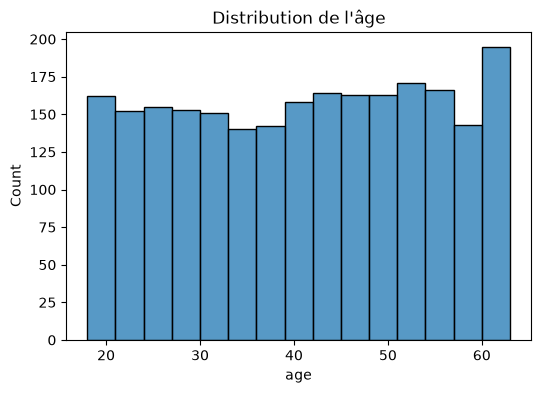

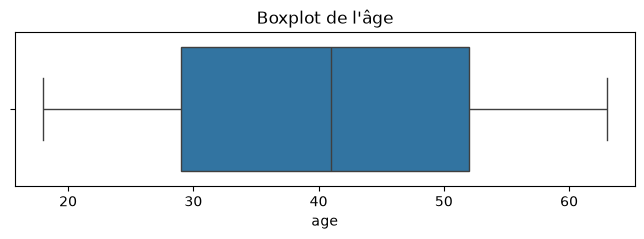

In [18]:
# Distribution de l'age
plt.figure(figsize=(6,4))
sns.histplot(df["age"], bins=15)
plt.title("Distribution de l'âge")
plt.show()

plt.figure(figsize=(8,2))
sns.boxplot(x=df["age"])
plt.title("Boxplot de l'âge")
plt.show()

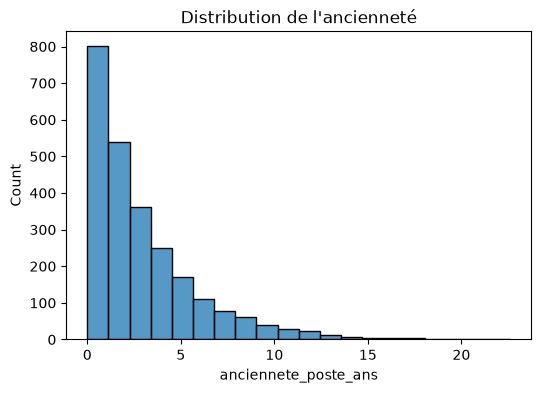

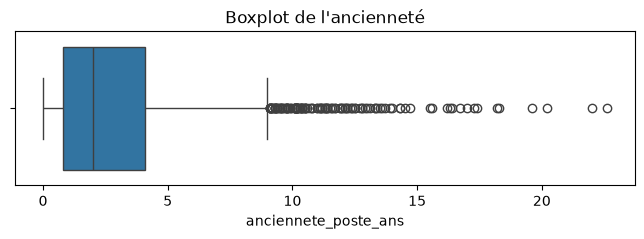

In [19]:
plt.figure(figsize=(6,4))
sns.histplot(df["anciennete_poste_ans"], bins=20)
plt.title("Distribution de l'ancienneté")
plt.show()

plt.figure(figsize=(8,2))
sns.boxplot(x=df["anciennete_poste_ans"])
plt.title("Boxplot de l'ancienneté")
plt.show()

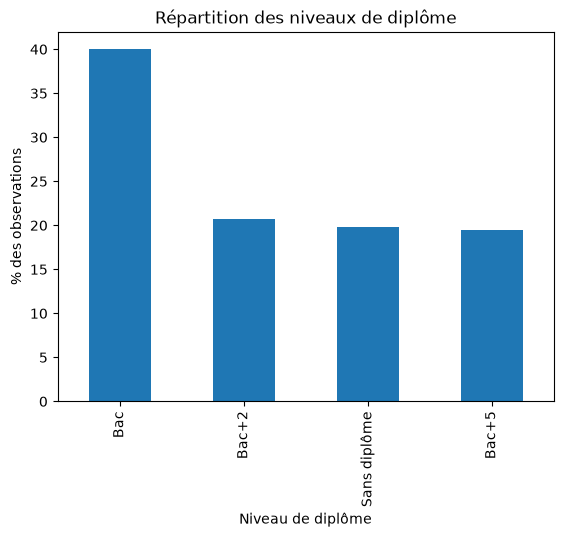

In [20]:
df["niveau_diplome"].value_counts(normalize=True).mul(100).sort_values(ascending=False).plot(kind="bar")

plt.title("Répartition des niveaux de diplôme")
plt.ylabel("% des observations")
plt.xlabel("Niveau de diplôme")
plt.show()

In [21]:
pd.DataFrame({"nb_observations": df["code_rome_vise"].value_counts()}).describe()

,nb_observations
count,50.000000
mean,50.000000
std,8.141604
min,30.000000
25%,45.000000
50%,48.500000
75%,54.750000
max,71.000000


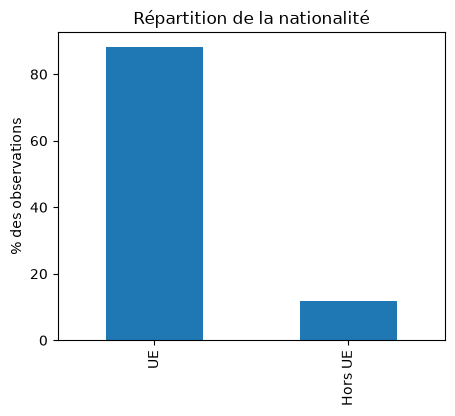

In [22]:
df["nationalite_hors_ue"].value_counts(normalize=True).sort_index().mul(100).rename(index={0: "UE", 1: "Hors UE"}).plot(kind="bar", figsize=(5,4))

plt.title("Répartition de la nationalité")
plt.ylabel("% des observations")
plt.xlabel("")
plt.show()

### Conclusion

- Comme attendu après analyse des valeurs moyenne et médiane, la variable `age` présente une répartition relativement homogène entre 18 et 63 ans. Le boxplot ne révèle aucune valeur aberrante selon la règle de l'écart interquartile (IQR), ce qui confirme la cohérence des données observées.
- La variable `anciennete_poste_ans` présente une distribution fortement asymétrique à droite. La majorité des usagers possède une ancienneté relativement faible, avec une médiane de 2 ans et un troisième quartile de 4,1 ans. Quelques individus présentent toutefois des anciennetés nettement plus élevées pouvant atteindre 22,6 ans.
Le boxplot identifie plusieurs observations comme atypiques selon le critère statistique de l'écart interquartile. Cependant, d'un point de vue métier ces valeurs sont cohérentes et seront donc conservées pour l'entrainement.
- L'analyse graphique de la variable `niveau_diplome` confirme que la catégorie « Bac » est la plus représentée avec 39,98 % des observations. On voit cependant que les trois autres niveaux de diplôme affichent des proportions proches (environ 20 % chacun), ce qui traduit une répartition globalement équilibrée. Cette observation confirme la valeur élevée obtenue pour l'entropie normalisée (0,961), indiquant une bonne diversité des modalités et l'absence de catégorie fortement sous-représentée.
- La variable `code_rome_vise` présente une cardinalité modérée de 50 modalités. L'analyse des effectifs montre une répartition particulièrement homogène entre les différents métiers visés. Chaque code ROME est représenté par au moins 30 observations et au plus 71, pour une moyenne de 50 observations. Aucune modalité rare ou sous-représentée n'a été identifiée, ce qui limite les risques liés à l'encodage des catégories et garantit une bonne représentativité des différents métiers dans l'apprentissage des modèles.
- La variable `nationalite_hors_ue` présente un déséquilibre marqué. Les usagers de nationalité hors Union Européenne représentent seulement 11,8 % de la population étudiée, contre 88,2 % pour les autres usagers. Cette sous-représentation peut limiter la capacité du modèle à apprendre correctement les caractéristiques de ce sous-groupe et conduire à des performances différentes selon les catégories de population. Une analyse des performances par sous-groupe ainsi que des indicateurs d'équité seront donc nécessaires afin de vérifier l'absence de biais discriminatoires.

### 3.3.1 Regroupement de la variable code_insee_commune

In [23]:
# Regroupement des codes INSEE par département
df["code_departement"] = df["code_insee_commune"].str[:2]

# Calcul de la répartition
vc = df["code_departement"].value_counts()

nb_modalites = vc.shape[0]
categorie_majoritaire = vc.index[0]
pct_majoritaire = 100 * vc.iloc[0] / vc.sum()

pct_moyen_theorique = 100 / nb_modalites
ratio_concentration = pct_majoritaire / pct_moyen_theorique

p = vc / vc.sum()
entropie_normalisee = entropy(p) / np.log(nb_modalites)

print(f"Nb modalités : {nb_modalites}")
print(f"Catégorie majoritaire : {categorie_majoritaire}")
print(f"% catégorie majoritaire : {pct_majoritaire:.2f}")
print(f"% moyen théorique : {pct_moyen_theorique:.2f}")
print(f"Ratio concentration : {ratio_concentration:.2f}")
print(f"Entropie normalisée : {entropie_normalisee:.3f}")


Nb modalités : 96
Catégorie majoritaire : 21
% catégorie majoritaire : 2.68
% moyen théorique : 1.04
Ratio concentration : 2.57
Entropie normalisée : 0.967


In [24]:
# Analyse d'impact de la variable agrégé `code_departement`

# Effectifs par département
effectifs = df["code_departement"].value_counts()

# On ne garde que les départements ayant un effectif suffisant pour une estimation plus fiable
deps_ok = effectifs[effectifs >= 20].index

ct = pd.crosstab(df.loc[df["code_departement"].isin(deps_ok), "code_departement"],
                 df.loc[df["code_departement"].isin(deps_ok), "classe_retour_emploi"],
                 normalize="index")

In [25]:
# Tri pour obtenir les départements ou la classe 2 est la plus fréquente
ct.sort_values(2, ascending=False).head(5)

classe_retour_emploi,0,1,2
code_departement,,,
02,0.186441,0.423729,0.389831
17,0.250000,0.437500,0.312500
64,0.250000,0.450000,0.300000
69,0.272727,0.454545,0.272727
88,0.315789,0.421053,0.263158


In [26]:
# Tri pour obtenir les départements ou la classe 2 est la moins fréquente
ct.sort_values(2, ascending=True).head(5)

classe_retour_emploi,0,1,2
code_departement,,,
29,0.424242,0.545455,0.030303
50,0.534884,0.418605,0.046512
07,0.523810,0.428571,0.047619
08,0.580645,0.354839,0.064516
65,0.365854,0.560976,0.073171


### Conclusion

- Le regroupement de la variable `code_insee_commune` permet de conserver l'information géographique tout en réduisant fortement la cardinalité (2407 communes -> 96 départements). La variable reste relativement dispersée, le département le plus représenté ayant 2.68% des individus soit ~67 personnes.
- Le regroupement réduit également le risque de réidentification des individus
- Après exclusion des départements disposant d'un effectif insuffisant, la proportion de la classe 2 varie d'environ 3 % à 39 % selon le département considéré, contre une moyenne globale de 18 %. Ces écarts suggèrent que l'information géographique pourrait être corrélée à la cible et présenter un intérêt prédictif.

### 3.3.2 Analyse de la feature `synthese_entretien`

<Axes: xlabel='classe_retour_emploi', ylabel='synthese_entretien'>

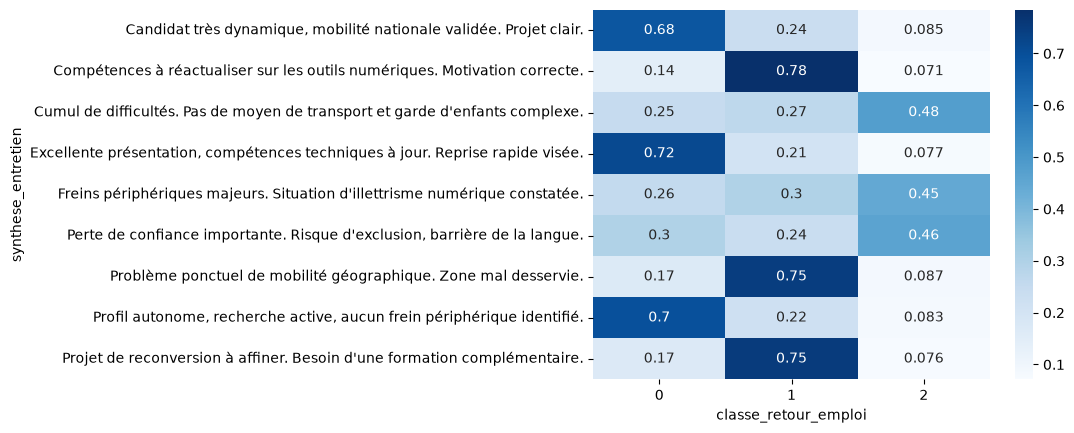

In [27]:
ct = pd.crosstab(df["synthese_entretien"],
                 df["classe_retour_emploi"],
                 normalize="index")

sns.heatmap(ct, annot=True, cmap="Blues")

### Conclusion

- La variable `synthese_entretien` ne contient que 9 modalités distinctes. On voit que les formulations correspondent à des profils génériques et ne comportent pas d'informations directement identifiantes. Elles décrivent cependant des situations personnelles ou sociales (barrière de la langue, illétrisme numérique, garde d'enfants complexe) qui peuvent constituer des proxy indirects de caractéristiques protégées. Une attention particulière devra donc être portée à l'interprétation des modèles exploitant cette variable.
- Le traitement de cette variable en variable catégorielle est à étudier, même si son fonctionnement exact (liste prédéfinie ou saisie libre contrainte) mériterait une confirmation métier.
- Cette variable est fortement discriminante vis-à-vis de la cible : 
    - les labels Dynamique, AUtonome et Compétences à jour sont majoritairement associé à la classe 0, 
    - les labels Reconversion, Mobilité et "Remise à niveau" sont majoritairement associé à la classe 1
    - les labels "Cumul de difficultés", "Freins périphériques" et "Perte de confiance" sont majoritairement associés à la classe 2
- Les écarts sur la classe 2 entre les trois groupes sont très importants passant de plus de 45% pour certains groupes à moins de 10% pour d'autre
- La variable `synthese_entretien` semble contenir énormément d'informations 


### 3.4 Variable cible : équilibre des classes

In [28]:
display(df["classe_retour_emploi"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2))

classe_retour_emploi
0    37.44
1    44.48
2    18.08
Name: proportion, dtype: float64

### Conclusion 

- La variable cible présente un léger déséquilibre. Cependant la classe minoritaire (2 : risque de longue durée) garde suffisamment d'échantillons (>450) pour l'entrainement. Le déséquilibre devra être pris en compte dans les métriques pour l'analyse des performances du modèle en utilisant le F1-score macro et les matrices de confusion et pas uniquement l'accuracy.

### 3.5 Corrélations & relations entre variables

#### 3.5.1 Variables numériques

In [29]:
num_cols = ["age", "anciennete_poste_ans"]

In [30]:
# Correlation ente les variables numériques
corr = df[num_cols].corr()

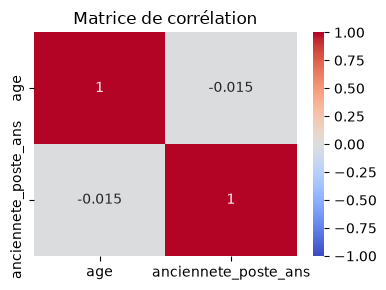

In [31]:
# Display 
plt.figure(figsize=(4,3))
sns.heatmap(corr,
            annot=True,
            cmap="coolwarm",
            vmin=-1,
            vmax=1)

plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

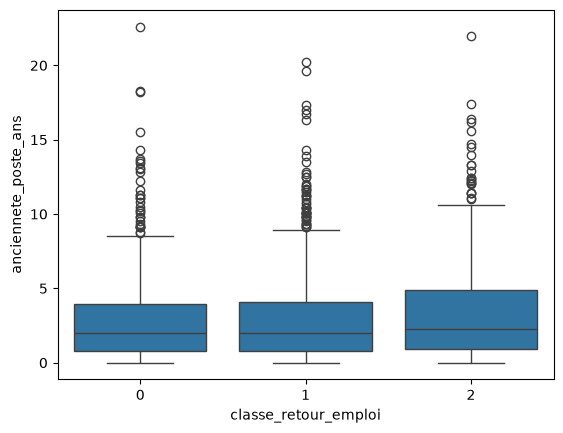

In [32]:
# Correlation de l'ancienneté à la cible
# L'age sera traité à part
sns.boxplot(data=df,
            x="classe_retour_emploi",
            y="anciennete_poste_ans")

plt.show()

#### 3.5.2 Variables catégorielles

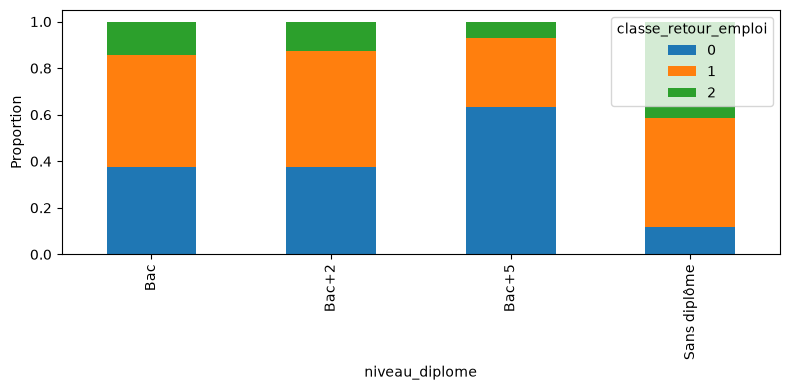

In [33]:
# Relations entre la variable classe_retour_emploi et la cible
ct = pd.crosstab(df["niveau_diplome"],
                 df["classe_retour_emploi"],
                 normalize="index")

ct.plot(kind="bar",
        stacked=True,
        figsize=(8,4))

plt.ylabel("Proportion")
plt.tight_layout()
plt.show()

In [34]:
# Relations entre la variable code_rome_vise et la cible
ct_rome = pd.crosstab(df["code_rome_vise"],
                      df["classe_retour_emploi"],
                      normalize="index")

ct_rome.sort_values(2, ascending=False).head(5)

classe_retour_emploi,0,1,2
code_rome_vise,,,
M1602,0.163934,0.442623,0.393443
M1607,0.146341,0.463415,0.390244
K1601,0.214286,0.428571,0.357143
M1501,0.244444,0.466667,0.288889
K2106,0.446809,0.276596,0.276596


In [35]:
ct_rome.sort_values(2, ascending=True).head(5)

classe_retour_emploi,0,1,2
code_rome_vise,,,
J1301,0.708333,0.270833,0.020833
M1805,0.500000,0.462963,0.037037
H1504,0.326531,0.632653,0.040816
K1201,0.500000,0.437500,0.062500
M1802,0.557692,0.365385,0.076923


### Conclusion

- Il n'existe pas de relation linéaire significative entre l'âge et l'ancienneté du poste (correlation de -0.015), les individus les plus âgés ne présentent pas systématiquement une ancienneté plus élevée.
- La variable `anciennete_poste_ans` semble également associée à la variable cible mais de manière moins marquée. Les individus ayant une durée retour à l'emploi de classe 2 ont une ancienneté légèrement supérieure à celle des 2 autres classes.
- L'histogramme de corrélation entre la variable `niveau_diplome` et la variable cible montre une relation entre ces 2 variables et montre que cette variable pourrait contribuer significativement aux performances du modèle. 
    - Les individus disposant d'un diplôme Bac+5 sont majoritairement associés à la classe 0 (environ 63 %) et très rarement à la classe 2 (environ 7 %)
    - À l'inverse, les usagers sans diplôme présentent une proportion nettement plus importante de classe 2 et une proportion réduite de classe 0
    - Les catégories Bac et Bac+2 présentent des répartitions intermédiaires relativement proches.
- On constate également que les catégorie de cette variable possèdent un ordre naturel et pourrait être encodée de manière ordinale (Sans diplôme < Bac < Bac+2 < Bac+5)
- L'analyse decorrélation de la variable `code_rome_vise` avec la cible montre des disparités importantes dans la proportion de classe 2 suivant les types de métiers visés. La répartition des ratios entre 2.08% et 39.3% pour la classe 2, suggère que la variable `code_rome_vise` contient de l'information prédictive

### 3.6 Analyse des biais & variables sensibles

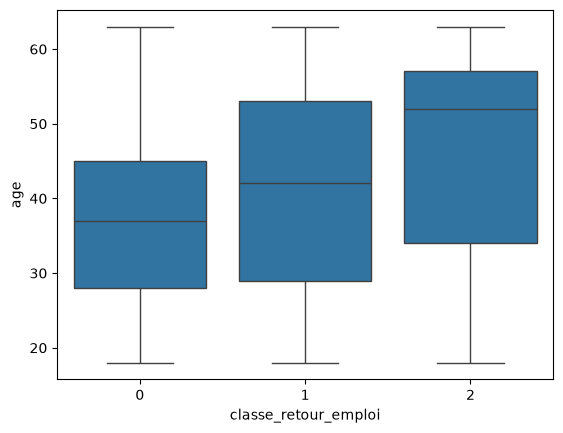

In [36]:
# Correlation ente l'age et la variable cible
sns.boxplot(data=df,
            x="classe_retour_emploi",
            y="age")

plt.show()

In [37]:
# On définit comme outcome favorable un retour à l'emploi rapide ou moyen
df["outcome_favorable"] = df["classe_retour_emploi"].isin([0,1]).astype(int)

# On crée des bins pour la variable age pour affiner les résultats
df["tranche_age"] = pd.cut(df["age"], 
                           bins=[18, 30, 40, 50, 60, 70], 
                           labels=["18-29", "30-39", "40-49", "50-59", "60+"], 
                           right=False)

pd.crosstab(df["tranche_age"], df["classe_retour_emploi"], normalize="index").mul(100).round(2)

classe_retour_emploi,0,1,2
tranche_age,,,
18-29,41.64,44.21,14.15
30-39,52.58,38.97,8.45
40-49,49.62,41.70,8.68
50-59,15.93,50.73,33.33
60+,10.26,50.77,38.97


In [38]:
# DI de la variable age
taux_ref = (df.loc[df["tranche_age"] == "30-39", "outcome_favorable"].mean())

di_age = (df.groupby("tranche_age")["outcome_favorable"].mean() / taux_ref).round(3)

display(di_age)

tranche_age
18-29    0.938
30-39    1.000
40-49    0.998
50-59    0.728
60+      0.667
Name: outcome_favorable, dtype: float64

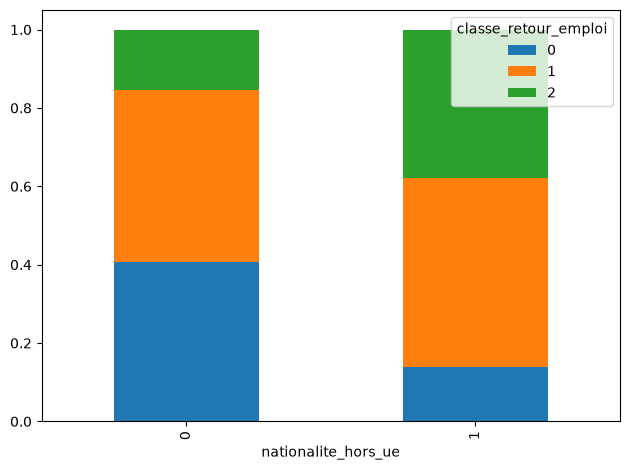

In [39]:
# Correlation ente l'origine et la variable cible
ct = pd.crosstab(df["nationalite_hors_ue"],
                 df["classe_retour_emploi"],
                 normalize="index")

ct.plot(kind="bar", stacked=True)
plt.tight_layout()

In [40]:
# DI de la variable `nationalite_hors_ue`
taux_reference = df[df["nationalite_hors_ue"] == 0]["outcome_favorable"].mean()
taux_protege = df[df["nationalite_hors_ue"] == 1]["outcome_favorable"].mean()

di = taux_protege / taux_reference

print(f"Disparate Impact nationalite_hors_ue : {di:.3f}")

Disparate Impact nationalite_hors_ue : 0.733


### Conclusion

- Le boxplot entre la variable `age` et la cible montre une **augmentation de la médiane** pour les classes de retour à l'emploi 1 et 2. Le recouvrement entre les distribution suggère que l'âge ne permet pas à lui seul d'expliquer la variable cible mais qu'il constitue un facteur important. Étant le caractère sensible de la variable, son utilisation devra faire l'objet d'une vigilance particulière lors de la modélisation.
- L'analyse par **tranche d'âges** on voit que la classe 2, retour rapide à l'amploi, diminue fortement après 50 ans au profit de la classe 2, risque de longue durée.
- Les **indicateurs de disparate impacts**  calculés sur l'outcome favorable mettent en évidence des disparités modérées liées à l'âge et à la nationalité. Les groupes **50-59 ans**, **60 ans et plus** ainsi que la populati;on **hors UE** présentent des valeurs inférieures au seuil d'alerte de **0,8**
- Ces résultats montrent que les données d'entraînement contiennent des déséquilibres susceptibles d'être reproduits ou amplifiés et justifient la comparaison de scénarios avec et sans variables sensibles, ainsi qu'une évaluation des performances et de l'équité par sous-groupes.

### DI croisé age / nationalité

In [41]:
df["groupe_age_nat"] = (df["tranche_age"].astype(str) + "_" + df["nationalite_hors_ue"].astype(str))

resultats = (df.groupby("groupe_age_nat").agg(effectif=("outcome_favorable", "size"), taux_favorable=("outcome_favorable", "mean")))

ref = resultats["taux_favorable"].max()

resultats["DI"] = resultats["taux_favorable"] / ref

resultats.sort_values("DI")

,effectif,taux_favorable,DI
groupe_age_nat,,,
60+_1,25,0.080000,0.085854
50-59_1,58,0.241379,0.259041
60+_0,170,0.688235,0.738594
50-59_0,488,0.717213,0.769692
30-39_1,45,0.755556,0.810840
18-29_1,93,0.774194,0.830842
18-29_0,529,0.873346,0.937249
40-49_1,61,0.901639,0.967613
40-49_0,469,0.914712,0.981642


## Conclusion

L'analyse croisée de l'âge et de la nationalité met en évidence un phénomène d'intersectionnalité : La combinaison "âge élevé" et "nationalité hors UE" entraîne une diminution beaucoup plus forte du taux de retour à l'emploi favorable que chacun de ces facteurs pris individuellement. C'est le cas pour les groupes **"50-59 ans hors UE"** (DI = 0,259 ; effectif = 58) et **"60 ans et plus hors UE"** (DI = 0,086 ; effectif = 25)

Ces résultats suggèrent l'existence de disparités cumulées dans les données, susceptibles d'être reproduites ou amplifiées par un modèle entraîné sur ce jeu. Ils doivent toutefois être interprétés avec prudence en raison des effectifs réduits de certains sous-groupes, en particulier pour les usagers de **60 ans et plus hors UE**.

### 3.7 📝 Synthèse EDA

*[Top 5 enseignements de l'EDA. Hypothèses de travail pour la modélisation. Risques de biais identifiés. **Révision éventuelle des cibles 1.4** à la lumière de la donnée.]*

1. **La qualité globale des données est satisfaisante.**  
   Le jeu de données ne présente ni doublons métier évidents, ni manquants implicites, ni valeurs aberrantes bloquantes sur le plan métier. Les quelques valeurs manquantes observées restent limitées.

2. **Les variables numériques sont cohérentes, mais l'ancienneté est asymétrique.**  
   L'âge présente une distribution relativement équilibrée, tandis que `anciennete_poste_ans` est fortement asymétrique à droite, avec quelques valeurs élevées mais plausibles.
   **Implication pour l'entraînement :** ces observations doivent être conservées ; il faudra privilégier un prétraitement robuste et comparer des modèles capables de gérer des distributions non gaussiennes.

3. **Certaines variables semblent très informatives pour la cible.**  
   `niveau_diplome`, `anciennete_poste_ans`, `code_rome_vise`, la géographie agrégée et surtout `synthese_entretien` montrent des différences marquées selon les classes de retour à l'emploi.
   **Implication pour l'entraînement :** ces variables constituent des candidates importantes pour la prédiction et devront être conservées dans les scénarios de base. Une attention particulière devra être portée à la contribution réelle de `synthese_entretien`, qui semble très discriminante.

4. **La variable géographique brute est trop fine pour être utilisée telle quelle.**  
   `code_insee_commune` présente une très forte cardinalité, avec une information très fragmentée. Le regroupement au niveau département réduit fortement cette complexité tout en conservant un signal potentiellement utile.
   **Implication pour l'entraînement :** il est préférable d'utiliser une variable géographique agrégée (`departement`) plutôt que la commune brute, afin de limiter la dilution des features et le risque de surapprentissage.

5. **La variable cible est légèrement déséquilibrée, sans être inutilisable.**  
   La classe 2 est minoritaire mais reste suffisamment représentée pour être apprise correctement.
   **Implication pour l'entraînement :** l'évaluation ne devra pas reposer sur l'accuracy seule. Le **F1-score macro**, les **matrices de confusion** et l'analyse des erreurs sur la classe 2 seront prioritaires.

6. **Des risques de biais sont déjà visibles dans les données.**  
   L'âge et la nationalité hors UE apparaissent associés à des différences d'outcome favorable, avec un signal renforcé dans l'analyse croisée âge / nationalité. Ces disparités existent avant même la modélisation.
   **Implication pour l'entraînement :** il faudra comparer plusieurs scénarios avec et sans variables sensibles, mesurer les performances par sous-groupes et suivre des indicateurs d'équité pour vérifier si le modèle reproduit ou amplifie ces déséquilibres.

### Hypothèses de travail pour la modélisation

- construire au moins un scénario **baseline** avec l'ensemble des variables utiles. On exclut la variable `usager_id` qui est un identifiant de traçabilité ;
- utiliser une **géographie agrégée** plutôt que `code_insee_commune` ;
- tester `synthese_entretien` soit comme **variable catégorielle**, soit comme **texte vectorisé**, puis arbitrer empiriquement ;
- privilégier des modèles robustes sur données tabulaires hétérogènes ;
- tester un scénario **sans variables sensibles** (`age`, `nationalite_hors_ue`) ;
- évaluer systématiquement le compromis **performance / robustesse / équité**.

### Révision des critères de succès

Au vu de l'EDA, les critères définis en section 1.4 restent pertinents. Ils doivent néanmoins être complétés par deux points de vigilance opérationnels :  
- une attention spécifique aux erreurs sur la **classe 2**, qui reste la classe métier la plus critique ;  
- une analyse explicite de l'**équité par sous-groupes**, en particulier selon l'âge et la nationalité.

---
## 4. Préparation des données

### 4.1 Chargement des données

In [42]:
# UTILS
# =====
ID_COLUMN = "usager_id"
TARGET_COLUMN = "classe_retour_emploi"
TEXT_COLUMN = "synthese_entretien"
RAW_REQUIRED_COLUMNS = [ID_COLUMN,
                        "age",
                        "niveau_diplome",
                        "anciennete_poste_ans",
                        "code_rome_vise",
                        "code_insee_commune",
                        "est_allocataire",
                        "nationalite_hors_ue",
                        TEXT_COLUMN,
                        TARGET_COLUMN]

DERIVED_COLUMNS = ["departement"]

def extract_departement(code_insee: object) -> str:
    """Extrait le département à partir d'un code INSEE commune.

    Gère notamment :
    - les départements métropolitains ;
    - la Corse avec 2A et 2B ;
    - les départements et régions d'outre-mer.
    """
    if pd.isna(code_insee):
        return "INCONNU"

    code = str(code_insee).strip().upper()

    # Nettoyage du cas où pandas a lu le code comme un float : 63000.0
    if code.endswith(".0"):
        code = code[:-2]

    # On remet les codes métropolitains sur cinq caractères
    if code.isdigit() and len(code) < 5:
        code = code.zfill(5)

    if code.startswith(("971", "972", "973", "974", "975", "976")):
        return code[:3]

    if code.startswith(("2A", "2B")):
        return code[:2]

    if len(code) >= 2:
        return code[:2]

    return "INCONNU"

In [43]:
def load_dataset(path: str | Path) -> pd.DataFrame:
    """Charge les données, crée les caractéristiques et retourne X et y."""
    path = Path(path)

    df = pd.read_csv(path,
                     sep=",",
                     dtype={"code_insee_commune": "string",
                            "code_rome_vise": "string"})

    missing_columns = [column for column in RAW_REQUIRED_COLUMNS if column not in df.columns]
    if missing_columns:
        raise KeyError(f"Colonnes absentes du fichier : {missing_columns}")

    # Feature engineering
    df["departement"] = (df["code_insee_commune"].apply(extract_departement))
    # df["domaine_rome"] = (df["code_rome_vise"].apply(extract_domaine_rome))

    if df[TARGET_COLUMN].isna().any():
        raise ValueError("La variable cible contient des valeurs manquantes.")

    return df

### 4.2 Split des données

In [44]:
df = load_dataset(Path(DATASET_SOURCE) / DATASET_NAME)
df_train, df_test = train_test_split(df,
                                     test_size=0.20,
                                     stratify=df[TARGET_COLUMN],
                                     random_state=RANDOM_STATE)

### 4.3 Définition des Scénarios

In [45]:
scenarios = {1: "S1 - Baseline avec toutes les variables",
             2: "S2 - Sans variables sensibles",
             3: "S3 - Texte seul",
             4: "S4 - Tabulaire seul",
             5: "S5 - Baseline avec toutes les variables + Texte variable catégorielle",
             6: "S6 - Baseline avec toutes les variables + niveau_diplome ordinal",
             7: "S7 - Baseline sans âge",
             8: "S8 - Baseline sans nationalite_hors_ue"}

In [46]:
from typing import Tuple, List, Optional

def get_features_by_scenario(num_scenario: int) -> Tuple[List[str],      # numeric_features
                                                         List[str],      # categorical_features
                                                         List[str],      # ordinal_features
                                                         Optional[str],  # text_feature
                                                         str,            # target_column
                                                         List[str],      # excluded_features
                                                        ]:
    target_column = TARGET_COLUMN

    if num_scenario == 1:
        # baseline toutes les features
        numeric_features = ["age",
                            "anciennete_poste_ans"]
        categorical_features = ["niveau_diplome",
                                "est_allocataire",
                                "nationalite_hors_ue",
                                "departement",
                                "code_rome_vise"]
        ordinal_features = []
        text_feature = TEXT_COLUMN
        excluded_features = [ID_COLUMN,
                             "code_insee_commune"]

    elif num_scenario == 2:
        # Sans variables sensibles
        numeric_features = ["anciennete_poste_ans"]
        categorical_features = ["niveau_diplome",
                                "est_allocataire",
                                "departement",
                                "code_rome_vise"]
        ordinal_features = []
        text_feature = TEXT_COLUMN
        excluded_features = [ID_COLUMN,
                             "age",
                             "nationalite_hors_ue",
                             "code_insee_commune"]

    elif num_scenario == 3:
        # Texte seul
        numeric_features = []
        categorical_features = []
        ordinal_features = []
        text_feature = TEXT_COLUMN
        excluded_features = [ID_COLUMN,
                             "code_insee_commune",
                             "code_rome_vise",
                             "age",
                             "anciennete_poste_ans",
                             "niveau_diplome",
                             "est_allocataire",
                             "nationalite_hors_ue",
                             "departement"]

    elif num_scenario == 4:
        # Tabulaire seul
        numeric_features = ["age",
                            "anciennete_poste_ans"]
        categorical_features = ["niveau_diplome",
                                "est_allocataire",
                                "nationalite_hors_ue",
                                "departement",
                                "code_rome_vise"]
        ordinal_features = []
        text_feature = None
        excluded_features = [ID_COLUMN,
                             "code_insee_commune",
                             TEXT_COLUMN]
    elif num_scenario == 5:
            # Tabulaire seul
            numeric_features = ["age",
                                "anciennete_poste_ans"]
            categorical_features = ["niveau_diplome",
                                    "est_allocataire",
                                    "nationalite_hors_ue",
                                    "departement",
                                    "code_rome_vise",
                                    TEXT_COLUMN]
            ordinal_features = []
            text_feature = None
            excluded_features = [ID_COLUMN,
                                 "code_insee_commune"]
    elif num_scenario == 6:
            # variante baseline toutes les features + nioveau_diplome ordinal
            numeric_features = ["age",
                                "anciennete_poste_ans"]
            categorical_features = ["est_allocataire",
                                    "nationalite_hors_ue",
                                    "departement",
                                    "code_rome_vise"]
            ordinal_features = ["niveau_diplome"]
            text_feature = TEXT_COLUMN
            excluded_features = [ID_COLUMN,
                                    "code_insee_commune"]
    elif num_scenario == 7:
        # Baseline sans âge, mais nationalité conservée + texte catégoriel
        numeric_features = ["anciennete_poste_ans"]
        categorical_features = ["niveau_diplome",
                                "est_allocataire",
                                "nationalite_hors_ue",
                                "departement",
                                "code_rome_vise",
                                TEXT_COLUMN]
        ordinal_features = []
        text_feature = None
        excluded_features = [ID_COLUMN,
                             "age",
                             "code_insee_commune"]
    elif num_scenario == 8:
        numeric_features = ["age", "anciennete_poste_ans"]
        categorical_features = [
            "niveau_diplome",
            "est_allocataire",
            "departement",
            "code_rome_vise",
            TEXT_COLUMN,
        ]
        ordinal_features = []
        text_feature = None
        excluded_features = [ID_COLUMN, "nationalite_hors_ue", "code_insee_commune"]
    else:
        raise ValueError(f"Scénario inconnu : {num_scenario}")

    return (numeric_features,
            categorical_features,
            ordinal_features,
            text_feature,
            target_column,
            excluded_features)

In [47]:
def prepare_dataset_for_scenario(df: pd.DataFrame,
                                 numeric_features: list[str],
                                 categorical_features: list[str],
                                 ordinal_features: list[str],
                                 text_feature: str | None,
                                 target_column: str = TARGET_COLUMN,
                                 drop_empty_text: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Sélectionne les variables utiles pour un scénario donné."""
    df_prepared = df.copy()

    selected_features = numeric_features + categorical_features + ordinal_features

    # Remplacer un texte manquant par une chaine vide
    if text_feature is not None:
        df_prepared[text_feature] = (df_prepared[text_feature].fillna("").astype(str))
        selected_features.append(text_feature)

    X = df_prepared[selected_features].copy()
    y = df_prepared[target_column].copy()

    return X, y

### 4.4 Pipeline

In [48]:
def build_preprocessor(numeric_features: list[str],
                       categorical_features: list[str],
                       ordinal_features: list[str],
                       text_feature: str | None = None) -> ColumnTransformer:
    """Construit un préprocesseur adapté au scénario."""

    transformers = []

    if numeric_features:
        numeric_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),
                                           ("scaler", StandardScaler())])
        transformers.append(("num", numeric_pipeline, numeric_features))

    if categorical_features:
        categorical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),
                                               ("onehot", OneHotEncoder(handle_unknown="ignore"))])
        transformers.append(("cat", categorical_pipeline, categorical_features))

    if ordinal_features:
        ordinal_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),
                                           ("ordinal",OrdinalEncoder(categories=[["Sans diplôme", "Bac", "Bac+2", "Bac+5"]],
                                                                     handle_unknown="use_encoded_value",
                                                                     unknown_value=-1)),               
                                           ("scaler", StandardScaler())])
        transformers.append(("ordinal", ordinal_pipeline, ordinal_features))

    if text_feature is not None:
        text_pipeline = TfidfVectorizer(lowercase=True,
                                        strip_accents="unicode",
                                        max_features=2000,
                                        min_df=3,
                                        max_df=0.95,
                                        ngram_range=(1, 2),
                                        stop_words=list(STOP_WORDS),
                                        sublinear_tf=True)
        transformers.append(("text", text_pipeline, text_feature))

    if not transformers:
        raise ValueError("Aucune feature fournie pour construire le préprocesseur.")

    return ColumnTransformer(transformers=transformers, remainder="drop")

### 4.5 Assertions : vérification des dataset de test et de validation

In [49]:
assert not df.empty, "Le dataset est vide."
assert df[TARGET_COLUMN].notna().all(), "La cible contient des valeurs manquantes."

assert len(df_train) + len(df_test) == len(df), "Split incomplet."
assert set(df_train.index).isdisjoint(df_test.index), (
    "Chevauchement détecté entre train et test."
)

assert set(df_train[TARGET_COLUMN].unique()).issubset({0, 1, 2}), (
    "Classes cibles inattendues dans le train."
)
assert set(df_test[TARGET_COLUMN].unique()).issubset({0, 1, 2}), (
    "Classes cibles inattendues dans le test."
)

classes_attendues = {0, 1, 2}
assert set(df_train[TARGET_COLUMN].unique()) == classes_attendues, (
    "Une ou plusieurs classes attendues sont absentes du train."
)
assert set(df_test[TARGET_COLUMN].unique()) == classes_attendues, (
    "Une ou plusieurs classes attendues sont absentes du test."
)

print("Dataset chargé et cible validée.")
print(f"Split train/test validé : "
      f"{df_train.shape[0]} lignes pour le train, "
      f"{df_test.shape[0]} lignes pour le test.")
print(f"Classes présentes dans les deux jeux : {sorted(classes_attendues)}.")

Dataset chargé et cible validée.
Split train/test validé : 2000 lignes pour le train, 500 lignes pour le test.
Classes présentes dans les deux jeux : [0, 1, 2].


In [50]:
# Vérifier que toutes les features sont prises encompte dans la répartition par scénario
for num_scenario, nom_scenario in scenarios.items():
    (numeric_features,
     categorical_features,
     ordinal_features,
     text_feature,
     target_column,
     excluded_features) = get_features_by_scenario(num_scenario)

    X_train_scenario, y_train_scenario = prepare_dataset_for_scenario(
                                                df=df_train,
                                                numeric_features=numeric_features,
                                                categorical_features=categorical_features,
                                                ordinal_features=ordinal_features,
                                                text_feature=text_feature,
                                                target_column=target_column)

    X_test_scenario, y_test_scenario = prepare_dataset_for_scenario(
                                                df=df_test,
                                                numeric_features=numeric_features,
                                                categorical_features=categorical_features,
                                                ordinal_features=ordinal_features,
                                                text_feature=text_feature,
                                                target_column=target_column)

    features_attendues = (numeric_features
                          + categorical_features
                          + ordinal_features
                          + ([text_feature] if text_feature is not None else []))

    assert list(X_train_scenario.columns) == features_attendues, (
        f"{nom_scenario} : features incorrectes dans X_train."
    )

    assert list(X_test_scenario.columns) == features_attendues, (
        f"{nom_scenario} : features incorrectes dans X_test."
    )

    assert X_train_scenario.shape[0] == y_train_scenario.shape[0], (
        f"{nom_scenario} : nombre de lignes différent entre X_train et y_train."
    )

    assert X_test_scenario.shape[0] == y_test_scenario.shape[0], (
        f"{nom_scenario} : nombre de lignes différent entre X_test et y_test."
    )

    print(f"{nom_scenario} : sélection des features validée.")

print("Toutes les assertions par scénario sont validées.")

S1 - Baseline avec toutes les variables : sélection des features validée.
S2 - Sans variables sensibles : sélection des features validée.
S3 - Texte seul : sélection des features validée.
S4 - Tabulaire seul : sélection des features validée.
S5 - Baseline avec toutes les variables + Texte variable catégorielle : sélection des features validée.
S6 - Baseline avec toutes les variables + niveau_diplome ordinal : sélection des features validée.
S7 - Baseline sans âge : sélection des features validée.
S8 - Baseline sans nationalite_hors_ue : sélection des features validée.
Toutes les assertions par scénario sont validées.


### 4.6 📝 Synthèse préparation

L’objectif de cette étape est de construire un processus de préparation reproductible et de garantir que les résultats des modèles pourront être comparés de manière fiable. 

La préparation commence par le contrôle des données attendues et par la création de la variable departement, retenue afin de réduire la très forte granularité géographique du code commune tout en conservant un niveau de contexte utile.

Les données sont séparées une seule fois en un jeu d’entraînement et un jeu de test, selon une répartition stratifiée de 80 % / 20 %. Cette séparation est réalisée avant tout apprentissage ou transformation statistique, afin d'éviter toute fuite dans les données. Le jeu d’entraînement sert aux validations croisées et aux choix de modèles ; le jeu de test est réservé à l’évaluation finale.

Les traitements sont centralisés dans un pipeline afin que les mêmes règles soient appliquées de manière cohérente à chaque scénario et à chaque fold de validation. L’objectif est d’éviter les fuites de données et de permettre une comparaison équitable des modèles et des scénarios. Les prétraitements choisis sont l'imputation et la standardisation pour les variables numériques, l'imputation et l'encodage pour les variables catégorielles, la vectorisation TF-IDF de la synthèse d’entretien lorsque le texte est inclus.

Enfin, plusieurs scénarios sont définis pour mesurer l’apport respectif des données tabulaires et textuelles, ainsi que le compromis entre performance et équité induit par le retrait des variables sensibles.

---
## 5. Modélisation & entraînement

### 5.0 Synthèse des familles de modèles

Le problème étudié est une classification multiclasse sur un jeu de données de taille modérée, composé majoritairement de variables tabulaires et d'une synthèse d'entretien limitée à neuf profils récurrents. 

Les modèles de machine learning classique sont donc particulièrement adpatés. Ils peuvent gérer des variables numériques et catégorielles, sont compatibles avec un encodage one-hot et sont rapides à entraîner sur 2 500 observations. Ils sont suffisamment explicables pour un usage d'aide à la décision. La régression logistique, Random Forest, XGBoost et LightGBM seront comparés dans le cadre d'une validation croisée stratifiée.

Les approches de deep learning ne sont pas retenues. Le volume disponible est limité pour entraîner un réseau de neurones de manière robuste. De plus aucun gains attendus ne justifient le surcoût d'entraînement, et la moindre explicabilité de ces modèles est également un frein pour le contexte métier.

Les petits modèles de langage, les grands modèles de langage et les architectures RAG ou agentiques ne sont pas retenus. La synthèse d'entretien ne constitue pas un texte libre suffisamment riche ni un corpus documentaire nécessitant de la génération, de la recherche d'information ou l'utilisation d'outils. Les neuf formulations observées peuvent être modélisées plus simplement comme une variable catégorielle, ce qui est plus explicable, plus léger et plus adapté à l'objectif de prédiction.

| Famille | Adapté au use case | Coût (train + inférence) | Explicabilité | Dépendance fournisseur | Décision |
|---|---|---|---|---|---|
| ML classique (Random Forest, Régression Logistique, XGBoost, LightGBM) | Oui : classification multiclasse sur 2 500 observations principalement tabulaires, avec variables numériques et catégorielles | Faible à moyen ; entraînement et inférence rapides sur CPU | Élevée à moyenne | Aucune | **Retenue** |
| Deep Learning | Peu adapté : volume de données limité et absence d'images ou de texte libre riche | Élevé ; entraînement plus coûteux, nécessitant une GPU | Faible | Aucune, hors fine tuning modèle propriétaire | **Écartée** |
| SLM local (Ollama, modèles ≤ 7B) | Peu adapté : pas de besoin de génération, et la synthèse comporte seulement 9 profils récurrents | Moyen à élevé ; ressources matérielles nécessaires à l'inférence | Faible à moyenne | Aucune si hébergé localement | **Écartée** |
| LLM API + RAG | Non adapté : pas de question ouverte ni de corpus documentaire à interroger | Élevé ; coût par token, latence et maintenance de la chaîne RAG | Faible | Forte : fournisseur API et modèle choisi | **Écartée** |

### 5.1 Modèles candidats

| Modèle | Famille | Intérêt | Coût (entraînement / inférence) | Explicabilité |
|---|---|---|---|---|
| DummyClassifier | Baseline naïve | Fournit un niveau de référence minimal, afin de vérifier que que les autres modèles apprennent réellement un signal utile. | Très faible / très faible | Élevée |
| Régression logistique | Linéaire | Modèle de référence simple, rapide et interprétable. Compatible avec les variables numériques standardisées, les variables catégorielles encodées et les représentations TF-IDF creuses. | Faible / faible | Élevée |
| Random Forest | Ensemble d'arbres par bagging | Adapté aux données tabulaires hétérogènes et aux relations non linéaires. Robuste au bruit et aux interactions entre variables, avec un réglage initial généralement limité. | Moyen / faible | Moyenne |
| XGBoost | Gradient boosting | Modèle de boosting reconnu pour sa capacité à modéliser des relations complexes et des interactions sur des données tabulaires. Constitue un candidat pertinent lorsque la performance prédictive est prioritaire. | Élevé / faible | Moyenne |
| LightGBM | Gradient boosting | Variante de gradient efficace sur CPU, adapté aux données tabulaires de taille modérée et capable de capturer des relations non linéaires et des interactions entre variables. | Moyen / faible | Moyenne |

In [51]:
models = {"dummy": DummyClassifier(strategy="most_frequent"),
          "logistic_regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
          "random_forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
          "xgboost":XGBClassifier(objective="multi:softprob",
                                  num_class=3,
                                  random_state=RANDOM_STATE,
                                  eval_metric="mlogloss"),
          "lightgbm": LGBMClassifier(objective="multiclass",
                                     num_class=3,
                                     random_state=RANDOM_STATE,
                                     verbose=-1)}

### 5.2 Exploration des modèles candidats sur les scénarios définis

In [52]:
# Ajout d'un critère sur le taux d'erreur critique lors du fit
# C'est l'erreur métier la plus grave
def taux_erreur_critique(y_true, y_pred) -> float:
    """Part des classe 2 réelles prédites à tort en classe 0."""
    matrice = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    nb_reels_classe_2 = matrice[2].sum()

    if nb_reels_classe_2 == 0:
        return 0.0

    return matrice[2, 0] / nb_reels_classe_2

In [53]:
# Lors de la première passe le recall de la classe 2 était de 0.52
# Ajout d'un critère d'erreur pour améliorer le recall de la classe 2
def recall_classe_2(y_true, y_pred) -> float:
    """Part des vraies classes 2 correctement prédites."""
    matrice = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    nb_reels_classe_2 = matrice[2].sum()

    if nb_reels_classe_2 == 0:
        return 0.0

    return matrice[2, 2] / nb_reels_classe_2

In [54]:
# Définition des critères de score
scoring = {"f1_macro": "f1_macro",
           "taux_erreur_critique_2_vers_0": make_scorer(taux_erreur_critique,
                                                        greater_is_better=False),
           "recall_classe_2": make_scorer(recall_classe_2),
          }

In [55]:
# Cross Validation 5 folds préservant la répartition
cv = StratifiedKFold(n_splits=5,
                     shuffle=True,
                     random_state=RANDOM_STATE)

resultats_par_scenario = {}
for num_scenario, nom_scenario in scenarios.items():
      print(f"\n{'=' * 70}")
      print(nom_scenario)
      print(f"{'=' * 70}")

      (numeric_features, 
      categorical_features,
      ordinal_features,
      text_feature, 
      target_column, 
      excluded_features) = get_features_by_scenario(num_scenario)

      X_train, y_train = prepare_dataset_for_scenario(df=df_train,
                                                      numeric_features=numeric_features,
                                                      categorical_features=categorical_features,
                                                      ordinal_features=ordinal_features,
                                                      text_feature=text_feature,
                                                      target_column=target_column)
      
      preprocessor = build_preprocessor(numeric_features=numeric_features,
                                        ordinal_features=ordinal_features,
                                        categorical_features=categorical_features,
                                        text_feature=text_feature)
      
      resultats_scenario = []
      for nom_modele, model in models.items():
            # Construction du pipeline ML
            pipeline = Pipeline(steps=[("preprocessor", preprocessor),
                                    ("model", model)])
      
            scores = cross_validate(estimator=pipeline,
                                    X=X_train,
                                    y=y_train,
                                    cv=cv,
                                    scoring=scoring,
                                    return_train_score=False)

            scores_f1_folds = scores["test_f1_macro"]
            # taux_erreur_critique_folds = -scores["test_taux_erreur_critique"]
            taux_erreur_critique_folds = -scores["test_taux_erreur_critique_2_vers_0"]
            recall_classe_2_folds = scores["test_recall_classe_2"]

            resultats_scenario.append({"scénario": f"S{num_scenario}",
                                       "modèle": nom_modele,
                                       "fold_1": scores_f1_folds[0],
                                       "fold_2": scores_f1_folds[1],
                                       "fold_3": scores_f1_folds[2],
                                       "fold_4": scores_f1_folds[3],
                                       "fold_5": scores_f1_folds[4],
                                       "f1_macro_moyen": scores_f1_folds.mean(),
                                       "f1_macro_ecart_type": scores_f1_folds.std(),
                                       "taux_erreur_critique_moyen": taux_erreur_critique_folds.mean(),
                                       "taux_erreur_critique_max": taux_erreur_critique_folds.max(),
                                       "recall_classe_2_moyen": recall_classe_2_folds.mean(),
                                       "recall_classe_2_ecart_type": recall_classe_2_folds.std(),})

      tableau_scenario = (pd.DataFrame(resultats_scenario)
                        .sort_values("f1_macro_moyen", ascending=False)
                        .reset_index(drop=True))

      resultats_par_scenario[num_scenario] = tableau_scenario

      display(tableau_scenario.round(3))


S1 - Baseline avec toutes les variables


,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S1,lightgbm,0.686,0.674,0.724,0.691,0.719,0.699,0.020,0.113,0.164,0.597,0.050
1,S1,xgboost,0.699,0.677,0.724,0.677,0.714,0.698,0.019,0.108,0.151,0.553,0.062
2,S1,random_forest,0.639,0.680,0.689,0.672,0.678,0.672,0.017,0.160,0.222,0.625,0.038
3,S1,logistic_regression,0.668,0.661,0.696,0.657,0.674,0.671,0.014,0.135,0.181,0.688,0.030
4,S1,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000



S2 - Sans variables sensibles


,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S2,logistic_regression,0.635,0.642,0.667,0.632,0.641,0.644,0.012,0.169,0.222,0.633,0.046
1,S2,random_forest,0.617,0.624,0.671,0.630,0.646,0.637,0.019,0.160,0.208,0.608,0.033
2,S2,lightgbm,0.633,0.615,0.650,0.593,0.628,0.624,0.019,0.205,0.264,0.467,0.019
3,S2,xgboost,0.607,0.601,0.652,0.586,0.616,0.612,0.022,0.188,0.250,0.450,0.043
4,S2,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000



S3 - Texte seul


...

,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S6,lightgbm,0.679,0.674,0.726,0.693,0.730,0.700,0.023,0.119,0.153,0.586,0.048
1,S6,xgboost,0.675,0.692,0.716,0.684,0.729,0.699,0.020,0.108,0.153,0.553,0.027
2,S6,random_forest,0.640,0.685,0.691,0.673,0.672,0.672,0.017,0.163,0.222,0.630,0.039
3,S6,logistic_regression,0.648,0.653,0.687,0.660,0.671,0.664,0.014,0.149,0.181,0.666,0.033
4,S6,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000



S7 - Baseline sans âge


,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S7,logistic_regression,0.656,0.664,0.682,0.621,0.656,0.656,0.020,0.152,0.222,0.655,0.049
1,S7,random_forest,0.634,0.634,0.707,0.630,0.665,0.654,0.029,0.171,0.236,0.611,0.043
2,S7,xgboost,0.621,0.624,0.666,0.593,0.643,0.629,0.024,0.166,0.208,0.470,0.030
3,S7,lightgbm,0.625,0.614,0.654,0.592,0.640,0.625,0.022,0.166,0.205,0.464,0.023
4,S7,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000



S8 - Baseline sans nationalite_hors_ue


,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S8,random_forest,0.650,0.703,0.713,0.669,0.709,0.689,0.025,0.135,0.192,0.652,0.062
1,S8,lightgbm,0.663,0.672,0.687,0.651,0.693,0.673,0.015,0.132,0.219,0.572,0.069
2,S8,xgboost,0.670,0.667,0.690,0.654,0.669,0.670,0.012,0.121,0.164,0.525,0.058
3,S8,logistic_regression,0.652,0.648,0.678,0.656,0.648,0.656,0.011,0.127,0.167,0.672,0.069
4,S8,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000


### 5.3 Métriques retenues & justification

| Métrique | Ce qu'elle mesure | Interprétation | Utilisation |
|---|---|---|---|
| F1 macro moyen | Moyenne des F1-scores calculés indépendamment pour les classes 0, 1 et 2. Chaque classe a le même poids, quelle que soit sa fréquence. | Plus la valeur est élevée, meilleure est la performance équilibrée sur les trois classes. | **Métrique principale** pour comparer les scénarios, les modèles et les hyperparamètres, car la classe 2 est minoritaire mais a le plus fort impact métier. |
| Écart-type du F1 macro entre les folds | Variation du F1 macro selon les cinq sous-échantillons de validation croisée. | Plus la valeur est faible, plus le modèle est stable et ses performances reproductibles. | Critère de robustesse : départage des modèles ayant un F1 macro similaire et détection d'une dépendance excessive à l'échantillon utilisé. |
| Taux d'erreur critique $2 \rightarrow 0$ moyen | Proportion des observations réellement en classe 2, risque de chômage de longue durée, prédites à tort en classe 0, retour rapide. La valeur est moyennée sur les folds. | Plus la valeur est faible, mieux le modèle évite l'erreur métier la plus grave. | **Métrique métier prioritaire** : elle complète le F1 macro et sert à arbitrer entre performance globale et risque de sous-estimation des situations nécessitant un accompagnement renforcé. |
| Taux d'erreur critique $2 \rightarrow 0$ maximal | Plus forte proportion d'erreurs critiques observée sur un seul fold de validation. | Plus la valeur est faible, plus le comportement du modèle reste sûr dans le pire cas observé. | Indicateur de risque et de stabilité métier : permet d'éviter de retenir un modèle dont la moyenne est acceptable mais qui échoue fortement sur certains sous-échantillons. |
| Matrice de confusion | Nombre de prédictions correctes et de confusions entre chaque classe réelle et prédite. | La diagonale contient les prédictions correctes ; la cellule ligne 2, colonne 0 correspond à l'erreur critique $2 \rightarrow 0$. | Analyse détaillée des modèles finalistes et évaluation finale sur le jeu de test. |
| Précision, rappel et F1-score par classe | La précision mesure la fiabilité des prédictions d'une classe ; le rappel mesure la capacité à retrouver les observations réellement dans cette classe ; le F1 combine les deux. | Pour la classe 2, un rappel élevé réduit le risque de ne pas détecter une situation de chômage de longue durée. | Analyse détaillée des modèles finalistes, puis vérification sur le jeu de test. |
| Disparate Impact et métriques par sous-groupes | Écart du taux d'outcome favorable ou des performances entre des groupes définis notamment par l'âge et la nationalité. | Une valeur proche de 1 indique des résultats comparables entre groupes ; une valeur nettement inférieure à 0,8 est un signal d'alerte. | Évaluation de l'équité des modèles finalistes et suivi du risque de discrimination avant puis après déploiement. |

### 5.4 Comparaison des modèles

Les scénarios S1, S2, S4, S5, S6, S7 et S8 sont comparés à modèle constant afin d'isoler l'effet du retrait ou de la transformation d'une information.


#### S1 vs S2 : apport des variables sensibles

| Modèle | F1 S1 | Std S1 | Recall 2 S1 | Erreur critique S1 | F1 S2 | Std S2 | Recall 2 S2 | Erreur critique S2 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.699 | 0.020 | 0.597 | 11.3 % | 0.624 | 0.019 | 0.467 | 20.5 % |
| XGBoost | 0.698 | 0.019 | 0.553 | 10.8 % | 0.612 | 0.022 | 0.450 | 18.8 % |
| Random Forest | 0.672 | 0.017 | 0.625 | 16.0 % | 0.637 | 0.019 | 0.608 | 16.0 % |
| Régression logistique | 0.671 | 0.014 | 0.688 | 13.5 % | 0.644 | 0.012 | 0.633 | 16.9 % |

- **F1 macro** : le retrait de `age` et de `nationalite_hors_ue` dans S2 dégrade les performances de tous les modèles. La perte est particulièrement marquée pour LightGBM et XGBoost. Ces variables portent donc une information prédictive importante.
- **Stabilité** : les écarts-types restent faibles et comparables entre S1 et S2. La baisse de performance observée provient donc bien du retrait de variables informatives, et non d'une instabilité de la validation croisée.
- **Erreur critique** : les taux d'erreur critique augmentent pour la plupart des modèles après retrait des variables sensibles, notamment pour LightGBM et XGBoost. Ces variables semblent donc contribuer à la détection des situations de classe 2.
- **Conclusion** : les variables sensibles améliorent la performance et réduisent les erreurs critiques. Leur utilisation devra donc être arbitrée au regard des risques de discrimination. Le scénario S2 doit être conservé comme référence éthique.

#### S1 vs S4 : apport de la synthèse d'entretien vectorisée en TF-IDF

| Modèle | F1 S1 | Std S1 | Recall 2 S1 | Erreur critique S1 | F1 S4 | Std S4 | Recall 2 S4 | Erreur critique S4 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.699 | 0.020 | 0.597 | 11.3 % | 0.661 | 0.027 | 0.500 | 9.7 % |
| XGBoost | 0.698 | 0.019 | 0.553 | 10.8 % | 0.642 | 0.019 | 0.453 | 8.6 % |
| Random Forest | 0.672 | 0.017 | 0.625 | 16.0 % | 0.679 | 0.018 | 0.547 | 9.4 % |
| Régression logistique | 0.671 | 0.014 | 0.688 | 13.5 % | 0.544 | 0.021 | 0.586 | 14.1 % |

- **F1 macro** : la synthèse vectorisée améliore les performances de LightGBM, XGBoost et surtout de la régression logistique. Random Forest obtient toutefois un score légèrement supérieur sans la synthèse, sans atteindre la performance des meilleurs modèles sur le scénario S1.
- **Stabilité** : le retrait du texte augmente légèrement la variabilité de LightGBM et de la régression logistique. Random Forest reste stable dans les deux scénarios.
- **Erreur critique** : malgré une amélioration du F1 macro pour certains modèles, le scénario S1 utilisant la synthèse vectorisée par TF-IDF a un taux d'erreurs critiques $2 \rightarrow 0$ supérieur pour les modèles d'arbres. Le texte semble donc conduire ces modèles à sous-estimer le risque de chômage de longue durée dans certaines situations.
- Cela suggère que la synthèse peut :
    - avoir une formulation incomplète ou ambiguë
    - contenir des mots identiques pour des analyses différentes
    - décrire une situation adaptée au moment de l'entretien mais en décalage avec la situation ultérieure
    - être limitée par l'utilisation de 9 formulations génériques insuffisantes pour décrire l'ensemble des profils 
- **Conclusion** : la synthèse TF-IDF contient une information utile pour la qualité globale du modèle, mais son apport dépend du modèle et elle dégrade le taux d'erreur critique pour les modèles d'arbre. L'utilisation de cette variable sous forme catégorielle ou l'utlisation d'un modèle tabulaire sont à envisager.


#### S1 vs S5 : TF-IDF contre synthèse traitée comme variable catégorielle

| Modèle | F1 S1 | Std S1 | Recall 2 S1 | Erreur critique S1 | F1 S5 | Std S5 | Recall 2 S5 | Erreur critique S5 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.699 | 0.020 | 0.597 | 11.3 % | 0.704 | 0.018 | 0.602 | 10.8 % |
| XGBoost | 0.698 | 0.019 | 0.553 | 10.8 % | 0.704 | 0.023 | 0.567 | 11.9 % |
| Random Forest | 0.672 | 0.017 | 0.625 | 16.0 % | 0.703 | 0.024 | 0.647 | 13.0 % |
| Régression logistique | 0.671 | 0.014 | 0.688 | 13.5 % | 0.666 | 0.015 | 0.685 | 13.3 % |

- **F1 macro** : S5 améliore ou maintient la performance des modèles non linéaires. LightGBM et XGBoost atteignent les meilleurs scores observés, tandis que Random Forest obtient un gain important par rapport à S1.
- **Stabilité** : LightGBM devient légèrement plus stable dans S5. XGBoost et Random Forest présentent une variabilité un peu supérieure, mais leurs écarts-types restent faibles.
- **Erreur critique** : LightGBM réduit légèrement son taux d'erreur critique dans S5. XGBoost augmente légèrement ce taux et Random Forest le diminue par rapport à S1.
- **Conclusion** : comme `synthese_entretien` ne possède que neuf modalités récurrentes, il semble que sa représentation comme variable catégorielle est plus adaptée que TF-IDF. Le taux d'erreur critique pour ce scénario baisse par rapport à S1 mais est supérieur à celui de S4. Le scénario S5 constitue est un bon candidat pour l'optimisation.

#### S1 vs S6 : encodage catégoriel ou ordinal de `niveau_diplome`

| Modèle | F1 S1 | Std S1 | Recall 2 S1 | Erreur critique S1 | F1 S6 | Std S6 | Recall 2 S6 | Erreur critique S6 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.699 | 0.020 | 0.597 | 11.3 % | 0.700 | 0.023 | 0.586 | 11.9 % |
| XGBoost | 0.698 | 0.019 | 0.553 | 10.8 % | 0.699 | 0.020 | 0.553 | 10.8 % |
| Random Forest | 0.672 | 0.017 | 0.625 | 16.0 % | 0.672 | 0.017 | 0.630 | 16.3 % |
| Régression logistique | 0.671 | 0.014 | 0.688 | 13.5 % | 0.664 | 0.014 | 0.666 | 14.9 % |

- **F1 macro** : l'encodage ordinal de `niveau_diplome` n'apporte pas de gain significatif. Les écarts de F1 avec S1 sont nuls ou très faibles.
- **Stabilité** : les écarts-types sont similaires entre S1 et S6. L'encodage ordinal ne rend pas les modèles plus stables.
- **Erreur critique** : l'encodage ordinal ne diminue pas systématiquement les erreurs critiques ; elles restent identiques pour XGBoost et augmentent légèrement pour les autres modèles.
- **Conclusion** : malgré l'existence d'un ordre naturel entre les diplômes, l'encodage ordinal ne procure pas de bénéfice mesurable. `niveau_diplome` sera conservé comme variable catégorielle avec un encodage one-hot.

#### S3 vs S4 : texte seul contre données tabulaires seules

| Modèle | F1 S3 | Recall 2 S3 | Erreur critique S3 | F1 S4 | Recall 2 S4 | Erreur critique S4 |
|---|---:|---:|---:|---:|---:|---:|
| Régression logistique | 0.635 | 0.661 | 19.0 % | 0.544 | 0.586 | 14.1 % |
| Random Forest | 0.635 | 0.661 | 19.0 % | 0.679 | 0.547 | 9.4 % |
| XGBoost | 0.635 | 0.661 | 19.0 % | 0.642 | 0.453 | 8.6 % |
| LightGBM | 0.635 | 0.661 | 19.0 % | 0.661 | 0.500 | 9.7 % |

- Les 4 modèles ont des **résultats identiques** sur le scénario S3. L'information textuelle contient une information utile mais n'est pas assez riche pour être exploitée par les modèles pour évaluer la trajectoire de retour à l'emploi.
- **F1 macro** : les résultats de S4, basé uniquement sur les données tabulaires, sont supérieurs aux résultats du scénario texte seul S3, sauf pour la **régression logistique**. Les variables structurées sont donc la source d'information la plus prédictive lorsqu'elles sont utilisées isolément.
- **Stabilité** : les écarts-types des deux approches sont proches, sauf pour **LightGBM** (0.017 -> 0.027). L'avantage de S4 ne s'explique donc pas par une plus grande stabilité, mais par un signal prédictif réellement plus fort.
- **Erreur critique** : le scénario tabulaire seul réduit fortement le taux d'erreur critique par rapport au texte seul. Il est donc plus adapté à l'objectif métier de détection des situations de risque de longue durée.
- **Conclusion** : utilisée seule, la synthèse d'entretien est moins performante que les données tabulaires seules et présente un risque métier plus élevé. Son taux d'erreur critique moyen atteint 19 %, contre 8,6 % à 9,7 % pour les meilleurs modèles tabulaires, et peut atteindre 28,8 % selon le fold considéré. Elle contient une information utile, mais elle ne doit pas être utilisée comme source unique pour orienter les décisions d'accompagnement.

#### S5 vs S7 : impact du retrait de l'âge

| Modèle | F1 S5 | Recall 2 S5 | Erreur critique S5 | F1 S7 sans âge | Recall 2 S7 | Erreur critique S7 |
|---|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.704 | 0.602 | 10.8 % | 0.625 | 0.464 | 16.6 % |
| XGBoost | 0.704 | 0.567 | 11.9 % | 0.629 | 0.470 | 16.6 % |
| Random Forest | 0.703 | 0.647 | 13.0 % | 0.654 | 0.611 | 17.1 % |
| Régression logistique | 0.666 | 0.685 | 13.3 % | 0.656 | 0.655 | 15.2 % |

#### S5 vs S8 : impact du retrait de `nationalite_hors_ue`

| Modèle | F1 S5 | Recall 2 S5 | Erreur critique S5 | F1 S8 sans `nationalite_hors_ue` | Recall 2 S8 | Erreur critique S8 |
|---|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.704 | 0.602 | 10.8 % | 0.673 | 0.572 | 13.2 % |
| XGBoost | 0.704 | 0.567 | 11.9 % | 0.670 | 0.525 | 12.1 % |
| Random Forest | 0.703 | 0.647 | 13.0 % | 0.689 | 0.652 | 13.5 % |
| Régression logistique | 0.666 | 0.685 | 13.3 % | 0.656 | 0.672 | 12.7 % |

- **F1 macro** : le retrait de `nationalite_hors_ue` dans S8 dégrade légèrement les performances globales de tous les modèles. La baisse reste modérée, de `-0.010` pour la régression logistique à `-0.034` pour XGBoost.
- **Stabilité** : les écarts-types restent faibles. La stabilité s'améliore même légèrement pour LightGBM, XGBoost et la régression logistique, tandis qu'elle reste quasi inchangée pour Random Forest.
- **Erreur critique** : le retrait de `nationalite_hors_ue` augmente légèrement le taux d'erreur critique pour LightGBM, XGBoost et Random Forest. La régression logistique fait exception avec une légère baisse de `13.3 %` à `12.7 %`.
- **Recall de la classe 2** : le rappel diminue pour LightGBM, XGBoost et la régression logistique. Random Forest conserve un niveau très proche de S5, avec une légère hausse de `0.647` à `0.652`.
- **Conclusion** : `nationalite_hors_ue` apporte bien une information prédictive, mais son apport est plus limité que celui de `age`. Son retrait dégrade globalement moins les performances que dans S7. Le scénario S8 reste donc utile comme scénario de comparaison éthique, mais S5 conserve le meilleur compromis global.

#### Décision de présélection

- Le retrait de `age` et de `nationalite_hors_ue` dans **S2**, puis le retrait de `age` seul dans **S7** et de `nationalite_hors_ue` seule dans **S8**, dégrade globalement la capacité prédictive des modèles et augmente le risque métier. L’impact est toutefois nettement plus marqué pour la suppression de `age` que pour celle de `nationalite_hors_ue`. Pour LightGBM, le F1 macro passe de $0{,}704$ dans S5 à $0{,}624$ dans S2, $0{,}625$ dans S7 et $0{,}673$ dans S8 ; son taux d’erreur critique $2 \rightarrow 0$ passe de $10{,}8\%$ à $20{,}5\%$, $16{,}6\%$ et $13{,}2\%$. Ces résultats montrent que les deux variables apportent une information prédictive, avec un rôle plus déterminant pour `age`. Elles sont conservées dans le scénario retenu, sous réserve d’une évaluation d’équité renforcée et d’une supervision humaine.

- Le scénario **S3**, fondé uniquement sur la synthèse d'entretien, montre que la synthèse d'entretien ne doit pas être utilisée comme source unique d'information : le texte seul atteint un F1 macro de $0{,}635$ et un taux d'erreur critique de $19{,}0\%$. Les variables tabulaires apportent donc un signal nécessaire au modèle pour prédire la classe de retour à l'emploi.

- Le scénario **S4**, fondé uniquement sur les variables tabulaires, réduit les erreurs critiques $2 \rightarrow 0$ pour les modèles d'arbres. Random Forest atteint notamment $9{,}4\%$, XGBoost $8{,}6\%$ et LightGBM $9{,}7\%$. En revanche, les F1 macro et le recall de la classe 2 sont inférieurs à ceux des meilleurs modèles S5.

- le scénario **S5** montre que l'encodage du texte en variable catégorielle améliore les métriques pour les modèles 

- Le scénario **S6** montre que l'encodage ordinal de `niveau_diplome` n'apporte pas d'amélioration démontrée.

#### Scénarios et modèles retenus pour l'optimisation

Le scénario **S5** est retenu pour l'optimisation. Il associe les variables tabulaires à `synthese_entretien` encodée comme variable catégorielle, ce qui donne le meilleur équilibre global entre performance, stabilité et détection de la classe 2.

| Candidat | F1 macro moyen | Écart-type F1 | Recall classe 2 moyen | Erreur critique $2 \rightarrow 0$ moyenne | Rôle dans l'optimisation |
|---|---:|---:|---:|---:|---|
| S5 + LightGBM | 0.704 | 0.018 | 0.602 | 10.8 % | Compromis F1, stabilité et erreur critique |
| S5 + Random Forest | 0.703 | 0.024 | 0.647 | 13.0 % | Compromis F1 et recall de la classe 2 |
| S5 + Régression logistique | 0.666 | 0.015 | 0.685 | 13.3 % | Recall classe 2 et interprétabilité |

#### Valeurs de référence pour la suite

Les optimisations seront évaluées sur les mêmes folds de validation croisée stratifiée. La configuration optimisée devra être comparée aux résultats initiaux ci-dessous, sans chercher à améliorer le F1 macro au prix d'une dégradation du recall de la classe 2 ou d'une hausse de l'erreur critique.

| Référence | F1 macro moyen | Écart-type F1 | Recall classe 2 moyen | Erreur critique $2 \rightarrow 0$ moyenne | Utilisation |
|---|---:|---:|---:|---:|---|
| S5 + LightGBM | 0.704 | 0.018 | 0.602 | 10.8 % | Référence principale de compromis |
| S5 + Random Forest | 0.703 | 0.024 | 0.647 | 13.0 % | Référence orientée recall classe 2 |
| S5 + Régression logistique | 0.666 | 0.015 | 0.685 | 13.3 % | Référence interprétable et orientée recall |
| S4 + Random Forest | 0.679 | 0.018 | 0.547 | 9.4 % | Référence tabulaire pour l'erreur critique |
| S2 + Régression logistique | 0.644 | 0.012 | 0.633 | 16.9 % | Référence sans les deux variables sensibles |
| S7 + Régression logistique | 0.656 | 0.020 | 0.655 | 15.2 % | Référence sans l'âge seul |
| S8 + Régression logistique | 0.656 | 0.011 | 0.672 | 12.7 % | Référence sans la nationalité seule |

L'EDA a mis en évidence les risques liés à l'utilisation des variables sensibles. Les modèles finalistes devront être évalués sur leurs performances et leurs taux d'erreurs par sous-groupes d'âge et de nationalité. Des indicateurs d'équité, notamment le disparate impact, devront être calculés sur le jeu de test et suivis après déploiement afin de détecter une discrimination directe ou indirecte.

### 5.5 Optimisation des hyperparamètres

L'optimisation est réalisée uniquement sur le jeu d'entraînement, à l'aide d'une validation croisée stratifiée à cinq folds. Le jeu de test reste isolé et ne sera utilisé qu'après la sélection définitive du modèle.

Elle sera réalisée sur les trois couples scénario-modèle retenus en 5.4

Les grilles d'hyperparamètres seront volontairement limitées, avec l'objectif de limiter le risque d'overfitting sur un dataset relativement petit.

La métrique F1 macro sera utilisé comme métrique de sélection principale dans `GridSearchCV`. Le taux d'erreur critique $2 \rightarrow 0$ sera également calculé pour arbitrer entre les configurations proches.

Les résultats obtenus sur validation croisée servent à sélectionner les configurations candidates. Ils ne constituent pas l'évaluation finale qui sera réalisée une seule fois sur le scénario, le modèle et les hyperparamètres sélectionnés.

### 5.5.1 Paramétrage

##### S5 + LightGBM

| Hyperparamètre | Valeurs testées | Justification |
|---|---|---|
| `n_estimators` | 100, 200, 400 | Nombre d'arbres construits successivement. On limite à 400 car Une valeur élevée peut améliorer l'apprentissage mais également augmenter le temps d'entraînement et le risque de surapprentissage. |
| `learning_rate` | 0.03, 0.05, 0.1 | Les valeurs couvrent des apprentissages lents à modérés, couramment utilisés sur des jeux de données de taille réduite. Cette plage permet d'évaluer le compromis entre stabilité de l'apprentissage et vitesse de convergence. |
| `num_leaves` | 15, 31, 63 | Les valeurs ont été choisies selon une progression par doublement afin d'explorer des niveaux croissants de complexité des arbres. Elles permettent de déterminer si des structures plus complexes améliorent réellement les performances ou conduisent à un surapprentissage. |
| `min_child_samples` | 10, 20, 50 | Ces valeurs représentent des contraintes de régularisation faibles, moyennes et fortes. Elles permettent d'étudier l'impact de la taille minimale des feuilles sur la capacité du modèle à généraliser sur un jeu de données comportant seulement 2 500 observations. |

La grille LightGBM comporte $3 \times 3 \times 3 \times 3 = 405$ configurations. Avec une validation croisée à 5 folds, cela représente 405 entraînements.

##### S4 + Random Forest

| Hyperparamètre | Valeurs testées | Justification |
|---|---|---|
| `n_estimators` | 100, 200, 400 | Trois tailles de forêt ont été retenues afin d'analyser l'évolution des performances lorsque le nombre d'arbres augmente. Le but est d'essayer d'identifier un éventuel plateau de performance et d'éviter un surcoût de calcul inutile. |
| `max_depth` | `None`, 5,  10 | Ces valeurs permettent de comparer des arbres fortement régularisés (5), modérément complexes (10) et sans contrainte de profondeur (None). L'objectif est d'évaluer si une limitation de la complexité améliore la généralisation. |
| `min_samples_leaf` | 1, 2, 4 | Ces valeurs permettent d'étudier l'effet d'une régularisation progressive des arbres. Une augmentation du nombre minimal d'observations par feuille réduit le risque de mémorisation des cas particuliers. |
| `max_features` | `sqrt`, 0.7, 1.0 | Les trois niveaux correspondent à une diversité forte, intermédiaire et nulle entre les arbres. Ils permettent d'évaluer le compromis entre la robustesse apportée par l'aléa des forêts et la capacité prédictive de chaque arbre pris individuellement. |

La grille Random Forest comporte également $3 \times 3 \times 3 \times 3 = 81$ configurations. Avec une validation croisée à 5 folds, cela représente 405 entraînements.


In [56]:
candidats_optimisation = {
    "S5_LightGBM": {
        "num_scenario": 5,
        "model": LGBMClassifier(
            objective="multiclass",
            num_class=3,
            random_state=RANDOM_STATE,
            verbose=-1,
        ),
        "param_grid": {
            "model__n_estimators": [100, 200, 400],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__num_leaves": [15, 31, 63],
            "model__min_child_samples": [10, 20, 50],
        },
    },
    "S5_RandomForest": {
        "num_scenario": 5,
        "model": RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "param_grid": {
            "model__n_estimators": [100, 200, 400],
            "model__max_depth": [None, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.7, 1.0],
        },
    },
    "S5_LogisticRegression": {
        "num_scenario": 5,
        "model": LogisticRegression(
            class_weight="balanced",
            max_iter=2_000,
            random_state=RANDOM_STATE,
        ),
        "param_grid": {
            "model__C": [0.01, 0.1, 1.0, 10.0],
        },
    },
}

### 5.5.2 Optimisation des scénarios retenus sur les jeux de paramètres définis

In [57]:
resultats_optimisation = {}
resume_optimisation = []

for nom_candidat, configuration in candidats_optimisation.items():
    num_scenario = configuration["num_scenario"]

    (numeric_features,
     categorical_features,
     ordinal_features,
     text_feature,
     target_column,
     excluded_features) = get_features_by_scenario(num_scenario)

    X_train_optim, y_train_optim = prepare_dataset_for_scenario(df=df_train,
                                                                numeric_features=numeric_features,
                                                                categorical_features=categorical_features,
                                                                ordinal_features=ordinal_features,
                                                                text_feature=text_feature,
                                                                target_column=target_column)

    preprocessor = build_preprocessor(numeric_features=numeric_features,
                                      categorical_features=categorical_features,
                                      ordinal_features=ordinal_features,
                                      text_feature=text_feature)

    pipeline = Pipeline(steps=[("preprocessor", preprocessor),
                               ("model", configuration["model"])])

    recherche = GridSearchCV(estimator=pipeline,
                             param_grid=configuration["param_grid"],
                             scoring=scoring,
                             refit="f1_macro",
                             cv=cv,
                             n_jobs=-1,
                             return_train_score=False)

    recherche.fit(X_train_optim, y_train_optim)

    resultats_grid = pd.DataFrame(recherche.cv_results_)
    index_meilleure_configuration = recherche.best_index_
    meilleure_configuration = resultats_grid.loc[index_meilleure_configuration]

    resultats_optimisation[nom_candidat] = {"num_scenario": num_scenario,
                                            "search": recherche,
                                            "X_train": X_train_optim,
                                            "y_train": y_train_optim}

    resume_optimisation.append({"candidat": nom_candidat,
                                "scénario": f"S{num_scenario}",
                                "f1_macro_cv": meilleure_configuration["mean_test_f1_macro"],
                                "std_f1_macro_cv": meilleure_configuration["std_test_f1_macro"],
                                "taux_erreur_critique_cv": (
                                    -meilleure_configuration["mean_test_taux_erreur_critique_2_vers_0"]
                                ),
                                "taux_erreur_critique_max_cv": (
                                    -meilleure_configuration["mean_test_taux_erreur_critique_2_vers_0"]
                                    + meilleure_configuration["std_test_taux_erreur_critique_2_vers_0"]
                                ),
                                "recall_classe_2_cv": (
                                    meilleure_configuration["mean_test_recall_classe_2"]
                                ),
                                "std_recall_classe_2_cv": (
                                    meilleure_configuration["std_test_recall_classe_2"]
                                ),
                                "meilleurs_paramètres": recherche.best_params_})

    print(f"{nom_candidat} : {recherche.best_params_}")

tableau_optimisation = (pd.DataFrame(resume_optimisation)
    .sort_values(["f1_macro_cv", "taux_erreur_critique_cv"],
                 ascending=[False, True],
    ).reset_index(drop=True)
)

display(tableau_optimisation.round(3))

S5_LightGBM : {'model__learning_rate': 0.03, 'model__min_child_samples': 20, 'model__n_estimators': 200, 'model__num_leaves': 31}
S5_RandomForest : {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
S5_LogisticRegression : {'model__C': 0.1}


,candidat,scénario,f1_macro_cv,std_f1_macro_cv,taux_erreur_critique_cv,taux_erreur_critique_max_cv,recall_classe_2_cv,std_recall_classe_2_cv,meilleurs_paramètres
0,S5_LightGBM,S5,0.712,0.021,0.105,0.133,0.622,0.071,"{'model__learning_rate': 0.03, 'model__min_chi..."
1,S5_RandomForest,S5,0.702,0.026,0.116,0.147,0.732,0.036,"{'model__max_depth': None, 'model__max_feature..."
2,S5_LogisticRegression,S5,0.678,0.016,0.155,0.200,0.694,0.041,{'model__C': 0.1}


### 5.5.3 Analyse des résultats

In [58]:
# Sauvegarde des résultats complets pour une analyse multicritères
resultats_grilles_complets = []

for nom_candidat, resultat in resultats_optimisation.items():
    resultats_grille = pd.DataFrame(resultat["search"].cv_results_).copy()

    resultats_grille.insert(0, "candidat", nom_candidat)
    resultats_grilles_complets.append(resultats_grille)

resultats_grilles_complets = pd.concat(resultats_grilles_complets,
                                       ignore_index=True)

colonnes_a_conserver = (["candidat",
                         "params",
                         "mean_test_f1_macro",
                         "std_test_f1_macro",
                         "mean_test_recall_classe_2",
                         "std_test_recall_classe_2",
                         "mean_test_taux_erreur_critique_2_vers_0",
                         "std_test_taux_erreur_critique_2_vers_0",
                         "rank_test_f1_macro"]
                        + 
                        [colonne
                            for colonne in resultats_grilles_complets.columns
                            if colonne.startswith("param_model__")
                        ])

resultats_grilles_analyse = (resultats_grilles_complets[colonnes_a_conserver].copy()
                                        .sort_values(["candidat", "rank_test_f1_macro"],
                                                    ascending=[True, True])
                                        .reset_index(drop=True))

resultats_grilles_analyse.to_csv("../resultats_gridsearch.csv",
                                 index=False,
                                 encoding="utf-8-sig")

print(f"{len(resultats_grilles_analyse)} configurations sauvegardées dans ../resultats_gridsearch.csv")

166 configurations sauvegardées dans ../resultats_gridsearch.csv


In [59]:
# Préparation des métriques pour la sélection métier.
# GridSearchCV stocke le score critique négatif car greater_is_better=False.
grille_metriques = resultats_grilles_analyse.copy()

grille_metriques["taux_erreur_critique_cv"] = (-grille_metriques["mean_test_taux_erreur_critique_2_vers_0"])

grille_metriques = grille_metriques.rename(columns={"mean_test_f1_macro": "f1_macro_cv",
                                                    "std_test_f1_macro": "std_f1_macro_cv",
                                                    "mean_test_recall_classe_2": "recall_classe_2_cv",
                                                    "std_test_recall_classe_2": "std_recall_classe_2_cv",})

In [60]:
# Sélection de configurations proches du meilleur F1,
# puis classement selon la réduction du taux d'erreur critique.
NOMBRE_CONFIGURATIONS_A_AFFICHER = 3
FACTEUR_TOLERANCE_F1 = 1.2

shortlists_compromis = []

for candidat, resultats_candidat in grille_metriques.groupby("candidat"):
    meilleur_f1_candidat = resultats_candidat["f1_macro_cv"].max()

    std_meilleur_f1 = resultats_candidat.loc[
        resultats_candidat["f1_macro_cv"].idxmax(),
        "std_f1_macro_cv",
    ]

    seuil_f1_candidat = (meilleur_f1_candidat - FACTEUR_TOLERANCE_F1 * std_meilleur_f1)

    configurations_admissibles = (
        resultats_candidat
        .loc[
            resultats_candidat["f1_macro_cv"] >= seuil_f1_candidat
        ]
        .sort_values(
            [
                "taux_erreur_critique_cv",
                "recall_classe_2_cv",
                "f1_macro_cv",
                "std_f1_macro_cv",
            ],
            ascending=[True, False, False, True],
        )
        .head(NOMBRE_CONFIGURATIONS_A_AFFICHER)
        .copy()
    )

    configurations_admissibles["meilleur_f1_candidat"] = meilleur_f1_candidat
    configurations_admissibles["seuil_f1_admissible"] = seuil_f1_candidat
    configurations_admissibles["perte_f1_vs_meilleur"] = \
               (meilleur_f1_candidat - configurations_admissibles["f1_macro_cv"])

    shortlists_compromis.append(configurations_admissibles)

tableau_compromis = (
    pd.concat(shortlists_compromis, ignore_index=True)
    .sort_values(
        [
            "candidat",
            "taux_erreur_critique_cv",
            "recall_classe_2_cv",
            "f1_macro_cv",
        ],
        ascending=[True, True, False, False],
    )
    .reset_index(drop=True)
)

tableau_compromis_affichage = tableau_compromis[
    [
        "candidat",
        "params",
        "f1_macro_cv",
        "std_f1_macro_cv",
        "recall_classe_2_cv",
        "std_recall_classe_2_cv",
        "perte_f1_vs_meilleur",
        "taux_erreur_critique_cv",
        "seuil_f1_admissible",
    ]
].copy()

for colonne in ["f1_macro_cv",
                "std_f1_macro_cv",
                "recall_classe_2_cv",
                "std_recall_classe_2_cv",
                "perte_f1_vs_meilleur",
                "taux_erreur_critique_cv",
                "seuil_f1_admissible"]:
    tableau_compromis_affichage[colonne] = (tableau_compromis_affichage[colonne].round(4))

display(tableau_compromis_affichage)

,candidat,params,f1_macro_cv,std_f1_macro_cv,recall_classe_2_cv,std_recall_classe_2_cv,perte_f1_vs_meilleur,taux_erreur_critique_cv,seuil_f1_admissible
0,S5_LightGBM,"{'model__learning_rate': 0.1, 'model__min_chil...",0.6893,0.0143,0.5720,0.0449,0.0230,0.1022,0.6871
1,S5_LightGBM,"{'model__learning_rate': 0.03, 'model__min_chi...",0.7123,0.0210,0.6218,0.0706,0.0000,0.1049,0.6871
2,S5_LightGBM,"{'model__learning_rate': 0.1, 'model__min_chil...",0.6872,0.0139,0.5747,0.0604,0.0251,0.1049,0.6871
3,S5_LogisticRegression,{'model__C': 1.0},0.6659,0.0151,0.6853,0.0385,0.0117,0.1326,0.6580
4,S5_LogisticRegression,{'model__C': 0.1},0.6776,0.0163,0.6936,0.0408,0.0000,0.1547,0.6580
5,S5_LogisticRegression,{'model__C': 0.01},0.6657,0.0087,0.6908,0.0364,0.0119,0.1824,0.6580
6,S5_RandomForest,"{'model__max_depth': None, 'model__max_feature...",0.6903,0.0236,0.7516,0.0365,0.0115,0.1078,0.6707
7,S5_RandomForest,"{'model__max_depth': None, 'model__max_feature...",0.6908,0.0276,0.7516,0.0439,0.0110,0.1105,0.6707
8,S5_RandomForest,"{'model__max_depth': None, 'model__max_feature...",0.7018,0.0259,0.7323,0.0359,0.0000,0.1160,0.6707


## Analyse des hyperparamètres

La sélection des hyperparamètres n'a pas été réalisée uniquement sur le score F1 macro. Afin de tenir compte des enjeux métier, les configurations retenues devaient :

1. Présenter un score F1 macro proche du meilleur résultat observé, selon le critère :
$$
F1 \geq F1_{\max} - 1{,}2 \times \sigma_{F1_{\max}}
$$

2. Minimiser le taux d'erreur critique entre les classes 2 et 0.

3. Maximiser le rappel (recall) de la classe 2.

Le but est de privilégier les modèles capables d'identifier correctement les usagers appartenant à la classe 2 tout en conservant un niveau global de performance satisfaisant.

---

### LightGBM

| Configuration | F1 macro CV | Recall classe 2 | Erreur critique 2→0 | Analyse |
|--------------|------------:|---------------:|--------------------:|----------|
| learning_rate=0.03, n_estimators=100, num_leaves=15, min_child_samples=20 | 0,705 | 0,569 | 14,1 % | Configuration simple mais moins performante pour la détection de la classe 2. |
| learning_rate=0.03, n_estimators=200, num_leaves=31, min_child_samples=20 | **0,712** | **0,622** | **10,5 %** | Meilleur compromis entre performance globale, rappel de la classe 2 et erreur critique. |
| learning_rate=0.10, n_estimators=100, num_leaves=31, min_child_samples=20 | 0,704 | 0,602 | 10,8 % | Performance proche du meilleur modèle mais rappel légèrement inférieur. |

**Synthèse**

- Une augmentation modérée du nombre d'arbres améliore les performances. Les meilleurs résultats sont obtenus avec `n_estimators=200`, tandis qu'une augmentation à 400 arbres n'apporte pas de gain et tend à dégrader le F1 macro. On privilégiera donc `n_estimators ≤ 200`.

- Les valeurs intermédiaires de `num_leaves` offrent le meilleur compromis entre performance globale et généralisation. Les meilleurs résultats sont obtenus avec `num_leaves=31`, alors que `num_leaves=63` augmente la complexité du modèle sans amélioration des performances. On privilégiera donc `num_leaves=31`.

- Les valeurs élevées de `min_child_samples` (50) réduisent significativement le rappel de la classe 2 mais augmentent le risque de sous-apprentissage. Les meilleures performances sont obtenues avec `min_child_samples=20`, qui constitue un bon compromis entre robustesse et capacité d'apprentissage.

- Les faibles valeurs de `learning_rate` (`0.03`) produisent les meilleurs résultats lorsqu'elles sont combinées à un nombre d'arbres modéré. À l'inverse, une augmentation du taux d'apprentissage n'apporte pas de gain significatif sur le F1 macro ni sur les erreurs critiques. On privilégiera donc `learning_rate=0.03`.

- Les configurations les plus complexes (`num_leaves=63` et/ou `n_estimators=400`) ne présentent pas d'amélioration notable du F1 macro et conduisent généralement à une baisse du rappel de la classe 2 ou à une augmentation des erreurs critiques.

- Le modèle retenu (meilleur F1 macro tout en conservant un taux d'erreur critique faible) correspond à la configuration :
  - `learning_rate = 0.03`
  - `n_estimators = 200`
  - `num_leaves = 31`
  - `min_child_samples = 20`

---

### Random Forest

| Configuration | F1 macro CV | Recall classe 2 | Erreur critique 2→0 | Analyse |
|--------------|------------:|---------------:|--------------------:|----------|
| max_depth=None, min_samples_leaf=1, max_features="sqrt", n_estimators=100 | 0,700 | 0,636 | 14,1 % | Bon F1 mais rappel inférieur sur la classe 2. |
| max_depth=None, min_samples_leaf=2, max_features="sqrt", n_estimators=100 | **0,702** | 0,732 | 11,6 % | Meilleure performance globale du modèle. |
| max_depth=None, min_samples_leaf=4, max_features="sqrt", n_estimators=100 | 0,690 | **0,752** | **10,8 %** | F1 légèrement inférieur mais meilleur rappel de la classe 2 et moins d'erreurs critiques. |

**Synthèse**

- Les valeurs élevées de `n_estimators` n'apportent pas de gain significatif par rapport à 100 arbres. On privilégiera donc `n_estimators=100`.

- Les arbres non limités en profondeur (`max_depth=None`) obtiennent les meilleurs résultats. Une profondeur limitée à 5 ou 10 réduit le F1 macro et augmente généralement le taux d'erreur critique.

- Le paramètre `max_features="sqrt"` fournit systématiquement les meilleurs résultats. L'utilisation de l'ensemble des variables (`max_features=1.0`) dégrade les performances et réduit la diversité entre les arbres.

- La valeur `min_samples_leaf=4` est privilégiée : son F1 macro de `0,690` reste dans le seuil d'admissibilité, tandis qu'elle minimise l'erreur critique (`10,8 %`) et maximise le recall de la classe 2 (`0,752`). La valeur `2` donne le meilleur F1 macro, mais elle est moins favorable sur les deux métriques métier.

---

### Régression Logistique

| Configuration | F1 macro CV | Recall classe 2 | Erreur critique 2→0 | Analyse |
|--------------|------------:|---------------:|--------------------:|----------|
| C=0.01 | 0,666 | 0,691 | 18,2 % | Régularisation forte, performances limitées. |
| C=0.10 | **0,678** | **0,694** | 15,5 % | Meilleur compromis obtenu pour ce modèle. |
| C=1.0 | 0,666 | 0,685 | **13,3 %** | Réduction de l'erreur critique mais performance globale inférieure. |

**Synthèse**

- La valeur `C=1.0` est privilégiée : son F1 macro (`0,666`) reste dans le seuil d'admissibilité, tout en réduisant l'erreur critique à `13,3 %`. Son recall de la classe 2 (`0,685`) reste proche de celui obtenu avec `C=0.1` (`0,694`).

- Une régularisation trop forte (`C=0.01`) dégrade légèrement le F1 macro et augmente significativement le taux d'erreur critique, ce qui suggère un sous-apprentissage.

- À l'inverse, une régularisation trop faible (`C=10`) réduit également les performances globales sans apporter d'amélioration sur la détection de la classe 2, ce qui suggère un risque de surapprentissage.

---

## Conclusion : choix des scénarios pour l'analyse d'équité

Selon les critère de sélection définis, le modèle LightGBM obtient le meilleur score F1 macro (0,712) tout en présentant le taux d'erreur critique le plus faible parmi les configurations les plus performantes (10,5 %).

Le modèle Random Forest constitue une alternative intéressante grâce à un rappel plus élevé sur la classe 2 (jusqu'à 0,752), mais au prix d'une légère diminution du F1 macro.

Les  configuration choisies sont :

- **Modèle : S5 LightGBM**
    - **learning_rate = 0.1**
    - **n_estimators = 200**
    - **num_leaves = 31**
    - **min_child_samples = 20**

- **Modèle : S5 Random Forest**
    - **max_features = "sqrt"**
    - **n_estimators = 100**
    - **min_samples_leaf = 4**
    - **max_depth = None**

Ce modèle présente le meilleur compromis entre performance globale, augmentation du recall des cas défavorables et limitation des erreurs métiers critiques.

### 5.5.5 Calcul du DI sur les configurations candidates
- sélectionner la configuration de compromis de chaque candidat ayant le taux d’erreur critique le plus faible
- calculer le DI sur les prédictions OOF des deux modèles
- comparer ce DI prédit au DI observé sur df_train

In [61]:
from sklearn.base import clone

def calculer_di(
    groupes: pd.Series,
    outcome_favorable: pd.Series,
    groupe_reference: object,
    nom_taux: str,
) -> pd.DataFrame:
    """Calcule le disparate impact par rapport à un groupe de référence."""
    effectifs = outcome_favorable.groupby(groupes, observed=False).size()
    taux_par_groupe = outcome_favorable.groupby(groupes, observed=False).mean()

    taux_reference = taux_par_groupe.loc[groupe_reference]

    resultat = pd.DataFrame(
        {
            "effectif": effectifs,
            nom_taux: taux_par_groupe,
            "disparate_impact": taux_par_groupe / taux_reference,
        }
    )

    return resultat.reset_index()


# La shortlist est déjà triée par candidat, erreur critique croissante,
# puis F1 décroissant : on retient donc la première ligne de chaque candidat.
configurations_retenues = pd.DataFrame(
    [
        {
            "candidat": "S5_LightGBM",
            "params": {
                "model__learning_rate": 0.1,
                "model__n_estimators": 200,
                "model__num_leaves": 31,
                "model__min_child_samples": 20,
            },
        },
        {
            "candidat": "S5_RandomForest",
            "params": {
                "model__max_features": "sqrt",
                "model__n_estimators": 100,
                "model__min_samples_leaf": 4,
                "model__max_depth": None,
            },
        },
    ]
)

resultats_equite = []

for _, configuration_retenue in configurations_retenues.iterrows():
    nom_candidat = configuration_retenue["candidat"]
    num_scenario = resultats_optimisation[nom_candidat]["num_scenario"]

    (
        numeric_features,
        categorical_features,
        ordinal_features,
        text_feature,
        target_column,
        excluded_features,
    ) = get_features_by_scenario(num_scenario)

    X_train_equite, y_train_equite = prepare_dataset_for_scenario(
        df=df_train,
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        ordinal_features=ordinal_features,
        text_feature=text_feature,
        target_column=target_column,
    )

    preprocessor = build_preprocessor(
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        ordinal_features=ordinal_features,
        text_feature=text_feature,
    )

    pipeline_retenu = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", clone(candidats_optimisation[nom_candidat]["model"])),
        ]
    )

    pipeline_retenu.set_params(**configuration_retenue["params"])

    # Chaque prédiction est faite par un modèle qui n'a pas vu la ligne.
    y_pred_cv = cross_val_predict(
        estimator=pipeline_retenu,
        X=X_train_equite,
        y=y_train_equite,
        cv=cv,
        method="predict",
        n_jobs=-1,
    )

    donnees_sensibles = df_train.loc[
        X_train_equite.index,
        ["age", "nationalite_hors_ue"],
    ].copy()

    donnees_sensibles["tranche_age"] = pd.cut(
        donnees_sensibles["age"],
        bins=[18, 30, 40, 50, 60, 70],
        labels=["18-29", "30-39", "40-49", "50-59", "60+"],
        right=False,
    )

    # Outcome favorable : retour à l'emploi rapide ou intermédiaire.
    outcome_favorable_observe = pd.Series(
        y_train_equite.isin([0, 1]).astype(int),
        index=X_train_equite.index,
    )

    outcome_favorable_predit = pd.Series(
        np.isin(y_pred_cv, [0, 1]).astype(int),
        index=X_train_equite.index,
    )

    attributs_sensibles = [
        ("age", "tranche_age", "30-39"),
        ("nationalite_hors_ue", "nationalite_hors_ue", 0),
    ]

    for nom_attribut, colonne_groupe, groupe_reference in attributs_sensibles:
        groupes = donnees_sensibles[colonne_groupe]

        di_observe = calculer_di(
            groupes=groupes,
            outcome_favorable=outcome_favorable_observe,
            groupe_reference=groupe_reference,
            nom_taux="taux_outcome_favorable_observe",
        )

        di_predit = calculer_di(
            groupes=groupes,
            outcome_favorable=outcome_favorable_predit,
            groupe_reference=groupe_reference,
            nom_taux="taux_outcome_favorable_predit",
        )

        comparaison_di = di_observe.merge(
            di_predit.drop(columns="effectif"),
            on=colonne_groupe,
            how="left",
        ).rename(
            columns={
                colonne_groupe: "groupe",
                "disparate_impact_x": "di_observe",
                "disparate_impact_y": "di_predit",
            }
        )

        comparaison_di["ecart_di"] = (
            comparaison_di["di_observe"]
            - comparaison_di["di_predit"]
        )

        comparaison_di["niveau_risque_di"] = np.select(
            [
                comparaison_di["di_predit"] < 0.70,
                comparaison_di["di_predit"] < 0.80,
            ],
            [
                "Disparité préoccupante",
                "Vigilance",
            ],
            default="DI satisfaisant",
        )

        comparaison_di["evolution_di"] = np.select(
            [
                comparaison_di["ecart_di"] >= 0.02,
                comparaison_di["ecart_di"] > 0,
                comparaison_di["ecart_di"] == 0,
            ],
            [
                "Amplification notable",
                "Amplification légère",
                "DI stable",
            ],
            default="DI atténué",
        )

        comparaison_di["candidat"] = nom_candidat
        comparaison_di["attribut"] = nom_attribut

        resultats_equite.append(comparaison_di)

tableau_equite = pd.concat(resultats_equite, ignore_index=True)

colonnes_equite = [
    "candidat",
    "attribut",
    "groupe",
    "effectif",
    "taux_outcome_favorable_observe",
    "taux_outcome_favorable_predit",
    "di_observe",
    "di_predit",
    "ecart_di",
    "niveau_risque_di",
    "evolution_di",
]

tableau_equite_affichage = tableau_equite[colonnes_equite].copy()

tableau_equite_affichage = tableau_equite_affichage.rename(
    columns={
        "taux_outcome_favorable_observe": "taux_observe",
        "taux_outcome_favorable_predit": "taux_predit",
    }
)

for colonne in [
    "taux_observe",
    "taux_predit",
    "di_observe",
    "di_predit",
    "ecart_di",
]:
    tableau_equite_affichage[colonne] = (
        tableau_equite_affichage[colonne].round(3)
    )

disparites_amplifiees = (
    tableau_equite_affichage
    .loc[
        tableau_equite_affichage["evolution_di"].isin(
            ["Amplification légère", "Amplification notable"]
        )
    ]
    .sort_values(["candidat", "attribut", "groupe"])
    .reset_index(drop=True)
)

disparites_non_amplifiees = (
    tableau_equite_affichage
    .loc[
        tableau_equite_affichage["evolution_di"].isin(
            ["DI stable", "DI atténué"]
        )
    ]
    .groupby(["candidat", "attribut"])["groupe"]
    .apply(lambda groupes: ", ".join(groupes.astype(str)))
    .reset_index(name="groupes_DI_stable_ou_attenue")
)

print("Disparités amplifiées par les modèles")
display(disparites_amplifiees)

print("Groupes dont le DI est stable ou atténué")
display(disparites_non_amplifiees)

Disparités amplifiées par les modèles


,candidat,attribut,groupe,effectif,taux_observe,taux_predit,di_observe,di_predit,ecart_di,niveau_risque_di,evolution_di
0,S5_LightGBM,age,18-29,492,0.856,0.868,0.940,0.926,0.015,DI satisfaisant,Amplification légère
1,S5_LightGBM,age,40-49,425,0.906,0.927,0.995,0.989,0.007,DI satisfaisant,Amplification légère
2,S5_LightGBM,age,50-59,424,0.667,0.677,0.733,0.722,0.011,Vigilance,Amplification légère
3,S5_LightGBM,age,60+,159,0.623,0.629,0.684,0.671,0.013,Disparité préoccupante,Amplification légère
4,S5_LightGBM,nationalite_hors_ue,1,239,0.615,0.619,0.726,0.714,0.013,Vigilance,Amplification légère
5,S5_RandomForest,age,18-29,492,0.856,0.758,0.940,0.889,0.051,DI satisfaisant,Amplification notable
6,S5_RandomForest,age,40-49,425,0.906,0.814,0.995,0.955,0.040,DI satisfaisant,Amplification notable
7,S5_RandomForest,age,50-59,424,0.667,0.592,0.733,0.694,0.039,Disparité préoccupante,Amplification notable
8,S5_RandomForest,age,60+,159,0.623,0.547,0.684,0.642,0.042,Disparité préoccupante,Amplification notable
9,S5_RandomForest,nationalite_hors_ue,1,239,0.615,0.498,0.726,0.643,0.084,Disparité préoccupante,Amplification notable


Groupes dont le DI est stable ou atténué


,candidat,attribut,groupes_DI_stable_ou_attenue
0,S5_LightGBM,age,30-39
1,S5_LightGBM,nationalite_hors_ue,0
2,S5_RandomForest,age,30-39
3,S5_RandomForest,nationalite_hors_ue,0


In [62]:
# Cout d'inference

# Comparaison du coût d'inférence des deux configurations finalistes.
# Les modèles sont entraînés sur df_train puis évalués en latence sur X_test_final.

CONFIGURATIONS_FINALISTES = {
    "S5_LightGBM": {
        "params": {
            "model__learning_rate": 0.1,
            "model__n_estimators": 200,
            "model__num_leaves": 31,
            "model__min_child_samples": 20,
        },
    },
    "S5_RandomForest": {
        "params": {
            "model__max_features": "sqrt",
            "model__n_estimators": 100,
            "model__min_samples_leaf": 4,
            "model__max_depth": None,
        },
    },
}

N_REPETITIONS = 30
resultats_latence = []

# Les deux candidats appartiennent au scénario S5.
num_scenario = 5

(
    numeric_features,
    categorical_features,
    ordinal_features,
    text_feature,
    target_column,
    excluded_features,
) = get_features_by_scenario(num_scenario)

X_train_latence, y_train_latence = prepare_dataset_for_scenario(
    df=df_train,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    ordinal_features=ordinal_features,
    text_feature=text_feature,
    target_column=target_column,
)

X_test_latence, _ = prepare_dataset_for_scenario(
    df=df_test,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    ordinal_features=ordinal_features,
    text_feature=text_feature,
    target_column=target_column,
)

for nom_modele, configuration in CONFIGURATIONS_FINALISTES.items():
    preprocessor_latence = build_preprocessor(
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        ordinal_features=ordinal_features,
        text_feature=text_feature,
    )

    pipeline_latence = Pipeline(
        steps=[
            ("preprocessor", preprocessor_latence),
            (
                "model",
                clone(candidats_optimisation[nom_modele]["model"]),
            ),
        ]
    )

    pipeline_latence.set_params(**configuration["params"])

    debut_entrainement = time.perf_counter()
    pipeline_latence.fit(X_train_latence, y_train_latence)
    temps_entrainement_s = time.perf_counter() - debut_entrainement

    # Prédiction de chauffe : exclut l'initialisation ponctuelle de la mesure.
    pipeline_latence.predict(X_test_latence)

    durees_inference_s = []

    for _ in range(N_REPETITIONS):
        debut_inference = time.perf_counter()

        pipeline_latence.predict(X_test_latence)

        durees_inference_s.append(
            time.perf_counter() - debut_inference
        )

    resultats_latence.append(
        {
            "modèle": nom_modele,
            "taille_lot": len(X_test_latence),
            "temps_entrainement_s": temps_entrainement_s,
            "latence_moyenne_lot_ms": (
                1_000 * np.mean(durees_inference_s)
            ),
            "latence_p95_lot_ms": (
                1_000 * np.percentile(durees_inference_s, 95)
            ),
            "latence_moyenne_par_dossier_ms": (
                1_000
                * np.mean(durees_inference_s)
                / len(X_test_latence)
            ),
            "latence_p95_par_dossier_ms": (
                1_000
                * np.percentile(durees_inference_s, 95)
                / len(X_test_latence)
            ),
        }
    )

tableau_latence = pd.DataFrame(resultats_latence)

display(tableau_latence.round(4))

,modèle,taille_lot,temps_entrainement_s,latence_moyenne_lot_ms,latence_p95_lot_ms,latence_moyenne_par_dossier_ms,latence_p95_par_dossier_ms
0,S5_LightGBM,500,0.4147,25.8369,43.0519,0.0517,0.0861
1,S5_RandomForest,500,0.3074,45.5420,57.7409,0.0911,0.1155


### 5.6 Arbitrage et sélection du modèle

**Comparaison des métriques**

| Candidat | Configuration retenue | F1 macro CV | Stabilité (écart-type F1) | Recall classe 2 | Erreur critique $2 \rightarrow 0$ | DI `60+` prédit | Évolution DI `60+` | DI `Hors UE` prédit | Évolution DI `Hors UE` |
|---|---|---:|---:|---:|---:|---:|---|---:|---|
| S5 LightGBM | `learning_rate=0.1`, `n_estimators=200`, `num_leaves=31`, `min_child_samples=20` | **0,6955** | **0,0089** | 0,5886 | **10,78 %** | **0,671** | Amplification légère ($+0,013$) | **0,714** | Amplification légère ($+0,013$) |
| S5 Random Forest | `max_features="sqrt"`, `n_estimators=100`, `min_samples_leaf=4`, `max_depth=None` | 0,6903 | 0,0236 | **0,7516** | **10,78 %** | 0,642 | Amplification notable ($+0,042$) | 0,643 | Amplification notable ($+0,084$) |

**Comparaison des coût d'inférence**

| Candidat | Latence moyenne (ms/dossier) | Latence p95 (ms/dossier) | Durée d'entraînement |
|---|---:|---:|---:|
| S5 LightGBM | **0,0283** | **0,0339** |  0.3172 |
| S5 Random Forest | 0,0810 | 0,1075 | **0.2036** |

Les deux modèles ont le même taux d'erreur critique moyen entre les classes 2 et 0 ($10{,}78\%$). Ce critère métier ne permet donc pas de les départager.

**S5 Random Forest** obtient le meilleur recall pour la classe 2 ($0{,}7516$ contre $0{,}5886$), ce qui indique une meilleure capacité à identifier les personnes les plus éloignées de l'emploi. Toutefois, cette amélioration s'accompagne d'une dégradation plus marquée des indicateurs d'équité. Le DI prédit pour les personnes de `60 ans et plus` diminue à $0{,}642$, contre $0{,}671$ pour **S5 LightGBM**. De même, le DI prédit pour les personnes de nationalité hors UE est de $0{,}643$ avec **S5 Random Forest**, contre $0{,}714$ avec **S5 LightGBM**.

**S5 LightGBM** obtient par ailleurs le meilleur F1 macro ($0{,}6955$ contre $0{,}6903$) et une meilleure stabilité entre les folds de validation croisée ($\sigma = 0{,}0089$ contre $0{,}0236$).

Sur le plan opérationnel, les deux modèles présentent des coûts de calcul faibles et compatibles avec l'usage par un conseiller. **Random Forest** s'entraîne légèrement plus vite ($0{,}204$ s contre $0{,}317$ s), mais **LightGBM** est environ $2{,}6$ fois plus rapide en inférence, avec une latence moyenne de $0{,}0303$ ms par dossier contre $0{,}0773$ ms pour Random Forest. Le temps d'entraînement étant ponctuel tandis que l'inférence intervient à chaque recommandation, ce critère renforce le choix du scénario **S5 LightGBM**.

Le modèle **S5 LightGBM** est donc retenu pour l'évaluation finale. À taux d'erreur critique identique, il offre le meilleur compromis entre performance globale, stabilité et équité. Il limite les disparités prédites par rapport à Random Forest, même si une vigilance reste nécessaire pour les personnes de `60 ans et plus`, dont le DI prédit ($0{,}671$) demeure inférieur au seuil d'alerte de $0{,}70$.

### 5.7 Évaluation finale sur le test set

In [63]:
# Entrainement du modèle final sur la configuration choisie
# =========================================================

MODELE_RETENU = "S5_LightGBM"

# Configuration explicitement retenue à l'issue de l'arbitrage 5.6.
configuration_finale = {
    "params": {
        "model__learning_rate": 0.1,
        "model__n_estimators": 200,
        "model__num_leaves": 31,
        "model__min_child_samples": 20,
    },
    "f1_macro_cv": 0.6955407126932378,
    "std_f1_macro_cv": 0.008919912685652787,
    "recall_classe_2_cv": 0.5886225266362253,
    "taux_erreur_critique_cv": 0.10776255707762558,
}

num_scenario_final = candidats_optimisation[MODELE_RETENU]["num_scenario"]

(numeric_features,
 categorical_features,
 ordinal_features,
 text_feature,
 target_column,
 excluded_features) = get_features_by_scenario(num_scenario_final)

X_train_final, y_train_final = prepare_dataset_for_scenario(df=df_train,
                                                            numeric_features=numeric_features,
                                                            categorical_features=categorical_features,
                                                            ordinal_features=ordinal_features,
                                                            text_feature=text_feature,
                                                            target_column=target_column)

X_test_final, y_test_final = prepare_dataset_for_scenario(df=df_test,
                                                          numeric_features=numeric_features,
                                                          categorical_features=categorical_features,
                                                          ordinal_features=ordinal_features,
                                                          text_feature=text_feature,
                                                          target_column=target_column)

preprocessor_final = build_preprocessor(numeric_features=numeric_features,
                                        categorical_features=categorical_features,
                                        ordinal_features=ordinal_features,
                                        text_feature=text_feature)

modele_final = Pipeline(
    steps = [("preprocessor", preprocessor_final),
             ("model", clone(candidats_optimisation[MODELE_RETENU]["model"])),
            ])

modele_final.set_params(**configuration_finale["params"])

debut_entrainement = time.perf_counter()
modele_final.fit(X_train_final, y_train_final)
duree_entrainement_secondes = time.perf_counter() - debut_entrainement

print(f"Modèle retenu : {MODELE_RETENU}")
print(f"Scénario retenu : S{num_scenario_final}")
print(f"Hyperparamètres : {configuration_finale['params']}")
print(f"Durée d'entraînement : {duree_entrainement_secondes:.2f} s")

Modèle retenu : S5_LightGBM
Scénario retenu : S5
Hyperparamètres : {'model__learning_rate': 0.1, 'model__n_estimators': 200, 'model__num_leaves': 31, 'model__min_child_samples': 20}
Durée d'entraînement : 0.43 s


,jeu,f1_macro,recall_classe_2,taux_erreur_critique_2_vers_0,nb_erreurs_critiques_2_vers_0,nb_erreurs_non_critiques_2_vers_1
0,Validation croisée OOF,0.6958,0.5884,0.1077,39,110


Rapport détaillé OOF sur df_train :
              precision    recall  f1-score   support

           0       0.75      0.74      0.74       749
           1       0.70      0.74      0.72       889
           2       0.66      0.59      0.62       362

    accuracy                           0.71      2000
   macro avg       0.70      0.69      0.70      2000
weighted avg       0.71      0.71      0.71      2000



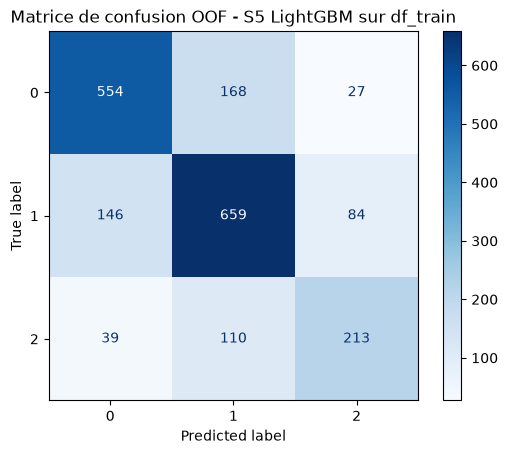

In [64]:
# Évaluation détaillée du modèle retenu sur le jeu d'entraînement par validation croisée.
# Calcul des métriques de performance, des erreurs critiques et affichage
# de la matrice de confusion à partir des prédictions OOF.
# =======================================================================================
y_pred_oof_final = cross_val_predict(estimator=modele_final,
                                     X=X_train_final,
                                     y=y_train_final,
                                     cv=cv,
                                     method="predict",
                                     n_jobs=-1)

matrice_oof_finale = confusion_matrix(y_train_final,
                                      y_pred_oof_final,
                                      labels=[0, 1, 2])

nb_reels_classe_2_oof = matrice_oof_finale[2].sum()
nb_corrects_classe_2_oof = matrice_oof_finale[2, 2]
nb_erreurs_critiques_oof = matrice_oof_finale[2, 0]
nb_erreurs_non_critiques_oof = matrice_oof_finale[2, 1]

diagnostic_cv_modele_retenu = pd.DataFrame(
    [
        {
            "jeu": "Validation croisée OOF",
            "f1_macro": f1_score(
                y_train_final,
                y_pred_oof_final,
                average="macro",
            ),
            "recall_classe_2": (
                nb_corrects_classe_2_oof / nb_reels_classe_2_oof
            ),
            "taux_erreur_critique_2_vers_0": (
                nb_erreurs_critiques_oof / nb_reels_classe_2_oof
            ),
            "nb_erreurs_critiques_2_vers_0": nb_erreurs_critiques_oof,
            "nb_erreurs_non_critiques_2_vers_1": (
                nb_erreurs_non_critiques_oof
            ),
        }
    ]
)

display(diagnostic_cv_modele_retenu.round(4))

print("Rapport détaillé OOF sur df_train :")
print(classification_report(y_train_final,
                            y_pred_oof_final,
                            labels=[0, 1, 2],
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_train_final,
                                        y_pred_oof_final,
                                        labels=[0, 1, 2],
                                        cmap="Blues")
plt.title("Matrice de confusion OOF - S5 LightGBM sur df_train")
plt.show()

,modèle,scénario,f1_macro_cv,f1_macro_test,taux_erreur_critique_cv,taux_erreur_critique_test
0,S5_LightGBM,S5,0.6955,0.7218,0.1078,0.0778


Rapport de classification sur le jeu de test :
              precision    recall  f1-score   support

           0       0.78      0.75      0.77       187
           1       0.71      0.80      0.75       223
           2       0.76      0.57      0.65        90

    accuracy                           0.74       500
   macro avg       0.75      0.71      0.72       500
weighted avg       0.74      0.74      0.74       500



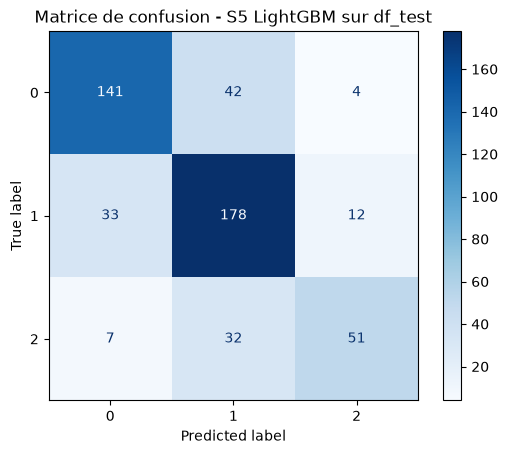

In [65]:
# Évaluation finale sur le jeu de test non utilisé
# ================================================

y_pred_test = modele_final.predict(X_test_final)

metriques_test = {"f1_macro_test": f1_score(y_test_final, y_pred_test, average="macro"),
                  "taux_erreur_critique_test": taux_erreur_critique(y_test_final, y_pred_test)}

tableau_resultats_test = pd.DataFrame(
    [
        {
            "modèle": MODELE_RETENU,
            "scénario": f"S{num_scenario_final}",
            "f1_macro_cv": configuration_finale["f1_macro_cv"],
            "f1_macro_test": metriques_test["f1_macro_test"],
            "taux_erreur_critique_cv": (
                configuration_finale["taux_erreur_critique_cv"]
            ),
            "taux_erreur_critique_test": (
                metriques_test["taux_erreur_critique_test"]
            ),
        }
    ]
)

display(tableau_resultats_test.round(4))

print("Rapport de classification sur le jeu de test :")
print(classification_report(y_test_final,
                            y_pred_test,
                            labels=[0, 1, 2],
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test_final,
                                        y_pred_test,
                                        labels=[0, 1, 2],
                                        cmap="Blues")
plt.title("Matrice de confusion - S5 LightGBM sur df_test")
plt.show()

In [66]:
# Contrôle final du disparate impact sur le jeu de test
# =====================================================
donnees_sensibles_test = df_test.loc[
    X_test_final.index,
    ["age", "nationalite_hors_ue"],
].copy()

donnees_sensibles_test["tranche_age"] = pd.cut(donnees_sensibles_test["age"],
                                               bins=[18, 30, 40, 50, 60, 70],
                                               labels=["18-29", "30-39", "40-49", "50-59", "60+"],
                                               right=False)

outcome_favorable_test = pd.Series(np.isin(y_pred_test, [0, 1]).astype(int),
                                   index=X_test_final.index)

resultats_di_test = []

for nom_attribut, colonne_groupe, groupe_reference in [
    ("age", "tranche_age", "30-39"),
    ("nationalite_hors_ue", "nationalite_hors_ue", 0),
]:
    di_test = calculer_di(groupes=donnees_sensibles_test[colonne_groupe],
                          outcome_favorable=outcome_favorable_test,
                          groupe_reference=groupe_reference,
                          nom_taux="taux_outcome_favorable_predit")

    di_test = di_test.rename(columns={colonne_groupe: "groupe",
                                      "disparate_impact": "di_predit_test"})
    di_test["attribut"] = nom_attribut
    di_test["niveau_risque_di"] = np.select(
        [
            di_test["di_predit_test"] < 0.70,
            di_test["di_predit_test"] < 0.80,
        ],
        [
            "Disparité préoccupante",
            "Vigilance",
        ],
        default="DI satisfaisant",
    )

    resultats_di_test.append(di_test)

tableau_di_test = (
    pd.concat(resultats_di_test, ignore_index=True)
    .loc[
        :,
        [
            "attribut",
            "groupe",
            "effectif",
            "taux_outcome_favorable_predit",
            "di_predit_test",
            "niveau_risque_di",
        ],
    ]
    .sort_values(["attribut", "groupe"])
    .reset_index(drop=True)
)

display(tableau_di_test.round(3))

,attribut,groupe,effectif,taux_outcome_favorable_predit,di_predit_test,niveau_risque_di
0,age,18-29,130,0.923,0.945,DI satisfaisant
1,age,30-39,85,0.976,1.000,DI satisfaisant
2,age,40-49,105,0.971,0.995,DI satisfaisant
3,age,50-59,122,0.713,0.730,Vigilance
4,age,60+,36,0.556,0.569,Disparité préoccupante
5,nationalite_hors_ue,0,444,0.892,1.000,DI satisfaisant
6,nationalite_hors_ue,1,56,0.661,0.741,Vigilance


In [67]:
# Contrôle de qualité du modèle final sur le jeu de test.
SEUILS_QUALITE = {
    # Performance minimale attendue.
    "f1_macro_min": 0.68,

    # Erreur métier critique maximale tolérée.
    "taux_erreur_critique_max": 0.12,

    # En dessous de ce DI, une revue humaine est obligatoire.
    "di_min_bloquant": 0.70,
}

controle_performance = pd.DataFrame(
    [
        {
            "métrique": "F1 macro",
            "valeur_test": metriques_test["f1_macro_test"],
            "seuil": SEUILS_QUALITE["f1_macro_min"],
            "règle": ">=",
            "statut": (
                "OK"
                if metriques_test["f1_macro_test"]
                >= SEUILS_QUALITE["f1_macro_min"]
                else "ECHEC"
            ),
        },
        {
            "métrique": "Taux d'erreur critique 2 -> 0",
            "valeur_test": metriques_test["taux_erreur_critique_test"],
            "seuil": SEUILS_QUALITE["taux_erreur_critique_max"],
            "règle": "<=",
            "statut": (
                "OK"
                if metriques_test["taux_erreur_critique_test"]
                <= SEUILS_QUALITE["taux_erreur_critique_max"]
                else "ECHEC"
            ),
        },
    ]
)

controle_equite = (
    tableau_di_test
    .assign(
        métrique=lambda table: (
            "DI - "
            + table["attribut"].astype(str)
            + " / "
            + table["groupe"].astype(str)
        ),
        valeur_test=lambda table: table["di_predit_test"],
        seuil=SEUILS_QUALITE["di_min_bloquant"],
        règle=">=",
        statut=lambda table: np.where(
            table["di_predit_test"] >= SEUILS_QUALITE["di_min_bloquant"],
            "OK",
            "ECHEC - revue humaine requise",
        ),
    )
    [["métrique", "valeur_test", "seuil", "règle", "statut"]]
)

print("Contrôle des performances")
display(controle_performance.round(3))

print("Contrôle d'équité")
display(controle_equite.round(3))

Contrôle des performances


,métrique,valeur_test,seuil,règle,statut
0,F1 macro,0.722,0.68,>=,OK
1,Taux d'erreur critique 2 -> 0,0.078,0.12,<=,OK


Contrôle d'équité


,métrique,valeur_test,seuil,règle,statut
0,DI - age / 18-29,0.945,0.7,>=,OK
1,DI - age / 30-39,1.000,0.7,>=,OK
2,DI - age / 40-49,0.995,0.7,>=,OK
3,DI - age / 50-59,0.730,0.7,>=,OK
4,DI - age / 60+,0.569,0.7,>=,ECHEC - revue humaine requise
5,DI - nationalite_hors_ue / 0,1.000,0.7,>=,OK
6,DI - nationalite_hors_ue / 1,0.741,0.7,>=,OK


## 6 📝 Synthèse modélisation - Analyse des scénarios & arbitrages

- L’analyse des F1-scores macro montre que l’ensemble des modèles évalués obtient des performances nettement supérieures à celles d’une simple prédiction basée sur la classe majoritaire, ce qui confirme leur capacité à exploiter l’information présente dans les données.

- L'analyse des différents scénarios a mis en évidence les éléments suivants :
    - L'encodage de la synthèse d'entretien comme variable catégorielle donne de meilleurs résultats que sa vectorisation avec TF-IDF
    - L'encodage ordinal du niveau de diplôme n'améliore pas les métriques observées
    - Le texte et les variables sensibles `age` et `nationalite_hors_ue` apportent de l'information prédictive. Leur retrait dégrade les performances, mais leur utilisation implique un risque d'équité qui impose le contrôle des disparates impacts

- Le modèle **LightGBM** entraîné sur le scénario **S5** (Baseline avec toutes les variables, dont le texte de synthèse encodé en variable catégorielle) a été retenu après comparaison en validation croisée avec Random Forest sur le même scénario. Il a ensuite été entraîné sur l'ensemble du jeu d'entraînement, avec les hyperparamètres sélectionnés, puis évalué sur le jeu de test indépendant.

- Sur le jeu de test, le modèle obtient un F1-score macro de **0,7218**, supérieur au score observé en validation croisée (**0,6955**). Ce score confirme une généralisation satisfaisante et ne met pas en évidence de surapprentissage. Le taux d'erreur critique entre les classes $2 \rightarrow 0$ est également comparé au seuil défini avant l'évaluation finale.

- Pour l'industrialisation, nous adoptons une stratégie de seuils **hybride** :
    - un seuil absolu de F1-score macro fixé à $0{,}68$, afin de garantir un niveau minimal de qualité prédictive ;
    - un seuil absolu de taux d'erreur critique $2 \rightarrow 0$ fixé à $12\%$, car cette erreur peut conduire à sous-estimer les besoins d'accompagnement d'un usager ;
    - une tolérance relative initiale de $0{,}018$ est retenue pour le F1-score macro. Cette valeur est égale à deux fois l'écart-type observé en validation croisée stratifiée ($2 \times 0{,}0089 = 0{,}0178$). 
    - Le seuil relatif sera appliqué aux versions ultérieures par comparaison avec un jeu de référence figé. Cette tolérance devra être recalibré par bootstrap sur ce jeu de référence.

- Le contrôle d'équité met en évidence au moins un disparate impact inférieur au seuil bloquant de $0{,}70$. En particulier, les résultats doivent être examinés avec vigilance pour les groupes présentant une disparité préoccupante. Le modèle ne doit donc pas être utilisé pour prendre une décision entièrement automatisée.

- Le modèle peut être envisagé comme une **aide à la décision sous supervision humaine** : la prédiction doit être interprétée par un conseiller, en particulier pour les situations associées à un risque de retour à l'emploi de longue durée et pour les groupes identifiés comme sensibles dans l'analyse d'équité.

En conclusion, le modèle obtenu avec le scénario **S5 LightGBM**  est validé comme **composant d'aide à la décision**, mais pas comme outil de décision autonome. Son déploiement devra s'accompagner d'une supervision humaine, d'un suivi régulier des erreurs critiques et d'un contrôle périodique des indicateurs d'équité par âge et nationalité.

---
## 7. Interprétation pour la communication client

### 7.1 Importance globale des variables

In [68]:
# Calcul de l'importance des variables dans les predictions
preprocessor_final = modele_final.named_steps["preprocessor"]
modele_lightgbm_final = modele_final.named_steps["model"]

noms_features_transformees = preprocessor_final.get_feature_names_out()

importance_features = (
    pd.DataFrame(
        {
            "feature_transformee": noms_features_transformees,
            "importance": modele_lightgbm_final.feature_importances_,
        }
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Variables transformées les plus importantes")
display(importance_features.head(10))

Variables transformées les plus importantes


,feature_transformee,importance
0,num__anciennete_poste_ans,4664
1,num__age,3975
2,cat__niveau_diplome_Bac,402
3,cat__est_allocataire_0.0,363
4,cat__niveau_diplome_Sans diplôme,355
5,cat__nationalite_hors_ue_0,335
6,cat__niveau_diplome_Bac+5,279
7,"cat__synthese_entretien_Profil autonome, reche...",244
8,cat__synthese_entretien_Cumul de difficultés. ...,220
9,cat__synthese_entretien_Candidat très dynamiqu...,217


In [69]:
# Agrégation des importances par variable d'origine.
def retrouver_feature_origine(nom_feature: str) -> str:
    """Regroupe les colonnes transformées sous leur variable d'origine."""
    nom_sans_prefixe = nom_feature.split("__", maxsplit=1)[-1]

    for feature in (
        numeric_features
        + categorical_features
        + ordinal_features
        + ([text_feature] if text_feature is not None else [])
    ):
        if nom_sans_prefixe == feature or nom_sans_prefixe.startswith(f"{feature}_"):
            return feature

    return nom_sans_prefixe


importance_features["feature_origine"] = (
    importance_features["feature_transformee"]
    .map(retrouver_feature_origine)
)

importance_par_feature = (
    importance_features
    .groupby("feature_origine", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

importance_par_feature["importance_relative_pct"] = (
    100
    * importance_par_feature["importance"]
    / importance_par_feature["importance"].sum()
)

print("Importance agrégée par variable d'origine")
display(importance_par_feature.round(2))

Importance agrégée par variable d'origine


,feature_origine,importance,importance_relative_pct
0,anciennete_poste_ans,4664,25.91
1,age,3975,22.08
2,code_rome_vise,3488,19.38
3,departement,1910,10.61
4,synthese_entretien,1795,9.97
5,niveau_diplome,1251,6.95
6,est_allocataire,558,3.10
7,nationalite_hors_ue,359,1.99


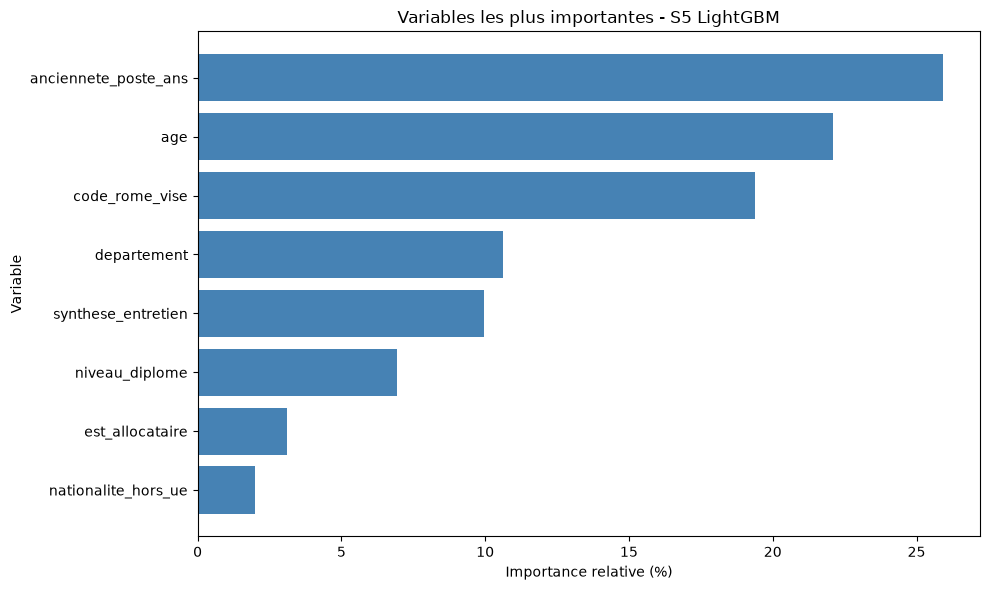

In [70]:
# Représentation de l'importance des variables d'origine
top_features = importance_par_feature.head(15).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature_origine"],
    top_features["importance_relative_pct"],
    color="steelblue",
)
plt.xlabel("Importance relative (%)")
plt.ylabel("Variable")
plt.title("Variables les plus importantes - S5 LightGBM")
plt.tight_layout()
plt.show()

### 7.2 Analyse SHAP du modèle final pour la classe 2 : risque de retour à l'emploi de longue durée.

In [71]:
# Preparation des données non vues
X_test_transforme = preprocessor_final.transform(X_test_final)
noms_features_transformees = preprocessor_final.get_feature_names_out()

# Le test compte 500 lignes : il peut être expliqué intégralement.
# Conversion dense nécessaire pour les graphiques SHAP.
X_test_shap = pd.DataFrame(
    X_test_transforme.toarray(),
    columns=noms_features_transformees,
    index=X_test_final.index,
)

explainer = shap.TreeExplainer(modele_lightgbm_final)
valeurs_shap = explainer(X_test_shap)

print(f"Forme des valeurs SHAP : {valeurs_shap.values.shape}")

Forme des valeurs SHAP : (500, 168, 3)


In [72]:
# Contributions SHAP associées à la classe 2.
shap_classe_2 = shap.Explanation(
    values=valeurs_shap.values[:, :, 2],
    base_values=valeurs_shap.base_values[:, 2],
    data=X_test_shap.to_numpy(),
    feature_names=noms_features_transformees,
)

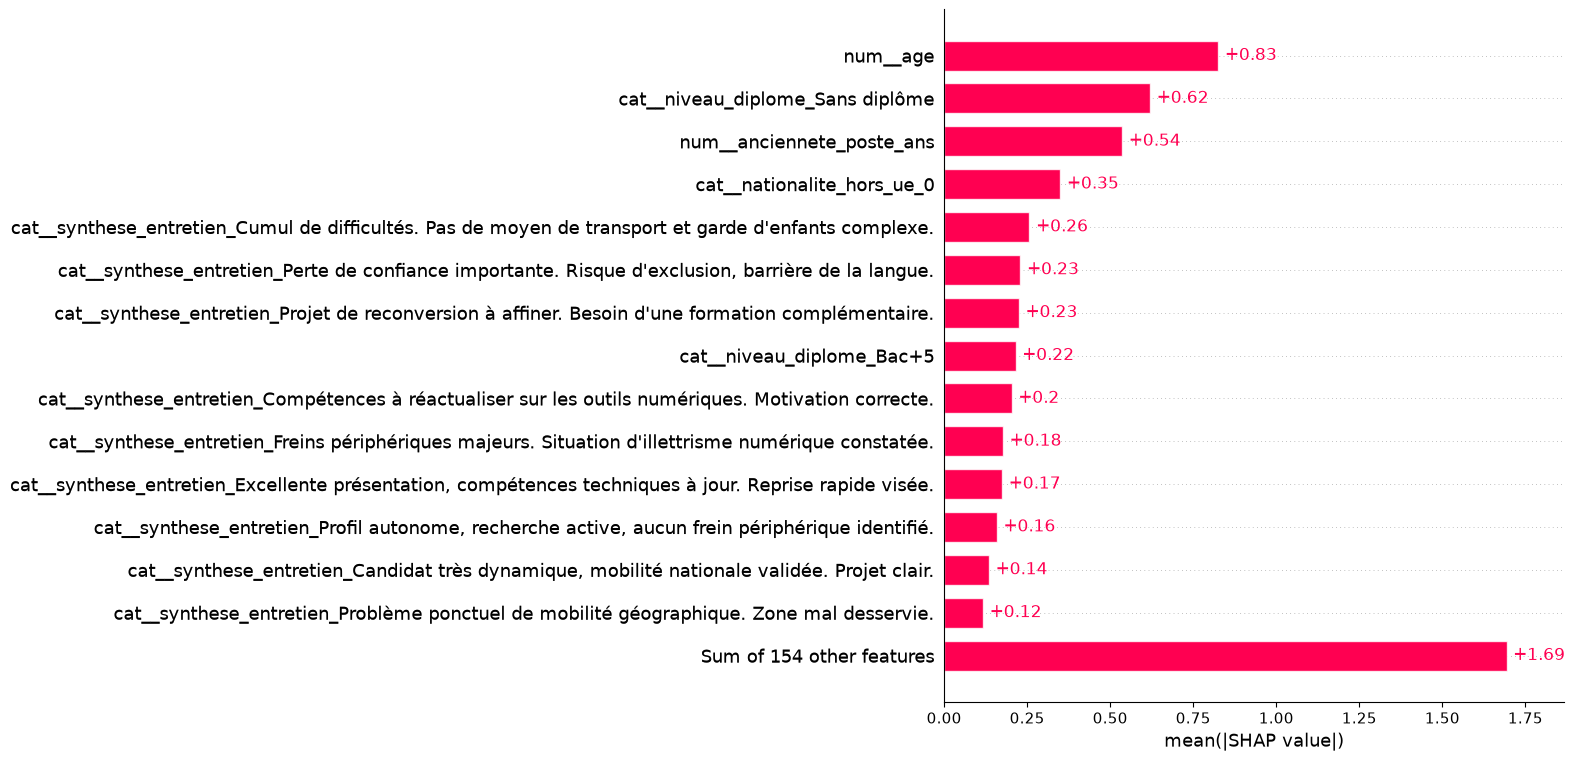

In [73]:
# Les variables les plus influentes sur la prédiction de la classe 2.
shap.plots.bar(shap_classe_2, max_display=15)

In [74]:
# Contribution moyenne de l'âge et de l'ancienneté
# vers la classe 2, par quartile observé sur le jeu de test.
def contribution_par_quartile(variable: str) -> pd.DataFrame:
    nom_feature_transformee = next(
        nom
        for nom in noms_features_transformees
        if nom.endswith(f"__{variable}")
    )

    position_feature = list(noms_features_transformees).index(
        nom_feature_transformee
    )

    analyse = pd.DataFrame(
        {
            variable: X_test_final[variable],
            "contribution_shap_classe_2": (
                shap_classe_2.values[:, position_feature]
            ),
        }
    )

    analyse["quartile"] = pd.qcut(
        analyse[variable],
        q=4,
        duplicates="drop",
    )

    return (
        analyse
        .groupby("quartile", observed=False)
        .agg(
            valeur_moyenne=(variable, "mean"),
            contribution_shap_moyenne=(
                "contribution_shap_classe_2",
                "mean",
            ),
            effectif=(variable, "size"),
        )
        .round(3)
    )

print("Effet de l'âge sur la classe 2")
display(contribution_par_quartile("age"))

print("Effet de l'ancienneté sur la classe 2")
display(contribution_par_quartile("anciennete_poste_ans"))

Effet de l'âge sur la classe 2


,valeur_moyenne,contribution_shap_moyenne,effectif
quartile,,,
"(17.999, 29.0]",23.746,-0.284,130
"(29.0, 41.5]",35.734,-0.572,109
"(41.5, 52.75]",47.067,-0.349,119
"(52.75, 63.0]",57.792,1.640,120


Effet de l'ancienneté sur la classe 2


,valeur_moyenne,contribution_shap_moyenne,effectif
quartile,,,
"(-0.001, 0.8]",0.438,-0.260,126
"(0.8, 1.9]",1.404,0.198,132
"(1.9, 4.125]",2.892,-0.070,117
"(4.125, 22.0]",7.296,0.188,125


In [75]:
# Contribution SHAP moyenne de la nationalité vers la classe 2.
nom_feature_nationalite = next(
    nom
    for nom in noms_features_transformees
    if nom.endswith("__nationalite_hors_ue_1")
)

position_feature_nationalite = list(noms_features_transformees).index(
    nom_feature_nationalite
)

analyse_nationalite = pd.DataFrame(
    {
        "nationalite_hors_ue": X_test_final["nationalite_hors_ue"],
        "contribution_shap_classe_2": (
            shap_classe_2.values[:, position_feature_nationalite]
        ),
    }
)

analyse_nationalite["groupe_nationalite"] = np.where(
    analyse_nationalite["nationalite_hors_ue"].eq(1),
    "Hors UE",
    "UE",
)

contribution_nationalite = (
    analyse_nationalite
    .groupby("groupe_nationalite", as_index=False)
    .agg(
        effectif=("nationalite_hors_ue", "size"),
        contribution_shap_moyenne=(
            "contribution_shap_classe_2",
            "mean",
        ),
        contribution_shap_mediane=(
            "contribution_shap_classe_2",
            "median",
        ),
    )
    .sort_values("groupe_nationalite")
)

display(contribution_nationalite.round(3))

,groupe_nationalite,effectif,contribution_shap_moyenne,contribution_shap_mediane
0,Hors UE,56,0.059,0.052
1,UE,444,-0.008,-0.006


### Conclusion

**Analyse globale**

- Les variables les plus fréquemment utilisées par LightGBM pour créer des séparations dans les arbres sont `anciennete_poste_ans` et `age`
- La variable `nationalite_hors_ue` occupe la 8ème position avec une importance relative d'environ $2{,}5\%$. Elle contribue donc moins aux séparations que les variables principales, mais reste utilisée par le modèle.

**Analyse des décisions pour la classe 2**

- En valeur absolue, la variable `age` (1ère) et la modalité `nationalite_hors_ue=0` (4ème) figurent parmi les contributions SHAP les plus importantes aux prédictions de la classe 2.
- La modalité `niveau_diplome=sans_diplome` (2ème) et la variable `anciennete_poste_ans` (3ème) font également partie des variables les plus influentes.

- L'analyse du sens des contributions montre :
     - qu'un âge supérieur à 53 ans pousse fortement la prédiction vers la classe 2 ($+1{,}640$), tandis que les autres tranches d'âge l'éloignent avec des contributions comprises entre $-0{,}572$ et $-0{,}284$ ;
    - que l'ancienneté a un effet modéré et non linéaire sur la prédiction de classe 2, avec des contributions moyennes comprises entre $-0{,}260$ et $+0{,}198$ ;
    - que l'appartenance au groupe hors UE contribue légèrement, en moyenne, à la prédiction de classe 2 ($+0{,}059$), alors que la contribution moyenne du groupe UE est quasi nulle ($-0{,}008$).

L'analyse SHAP complète l'analyse de disparate impact en éclairant le mécanisme de décision du modèle. Les disparités observées selon l'âge et la nationalité ne semblent pas résulter d'une règle linéaire ou déterministe fondée sur une seule variable sensible.

En effet, l'âge présente un effet non linéaire : les classes d'âge intermédiaires contribuent négativement au score de classe 2, tandis que seule la tranche d'âge la plus élevée contribue fortement et positivement. De même, la nationalité hors UE présente une contribution moyenne faible par rapport aux principaux facteurs utilisés par le modèle.

Les décisions de LightGBM reposent sur une combinaison de caractéristiques : ancienneté dans le poste, niveau de diplôme, métier visé, synthèse d'entretien, âge et, dans une moindre mesure, nationalité. Le modèle ne fonde donc pas ses prédictions sur un unique attribut sensible. 

Cette diversité de facteurs, combinée aux performances obtenues sur le jeu de test et à l'analyse des contributions SHAP, renforce l'éligibilité du modèle à une utilisation en production comme outil d'aide à la décision. Le modèle ne doit toutefois pas être utilisé de manière autonome : les recommandations concernant les groupes pour lesquels le disparate impact est défavorable doivent faire l'objet d'une vigilance renforcée et d'une validation par un conseiller.


### 7.3 Analyse des erreurs et stratégies de fallback

In [76]:
# Probabilités OOF : chaque dossier est évalué par un modèle
# qui n'a pas été entraîné sur lui
probabilites_oof_final = cross_val_predict(estimator=modele_final,
                                           X=X_train_final,
                                           y=y_train_final,
                                           cv=cv,
                                           method="predict_proba",
                                           n_jobs=-1)

classe_predite_oof = probabilites_oof_final.argmax(axis=1)
confiance_max_oof = probabilites_oof_final.max(axis=1)

analyse_confiance_oof = pd.DataFrame(
    {
        "classe_reelle": np.asarray(y_train_final),
        "classe_predite": classe_predite_oof,
        "proba_classe_0": probabilites_oof_final[:, 0],
        "proba_classe_1": probabilites_oof_final[:, 1],
        "proba_classe_2": probabilites_oof_final[:, 2],
        "confiance_max": confiance_max_oof,
    },
    index=X_train_final.index,
)

analyse_confiance_oof["erreur_critique_2_vers_0"] = (
    analyse_confiance_oof["classe_reelle"].eq(2)
    & analyse_confiance_oof["classe_predite"].eq(0)
)

In [77]:
# Application du filet de sécurité
SEUIL_ABSTENTION = 0.60
SEUIL_REVUE_CLASSE_0 = 0.80

analyse_politique = analyse_confiance_oof.copy()

analyse_politique["niveau_traitement"] = np.select(
    [
        # Priorité 1 : le modèle hésite, aucune recommandation automatique.
        analyse_politique["confiance_max"].lt(SEUIL_ABSTENTION),

        # Priorité 2 : retour rapide prédit, mais confiance insuffisante.
        (
            analyse_politique["classe_predite"].eq(0)
            & analyse_politique["proba_classe_0"].lt(
                SEUIL_REVUE_CLASSE_0
            )
        ),
    ],
    [
        "Abstention",
        "Revue humaine renforcée",
    ],
    default="Acceptation assistée",
)

analyse_politique["est_erreur"] = (
    analyse_politique["classe_reelle"]
    != analyse_politique["classe_predite"]
)

analyse_politique["est_erreur_critique"] = (
    analyse_politique["classe_reelle"].eq(2)
    & analyse_politique["classe_predite"].eq(0)
)

dossiers_acceptes = (
    analyse_politique["niveau_traitement"]
    .eq("Acceptation assistée")
)

dossiers_abstention_ou_revue = ~dossiers_acceptes

erreurs_critiques_totales = (
    analyse_politique["est_erreur_critique"]
    .sum()
)

erreurs_critiques_protegees = (
    analyse_politique["est_erreur_critique"]
    & dossiers_abstention_ou_revue
).sum()

### 7.3.1 Baseline métier

In [78]:
# Baseline métier : règle simple fondée uniquement sur le commentaire d'entretien.
# Les libellés doivent être ceux présents exactement dans le jeu de données
COMMENTAIRES_POSITIFS = [
    "Excellente présentation, compétences techniques à jour. Reprise rapide visée.",
]

COMMENTAIRES_NEGATIFS = [
    "Cumul de difficultés. Pas de moyen de transport et garde d'enfants complexe.",
    "Freins périphériques majeurs. Situation d'illettrisme numérique constatée.",
    "Perte de confiance importante. Risque d'exclusion, barrière de la langue.",
]

baseline_commentaire = pd.DataFrame(
    {
        "classe_reelle": np.asarray(y_train_final),
        "classe_predite_modele": analyse_politique["classe_predite"].to_numpy(),
        "niveau_modele": analyse_politique["niveau_traitement"].to_numpy(),
        "synthese_entretien": X_train_final["synthese_entretien"].to_numpy(),
    },
    index=X_train_final.index,
)

baseline_commentaire["classe_predite_commentaire"] = np.select(
    [
        baseline_commentaire["synthese_entretien"].isin(
            COMMENTAIRES_POSITIFS
        ),
        baseline_commentaire["synthese_entretien"].isin(
            COMMENTAIRES_NEGATIFS
        ),
    ],
    [
        0,
        2,
    ],
    default=np.nan,
)

# Seuls les dossiers auxquels la règle textuelle attribue une classe
# sont comparés : elle ne couvre donc pas nécessairement tous les dossiers.
dossiers_couverts = (
    baseline_commentaire["classe_predite_commentaire"]
    .notna()
)

evaluation_commentaire = baseline_commentaire.loc[
    dossiers_couverts
].copy()

evaluation_commentaire["classe_predite_commentaire"] = (
    evaluation_commentaire["classe_predite_commentaire"]
    .astype(int)
)

resume_commentaires = (
    evaluation_commentaire
    .assign(
        prediction_correcte=lambda table: (
            table["classe_reelle"]
            .eq(table["classe_predite_commentaire"])
        ),
        erreur_critique_2_vers_0=lambda table: (
            table["classe_reelle"].eq(2)
            & table["classe_predite_commentaire"].eq(0)
        ),
    )
    .groupby("classe_predite_commentaire", as_index=False)
    .agg(
        effectif=("classe_reelle", "size"),
        nb_predictions_correctes=("prediction_correcte", "sum"),
        precision=("prediction_correcte", "mean"),
        nb_erreurs_critiques_2_vers_0=(
            "erreur_critique_2_vers_0",
            "sum",
        ),
    )
    .replace(
        {
            "classe_predite_commentaire": {
                0: "Commentaire positif -> classe 0",
                2: "Commentaire négatif -> classe 2",
            }
        }
    )
)

display(resume_commentaires.round(3))

,classe_predite_commentaire,effectif,nb_predictions_correctes,precision,nb_erreurs_critiques_2_vers_0
0,Commentaire positif -> classe 0,219,156,0.712,19
1,Commentaire négatif -> classe 2,520,239,0.460,0


In [79]:
comparaison_modele_commentaire = (
    evaluation_commentaire
    .assign(
        prediction_correcte_commentaire=lambda table: (
            table["classe_reelle"]
            .eq(table["classe_predite_commentaire"])
        ),
        prediction_correcte_modele=lambda table: (
            table["classe_reelle"]
            .eq(table["classe_predite_modele"])
        ),
        erreur_critique_commentaire=lambda table: (
            table["classe_reelle"].eq(2)
            & table["classe_predite_commentaire"].eq(0)
        ),
        erreur_critique_modele=lambda table: (
            table["classe_reelle"].eq(2)
            & table["classe_predite_modele"].eq(0)
        ),
    )
)

tableau_comparaison = pd.DataFrame(
    {
        "approche": [
            "Règle fondée sur le commentaire",
            "Modèle LightGBM",
        ],
        "dossiers_comparés": [
            len(comparaison_modele_commentaire),
            len(comparaison_modele_commentaire),
        ],
        "accuracy": [
            comparaison_modele_commentaire[
                "prediction_correcte_commentaire"
            ].mean(),
            comparaison_modele_commentaire[
                "prediction_correcte_modele"
            ].mean(),
        ],
        "erreurs_critiques_2_vers_0": [
            comparaison_modele_commentaire[
                "erreur_critique_commentaire"
            ].sum(),
            comparaison_modele_commentaire[
                "erreur_critique_modele"
            ].sum(),
        ],
    }
)

display(tableau_comparaison.round(3))

,approche,dossiers_comparés,accuracy,erreurs_critiques_2_vers_0
0,Règle fondée sur le commentaire,739,0.535,19
1,Modèle LightGBM,739,0.660,23


**Conclusion**

La règle métier fondée sur la synthèse d’entretien constitue une baseline simple et interprétable. Elle fournit une référence minimale, mais sa couverture est limitée et elle s’appuie sur une information isolée.

Le modèle LightGBM dépasse cette baseline en mobilisant l’ensemble des informations disponibles dans le dossier. Cette combinaison améliore la qualité des prédictions tout en limitant les erreurs critiques de type $2 \rightarrow 0$.

In [80]:
# 7.2 Analyse des erreurs et profils à escalader
# - Matrice de confusion détaillée par profil (variables sensibles incluses)
# - Distribution des probabilités prédites sur les erreurs : où placer le seuil de rejet ?
# - Caractérisation des profils faux positifs / faux négatifs : escalade humaine prioritaire ?

#### 7.3.2 Validation des seuils

In [81]:
# Part des dossiers à revoir / erreurs critiques capturées
seuils = np.arange(0.40, 0.96, 0.05)
resultats_seuils = []

for seuil in seuils:
    dossiers_a_revoir = (
        analyse_confiance_oof["classe_predite"].eq(0)
        & analyse_confiance_oof["proba_classe_0"].lt(seuil)
    )

    erreurs_critiques_totales = (
        analyse_confiance_oof["erreur_critique_2_vers_0"].sum()
    )

    erreurs_critiques_capturees = (
        analyse_confiance_oof["erreur_critique_2_vers_0"]
        & dossiers_a_revoir
    ).sum()

    resultats_seuils.append(
        {
            "seuil_revue_classe_0": seuil,
            "dossiers_a_revoir": dossiers_a_revoir.sum(),
            "part_train_a_revoir": dossiers_a_revoir.mean(),
            "erreurs_critiques_capturees": erreurs_critiques_capturees,
            "part_erreurs_critiques_capturees": (
                erreurs_critiques_capturees / erreurs_critiques_totales
                if erreurs_critiques_totales > 0
                else np.nan
            ),
        }
    )

tableau_seuils_revue = pd.DataFrame(resultats_seuils)

display(tableau_seuils_revue.round(3))

,seuil_revue_classe_0,dossiers_a_revoir,part_train_a_revoir,erreurs_critiques_capturees,part_erreurs_critiques_capturees
0,0.40,2,0.001,2,0.051
1,0.45,9,0.004,4,0.103
2,0.50,21,0.010,7,0.179
3,0.55,50,0.025,8,0.205
4,0.60,76,0.038,8,0.205
5,0.65,106,0.053,11,0.282
6,0.70,134,0.067,13,0.333
7,0.75,156,0.078,15,0.385
8,0.80,202,0.101,20,0.513
9,0.85,250,0.125,22,0.564


In [82]:
# Évaluation de seuils d'abstention sur toutes les classes.
# Une abstention signifie : aucune recommandation automatique, la décision reviens au conseiller.
seuils_abstention = np.arange(0.40, 0.91, 0.05)

resultats_abstention = []

erreur_prediction_oof = (
    analyse_confiance_oof["classe_reelle"]
    != analyse_confiance_oof["classe_predite"]
)

erreur_critique_oof = (
    analyse_confiance_oof["classe_reelle"].eq(2)
    & analyse_confiance_oof["classe_predite"].eq(0)
)

for seuil in seuils_abstention:
    abstention = analyse_confiance_oof["confiance_max"].lt(seuil)
    predictions_acceptees = ~abstention

    erreurs_capturees = (erreur_prediction_oof & abstention).sum()
    erreurs_critiques_capturees = (erreur_critique_oof & abstention).sum()

    erreurs_critiques_restantes = (
        erreur_critique_oof & predictions_acceptees
    ).sum()

    resultats_abstention.append(
        {
            "seuil_abstention": seuil,
            "dossiers_en_abstention": abstention.sum(),
            "part_dossiers_en_abstention": abstention.mean(),
            "dossiers_avec_recommandation": predictions_acceptees.sum(),
            "part_dossiers_avec_recommandation": (
                predictions_acceptees.mean()
            ),
            "accuracy_predictions_acceptees": (
                (
                    analyse_confiance_oof.loc[
                        predictions_acceptees,
                        "classe_reelle",
                    ]
                    == analyse_confiance_oof.loc[
                        predictions_acceptees,
                        "classe_predite",
                    ]
                ).mean()
            ),
            "erreurs_capturees": erreurs_capturees,
            "part_erreurs_capturees": (
                erreurs_capturees / erreur_prediction_oof.sum()
            ),
            "erreurs_critiques_capturees": (
                erreurs_critiques_capturees
            ),
            "part_erreurs_critiques_capturees": (
                erreurs_critiques_capturees / erreur_critique_oof.sum()
                if erreur_critique_oof.sum() > 0
                else np.nan
            ),
            "erreurs_critiques_restantes": (
                erreurs_critiques_restantes
            ),
        }
    )

tableau_seuils_abstention = pd.DataFrame(resultats_abstention)

display(tableau_seuils_abstention.round(3))

,seuil_abstention,dossiers_en_abstention,part_dossiers_en_abstention,dossiers_avec_recommandation,part_dossiers_avec_recommandation,accuracy_predictions_acceptees,erreurs_capturees,part_erreurs_capturees,erreurs_critiques_capturees,part_erreurs_critiques_capturees,erreurs_critiques_restantes
0,0.40,12,0.006,1988,0.994,0.716,9,0.016,2,0.051,37
1,0.45,35,0.018,1965,0.982,0.720,23,0.040,4,0.103,35
2,0.50,72,0.036,1928,0.964,0.724,41,0.071,7,0.179,32
3,0.55,164,0.082,1836,0.918,0.736,90,0.157,8,0.205,31
4,0.60,234,0.117,1766,0.883,0.746,126,0.220,8,0.205,31
5,0.65,324,0.162,1676,0.838,0.758,169,0.294,11,0.282,28
6,0.70,415,0.208,1585,0.792,0.770,210,0.366,13,0.333,26
7,0.75,499,0.250,1501,0.750,0.787,254,0.443,15,0.385,24
8,0.80,630,0.315,1370,0.685,0.804,306,0.533,20,0.513,19
9,0.85,772,0.386,1228,0.614,0.827,362,0.631,22,0.564,17


In [83]:
# Évaluation de la politique complète de décision :
# abstention, revue humaine renforcée et acceptation assistée.
tableau_politique = (
    analyse_politique
    .groupby("niveau_traitement", as_index=False)
    .agg(
        dossiers=("classe_reelle", "size"),
        erreurs_modele=("est_erreur", "sum"),
        erreurs_critiques_2_vers_0=("est_erreur_critique", "sum"),
    )
)

ordre_niveaux = [
    "Abstention",
    "Revue humaine renforcée",
    "Acceptation assistée",
]

tableau_politique["niveau_traitement"] = pd.Categorical(
    tableau_politique["niveau_traitement"],
    categories=ordre_niveaux,
    ordered=True,
)

tableau_politique = (
    tableau_politique
    .sort_values("niveau_traitement")
    .reset_index(drop=True)
)

tableau_politique["part_des_dossiers"] = (
    tableau_politique["dossiers"]
    / len(analyse_politique)
)

tableau_politique["taux_erreur_modele"] = (
    tableau_politique["erreurs_modele"]
    / tableau_politique["dossiers"]
)

tableau_politique["part_erreurs_critiques"] = (
    tableau_politique["erreurs_critiques_2_vers_0"]
    / analyse_politique["est_erreur_critique"].sum()
)

display(
    tableau_politique[
        [
            "niveau_traitement",
            "dossiers",
            "part_des_dossiers",
            "erreurs_modele",
            "taux_erreur_modele",
            "erreurs_critiques_2_vers_0",
            "part_erreurs_critiques",
        ]
    ].round(3)
)

,niveau_traitement,dossiers,part_des_dossiers,erreurs_modele,taux_erreur_modele,erreurs_critiques_2_vers_0,part_erreurs_critiques
0,Abstention,234,0.117,126,0.538,8,0.205
1,Revue humaine renforcée,126,0.063,48,0.381,12,0.308
2,Acceptation assistée,1640,0.820,400,0.244,19,0.487


In [84]:
# Tableau de synthèse
nb_dossiers = len(analyse_politique)

nb_abstention = (
    analyse_politique["niveau_traitement"]
    .eq("Abstention")
    .sum()
)

nb_revue_renforcee = (
    analyse_politique["niveau_traitement"]
    .eq("Revue humaine renforcée")
    .sum()
)

nb_acceptation_assistee = dossiers_acceptes.sum()
nb_intervention_humaine = dossiers_abstention_ou_revue.sum()

nb_erreurs_critiques_restantes = (
    analyse_politique["est_erreur_critique"]
    & dossiers_acceptes
).sum()

accuracy_acceptation_assistee = (
    analyse_politique.loc[dossiers_acceptes, "classe_reelle"]
    == analyse_politique.loc[dossiers_acceptes, "classe_predite"]
).mean()

tableau_synthese_politique = pd.DataFrame(
    {
        "indicateur": [
        "Dossiers soumis à une revue humaine obligatoire",
        "dont : abstention du modèle",
        "dont : revue humaine renforcée",
        "Dossiers avec acceptation assistée",
        "Erreurs critiques protégées par la politique",
        "Erreurs critiques restant dans le flux assisté",
        "Accuracy des recommandations acceptées",
    ],
    "effectif": [
        nb_intervention_humaine,
        nb_abstention,
        nb_revue_renforcee,
        nb_acceptation_assistee,
        erreurs_critiques_protegees,
        nb_erreurs_critiques_restantes,
        np.nan,
    ],
    "proportion": [
        nb_intervention_humaine / nb_dossiers,
        nb_abstention / nb_dossiers,
        nb_revue_renforcee / nb_dossiers,
        nb_acceptation_assistee / nb_dossiers,
        erreurs_critiques_protegees / erreurs_critiques_totales,
        nb_erreurs_critiques_restantes / erreurs_critiques_totales,
        accuracy_acceptation_assistee,
    ],
    }
)

tableau_synthese_politique["effectif"] = (
    tableau_synthese_politique["effectif"]
    .astype("Int64")
)

tableau_synthese_politique["proportion"] = (
    tableau_synthese_politique["proportion"]
    .map(lambda valeur: f"{valeur:.1%}")
)

display(tableau_synthese_politique)

,indicateur,effectif,proportion
0,Dossiers soumis à une revue humaine obligatoire,360,18.0%
1,dont : abstention du modèle,234,11.7%
2,dont : revue humaine renforcée,126,6.3%
3,Dossiers avec acceptation assistée,1640,82.0%
4,Erreurs critiques protégées par la politique,20,51.3%
5,Erreurs critiques restant dans le flux assisté,19,48.7%
6,Accuracy des recommandations acceptées,<NA>,75.6%


In [85]:
# Revue complémentaire : le modèle prédit la classe 0,
# mais attribue également une probabilité non négligeable à la classe 2.

seuils_p2 = [0.10, 0.20, 0.30]
resultats_seuils_p2 = []

erreurs_critiques = analyse_confiance_oof["erreur_critique_2_vers_0"]

for seuil_p2 in seuils_p2:
    dossiers_a_revoir_p2 = (
        analyse_confiance_oof["classe_predite"].eq(0)
        & analyse_confiance_oof["proba_classe_2"].ge(seuil_p2)
    )

    erreurs_critiques_capturees_p2 = (
        erreurs_critiques & dossiers_a_revoir_p2
    ).sum()

    resultats_seuils_p2.append(
        {
            "seuil_p2": seuil_p2,
            "dossiers_a_revoir": dossiers_a_revoir_p2.sum(),
            "part_dossiers_a_revoir": dossiers_a_revoir_p2.mean(),
            "erreurs_critiques_2_vers_0_capturees": (
                erreurs_critiques_capturees_p2
            ),
            "part_erreurs_critiques_capturees": (
                erreurs_critiques_capturees_p2 / erreurs_critiques.sum()
                if erreurs_critiques.sum() > 0
                else np.nan
            ),
        }
    )

tableau_seuils_p2 = pd.DataFrame(resultats_seuils_p2)

display(tableau_seuils_p2.round(3))

,seuil_p2,dossiers_a_revoir,part_dossiers_a_revoir,erreurs_critiques_2_vers_0_capturees,part_erreurs_critiques_capturees
0,0.1,55,0.028,10,0.256
1,0.2,27,0.014,7,0.179
2,0.3,14,0.007,3,0.077


In [86]:
# Comparaison entre la règle actuelle et la règle complémentaire p2 >= 0,10.

regle_abstention = analyse_confiance_oof["confiance_max"].lt(0.60)

regle_revue_p0 = (
    analyse_confiance_oof["classe_predite"].eq(0)
    & analyse_confiance_oof["proba_classe_0"].lt(0.80)
)

regle_p2 = (
    analyse_confiance_oof["classe_predite"].eq(0)
    & analyse_confiance_oof["proba_classe_2"].ge(0.10)
)

regle_actuelle = regle_abstention | regle_revue_p0
regle_complete = regle_actuelle | regle_p2

erreurs_critiques = analyse_confiance_oof["erreur_critique_2_vers_0"]

tableau_comparaison_regles = pd.DataFrame(
    {
        "indicateur": [
            "Dossiers capturés par la règle p2 >= 0,10",
            "Dont déjà capturés par la règle actuelle",
            "Nouveaux dossiers ajoutés par la règle p2",
            "Erreurs critiques capturées par la règle p2",
            "Dont déjà capturées par la règle actuelle",
            "Nouvelles erreurs critiques capturées grâce à p2",
            "Erreurs critiques capturées par la règle actuelle",
            "Erreurs critiques capturées par la règle complète",
        ],
        "effectif": [
            regle_p2.sum(),
            (regle_p2 & regle_actuelle).sum(),
            (regle_p2 & ~regle_actuelle).sum(),
            (regle_p2 & erreurs_critiques).sum(),
            (regle_p2 & erreurs_critiques & regle_actuelle).sum(),
            (regle_p2 & erreurs_critiques & ~regle_actuelle).sum(),
            (regle_actuelle & erreurs_critiques).sum(),
            (regle_complete & erreurs_critiques).sum(),
        ],
    }
)

display(tableau_comparaison_regles)

,indicateur,effectif
0,"Dossiers capturés par la règle p2 >= 0,10",55
1,Dont déjà capturés par la règle actuelle,51
2,Nouveaux dossiers ajoutés par la règle p2,4
3,Erreurs critiques capturées par la règle p2,10
4,Dont déjà capturées par la règle actuelle,10
5,Nouvelles erreurs critiques capturées grâce à p2,0
6,Erreurs critiques capturées par la règle actuelle,20
7,Erreurs critiques capturées par la règle complète,20


**Conclusion**

La capacité de traitement humain est fixée à un maximum de **20 % des dossiers**
envoyés en revue ou en abstention.

Avec un seuil d’abstention de $0{,}60$ et un seuil de revue renforcée de
$p_0 < 0{,}80$ pour les prédictions de classe `0`, la politique envoie
**18 %** des dossiers vers un conseiller et intercepte **51,3 %** des erreurs
critiques de type $2 \rightarrow 0$.

La règle « classe prédite 0 et $p_2 \geq 0{,}10$ » cible 55 dossiers, dont 51
sont déjà orientés vers l'abstention ou la revue humaine renforcée par la
politique existante. Les quatre dossiers supplémentaires ne correspondent à
aucune erreur critique de type $2 \rightarrow 0$.

La règle fondée sur $p_2$ ne procure donc aucun gain mesurable tout en augmentant la charge de revue. Elle n'est pas retenue dans la politique de production.

Le compromis seuil d’abstention de $0{,}60$ et seuil de revue renforcée de
$p_0 < 0{,}80$ est retenu car il réduit les erreurs les plus préjudiciables
sans transférer une proportion excessive de dossiers vers la revue humaine.
Les dossiers acceptés restent une aide à la décision : le conseiller conserve
la décision finale.

### Règles recommandées

| Niveau | Règle | Traitement |
|---|---|---|
| Abstention | Confiance maximale $< 0{,}60$, quelle que soit la classe prédite. | Aucune recommandation automatique ; examen complet obligatoire par un conseiller. |
| Revue humaine renforcée | Classe prédite `0`, avec un score de classe 0 compris entre $0{,}60$ et $0{,}80$. | La recommandation de retour rapide est affichée comme incertaine ; le conseiller vérifie les freins, le parcours et les informations d'entretien avant orientation. |
| Acceptation assistée | Classe prédite `0` avec $p_0 \geq 0{,}80$, ou prédiction de classe `1` ou `2` avec une confiance maximale $\geq 0{,}60$. | Recommandation disponible comme aide à l'orientation ; le conseiller conserve la décision finale. |

### 7.4 Message au client

L'outil aide les conseillers à identifier les situations nécessitant un accompagnement renforcé pour favoriser le retour à l'emploi. Il propose une orientation parmi un retour rapide, intermédiaire ou un risque de retour à l'emploi de longue durée.

Le système automatise une première lecture de $82\%$ des dossiers, tout en transmettant $18\%$ des situations les moins sûres à une revue humaine. Cette organisation permet de sécuriser les recommandations lorsque les informations disponibles ne permettent pas au modèle de proposer une orientation suffisamment fiable.

L'outil ne remplace pas le conseiller. Celui-ci conserve la décision d'orientation et examine en priorité les dossiers sans recommandation automatique ou signalés pour revue renforcée.

### 7.5 📝 Synthèse interprétation

Le modèle combine plusieurs sources d'information, notamment l'ancienneté dans le poste, l'âge, le niveau de diplôme, le métier visé et la synthèse d'entretien. L'analyse SHAP met en évidence une contribution non linéaire de l'âge à la prédiction du risque de retour à l'emploi de longue durée : le dernier quartile d'âge contribue fortement vers la classe 2, tandis que les classes d'âge intermédiaires l'éloignent.

La nationalité hors UE a une contribution directe moyenne faible au regard des principales variables du modèle. Toutefois, les résultats de disparate impact restent défavorables pour certains groupes d'âge et de nationalité. Les décisions du modèle reposent donc sur plusieurs caractéristiques, mais les recommandations doivent rester encadrées par une vigilance particulière sur les groupes concernés.

La politique de fallback formalise cette limite : les dossiers à faible confiance font l'objet d'une abstention, les retours rapides incertains sont revus par un conseiller et seules les recommandations suffisamment confiantes restent dans le flux assisté.

---
## 8. Industrialisation

**Compétences** : C6 (implémenter le modèle), C7 (architecture cible)

🎯 Transformer le modèle en **service exploitable** : API, UI, conteneurs, tracking d'expériences.

> ⚠️ **Cette section ne contient PAS le code de l'API/UI.** Le code vit dans le **repo Git** associé.  
> Dans le notebook, on met uniquement :
> 1. **Description architecturale** (texte)
> 2. **1 schéma** d'architecture (Mermaid, draw.io export, ou image)
> 3. **Lien vers le repo Git** + dossiers concernés
> 4. **Captures d'écran clés** (UI, dashboard, OpenAPI Swagger, workflow CI/CD vert)
> 5. **Justifications des choix techniques** (pourquoi FastAPI plutôt que Flask, pourquoi MLflow plutôt que `experiments.md`, etc.)

⚠️ Attendus certif (présents dans le repo, **référencés** dans cette section du notebook) :  
- API FastAPI avec routes `/predict`, `/train`, `/health`  
- Validation Pydantic des entrées  
- Logging structuré (Loguru)  
- Tests pytest  
- Conteneurisation Docker  
- CI/CD GitHub Actions  
- Tracking MLflow

### 8.1 Schéma d'architecture


                 Le schéma ci-dessous présente l'architecture de mise en production et le
                 processus d'amélioration continue du modèle sélectionné **S5 LightGBM** :
                 

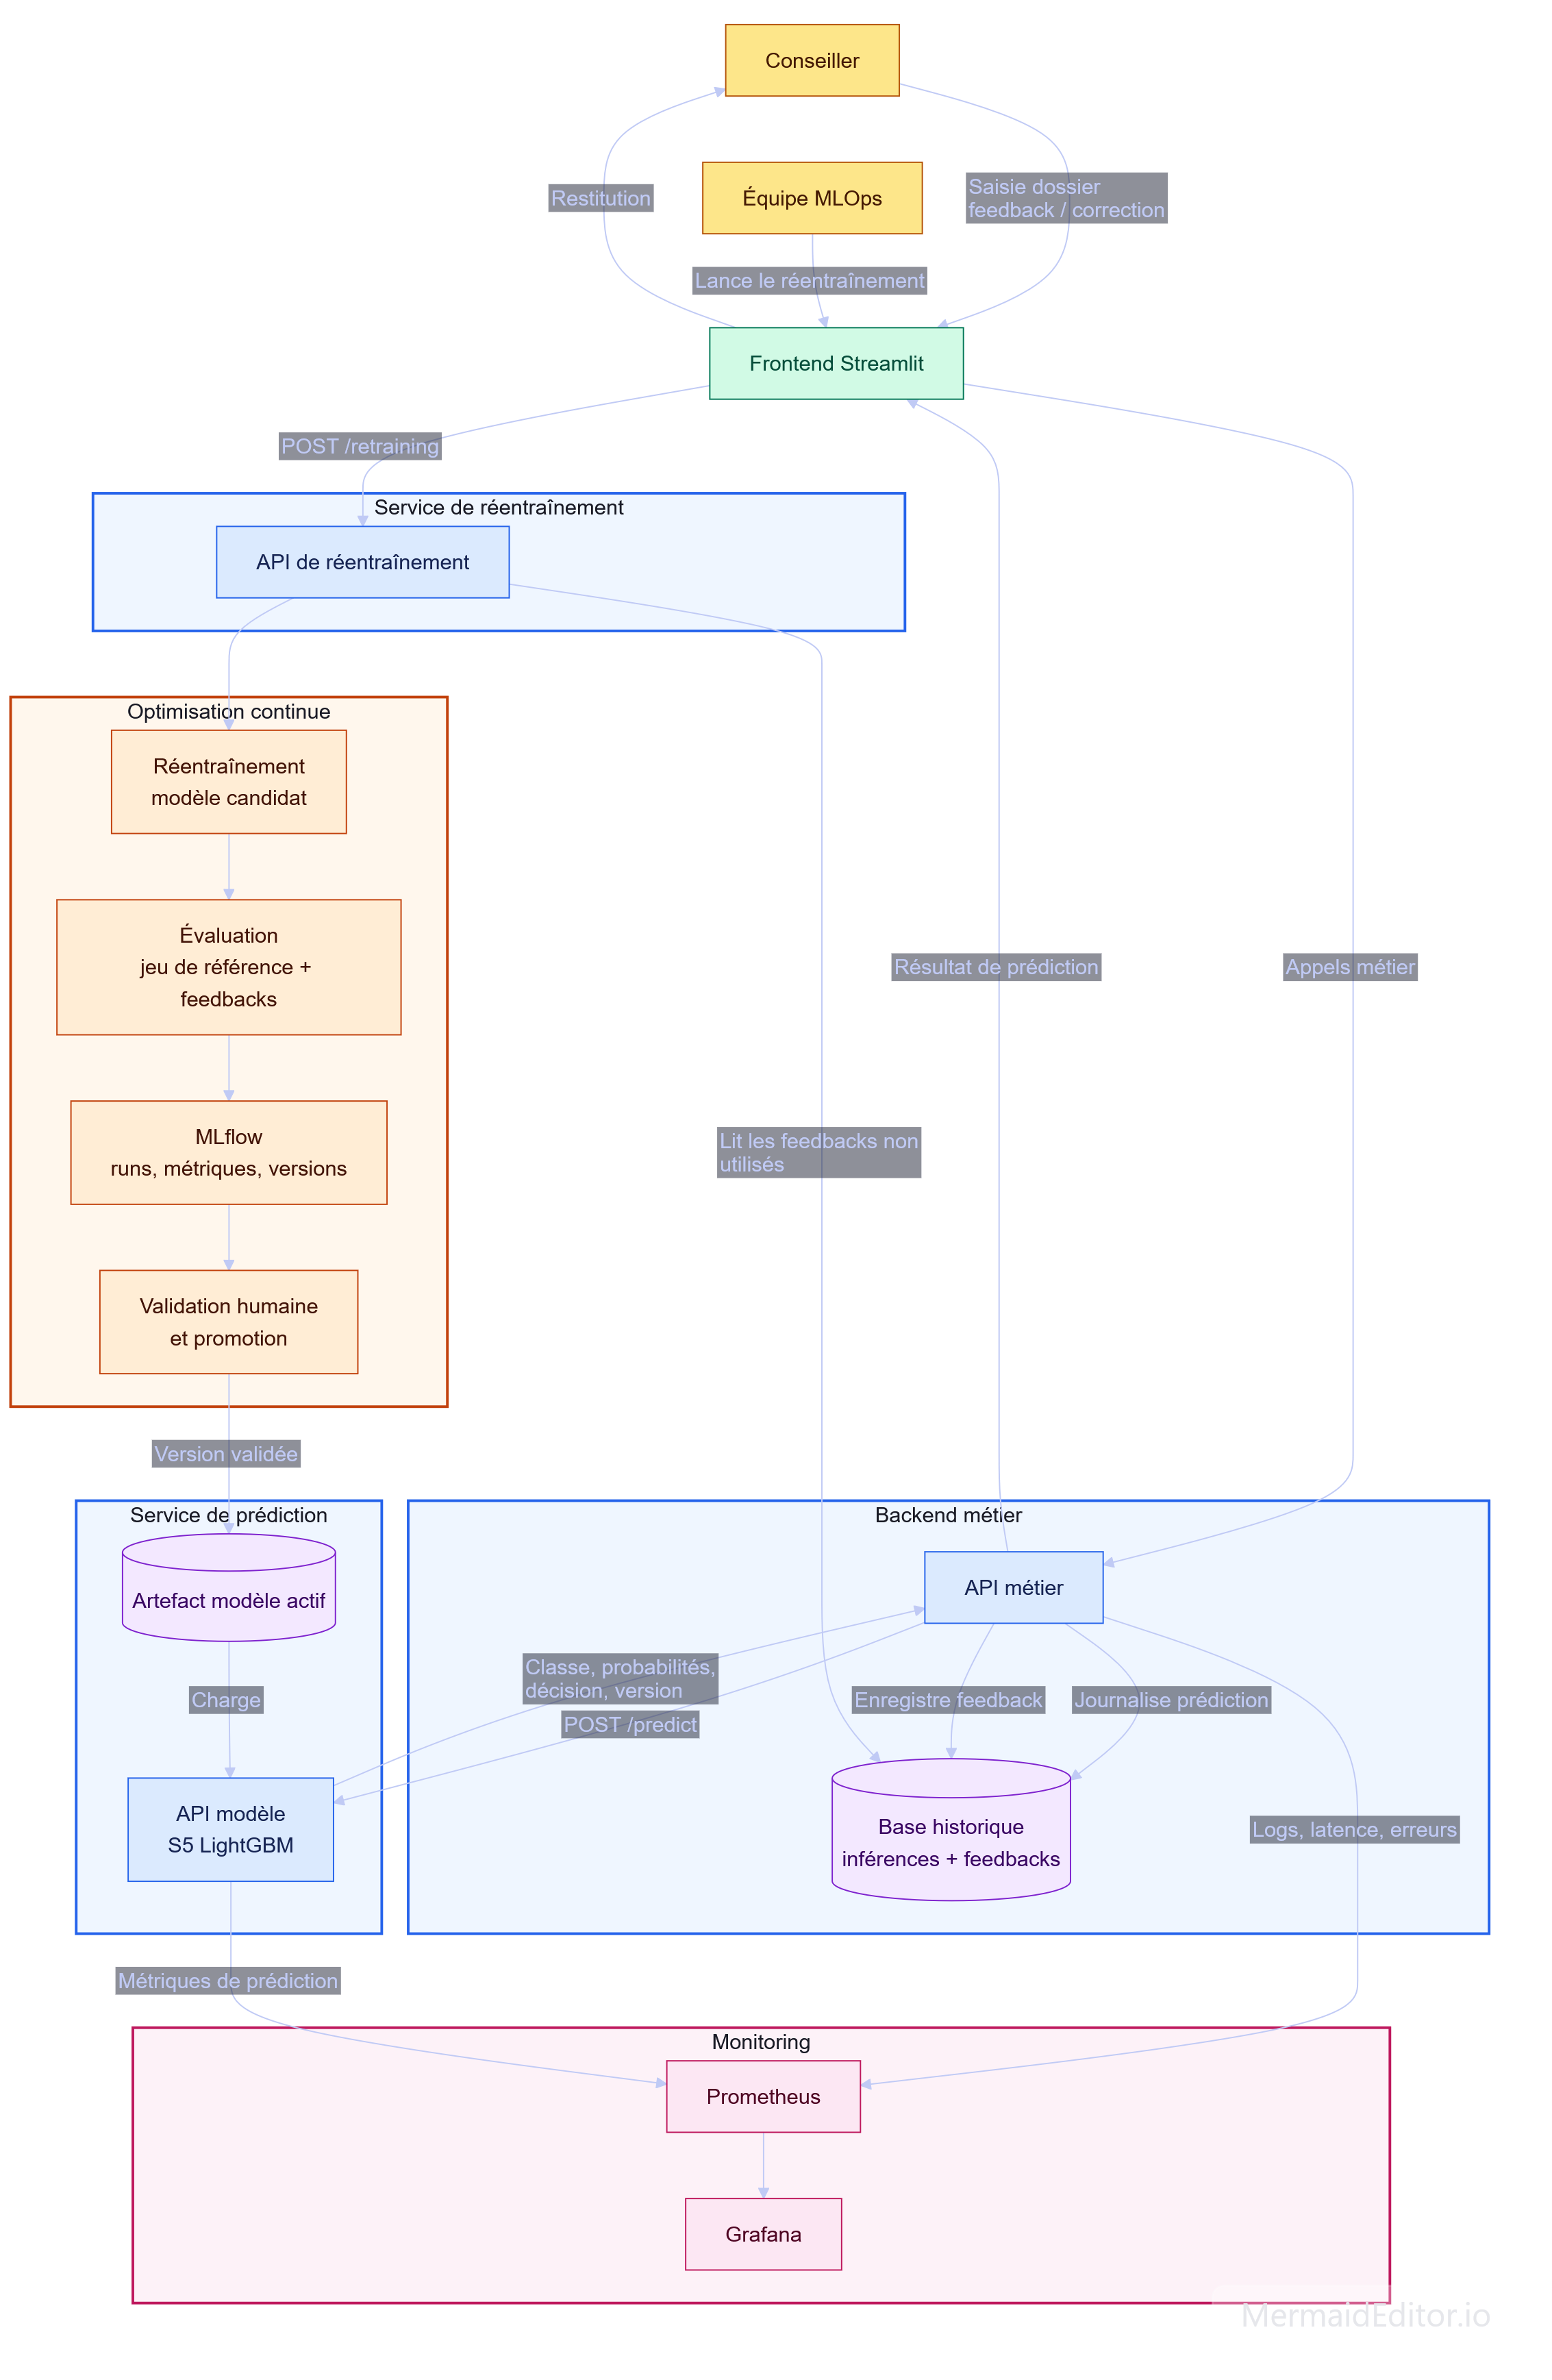

In [87]:
from IPython.display import Markdown, Image
display(Markdown("""
                 Le schéma ci-dessous présente l'architecture de mise en production et le
                 processus d'amélioration continue du modèle sélectionné **S5 LightGBM** :
                 """))
Image("Schema_Architecture.png", width=1200)

L'architecture des répertoires correspondantes est la suivante:
</br>
```
Certification-Atlas-Cisia/
|
|-- Data/
|   |-- training_set.csv                 # Jeu d'entraînement
|   |-- reference_set.csv                # Jeu de référence gelé
|   |-- *backend_metier.db               # Prédictions et feedbacks SQLite, non versionné
|   |-- mlflow.db                        # Base MLflow, générée à l'exécution, non versionné
|   `-- mlartifacts/                     # Artefacts MLflow, générés à l'exécution, non versionné
|
|-- Models/
|   |-- active_model.json                # Version de production active
|   |-- pipeline_v3.joblib               # Pipeline S5 LightGBM actif, non versionné
|   `-- pipeline_v3.json                 # Métadonnées du pipeline actif, non versionné
|
|-- Reports/
|   |-- candidate_evaluation.json        # Comparaison candidat / modèle actif
|   `-- promotion_decision.json          # Recommandation de promotion
|
|-- Scripts/
|   |-- config.py                        # Chemins, contrat de features et seuils
|   |-- data_preparation.py              # Préparation et feature engineering
|   |-- train.py                         # Construction et entraînement LightGBM
|   |-- evaluate.py                      # Métriques et erreurs critiques
|   |-- persist.py                       # Persistance joblib + métadonnées JSON
|   |-- train_and_persist.py             # Entraîne un candidat ou une version
|   |-- evaluate_candidate.py            # Évalue le candidat sur le jeu gelé
|   |-- promotion.py                     # Produit une recommandation
|   |-- promote_candidate.py             # Promotion humaine explicite
|   `-- register_mlflow.py               # Journalisation MLflow
|
|-- services/
|   |-- model_api/
|   |   |-- app/
|   |   |   |-- main.py                  # /health, /info, /predict, /metrics
|   |   |   |-- model_loader.py          # Chargement de l'artefact actif
|   |   |   |-- schemas.py               # Contrats Pydantic
|   |   |   |-- middleware.py            # Request ID et logs
|   |   |   `-- metrics.py               # Métriques de prédiction
|   |   `-- Dockerfile
|   |
|   |-- backend_metier_api/
|   |   |-- app/
|   |   |   |-- main.py                  # Prédictions, historique et feedbacks
|   |   |   |-- model_client.py          # Appel HTTP vers model-api
|   |   |   |-- repository.py            # Persistance SQLite
|   |   |   |-- schemas.py               # Dossier et feedback
|   |   |   `-- metrics.py               # Métriques de feedback
|   |   `-- Dockerfile
|   |
|   `-- retraining_api/
|       |-- app/
|       |   |-- main.py                  # /health, /retraining, /metrics
|       |   |-- retraining.py            # Orchestration du cycle MLOps
|       |   `-- schemas.py               # Réponse de réentraînement
|       `-- Dockerfile
|
|-- frontend/
|   |-- app.py                           # Application Streamlit
|   `-- Dockerfile
|
|-- prometheus/
|   `-- prometheus.yml                   # Scrape des APIs
|
|-- grafana/
|   `-- provisioning/                    # Source Prometheus et dashboard
|
|-- tests/
|   |-- test_data_preparation.py
|   |-- test_train.py
|   |-- test_evaluate.py
|   |-- test_model_contract.py
|   |-- test_model_api.py
|   |-- test_backend_metier_api.py
|   |-- test_retraining.py
|   `-- test_promotion.py
|
|-- Notebbok/
|   |-- ProjetFinal.ipynb
|   `-- Schema_Architecture.png
|
|-- .github/workflows/
|   `-- ci.yml                           # Tests, build et publication GHCR
|
|-- docker-compose.yml                   # Environnement local construit depuis le code
|-- docker-compose.prod.yml              # Images GHCR pour le test de livraison
|-- requirements.txt
`-- README.md
```

### 8.2 Frontend Client

**Repository associé** : [Certification-Atlas-Cisia](https://github.com/ddedomeni-j/Certification-Atlas-Cisia) - dossier `frontend/`.

Le frontend est une application **Streamlit** destinée aux conseillers et à l’équipe MLOps. Il est accessible localement sur `http://localhost:8501`.

Il permet :
- de saisir les informations d'un dossier candidat
- d'appeler l'API métier pour obtenir une prédiction du délai de retour à l'emploi
- d'afficher la classe prédite, les probabilités, la décision métier, la version du modèle et le `request_id`
- de consulter l'historique des prédictions
- d'enregistrer un feedback conseiller en corrigeant une classe prédite
- d'accéder aux outils de suivi MLflow et Grafana
- depuis l'espace **Administration ML**, réservé conceptuellement à l'équipe MLOps, de déclencher un cycle de réentraînement

Le frontend ne communique pas directement avec l'API modèle. Il appelle l'API métier, qui prépare les variables attendues par le modèle, journalise la prédiction et gère les feedbacks. L'espace MLOps appelle séparément l'API de réentraînement.

L'interface se présente ainsi :

Ecran d'accueil :

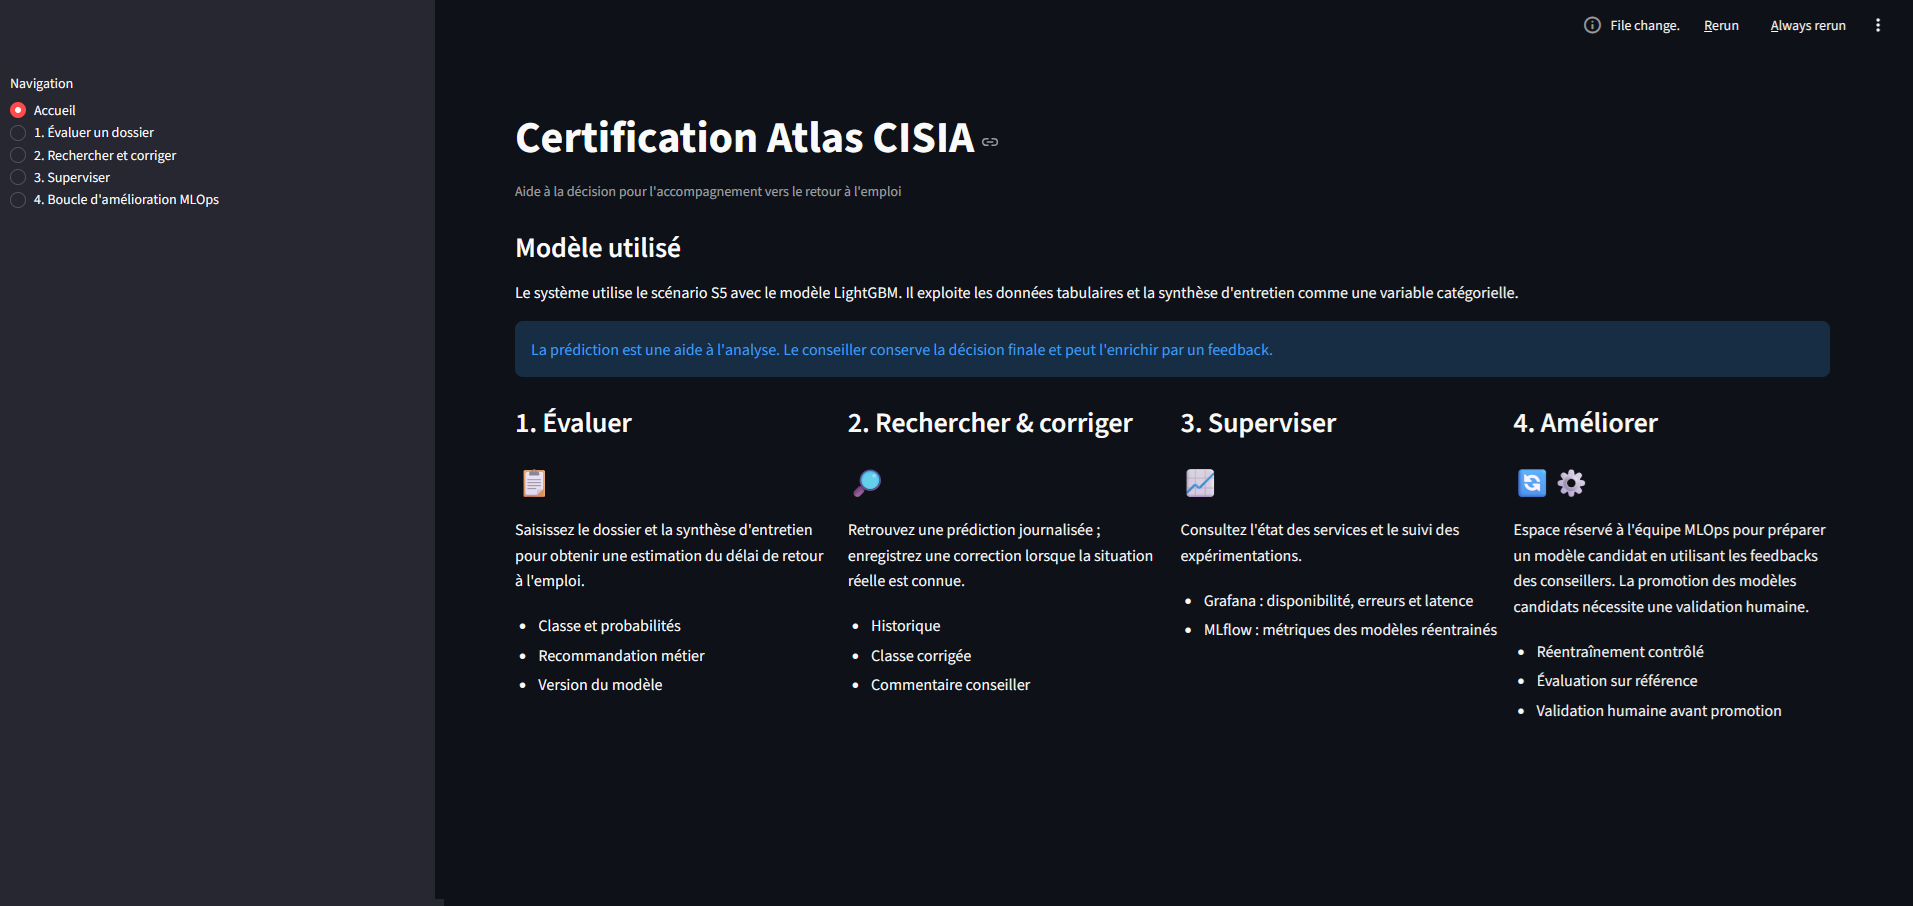

In [88]:
from IPython.display import Markdown, Image
display(Markdown("Ecran d'accueil :"))
Image("../Doc/AccueilStreamlit.png", width=1200)

Ecran de prédiction :

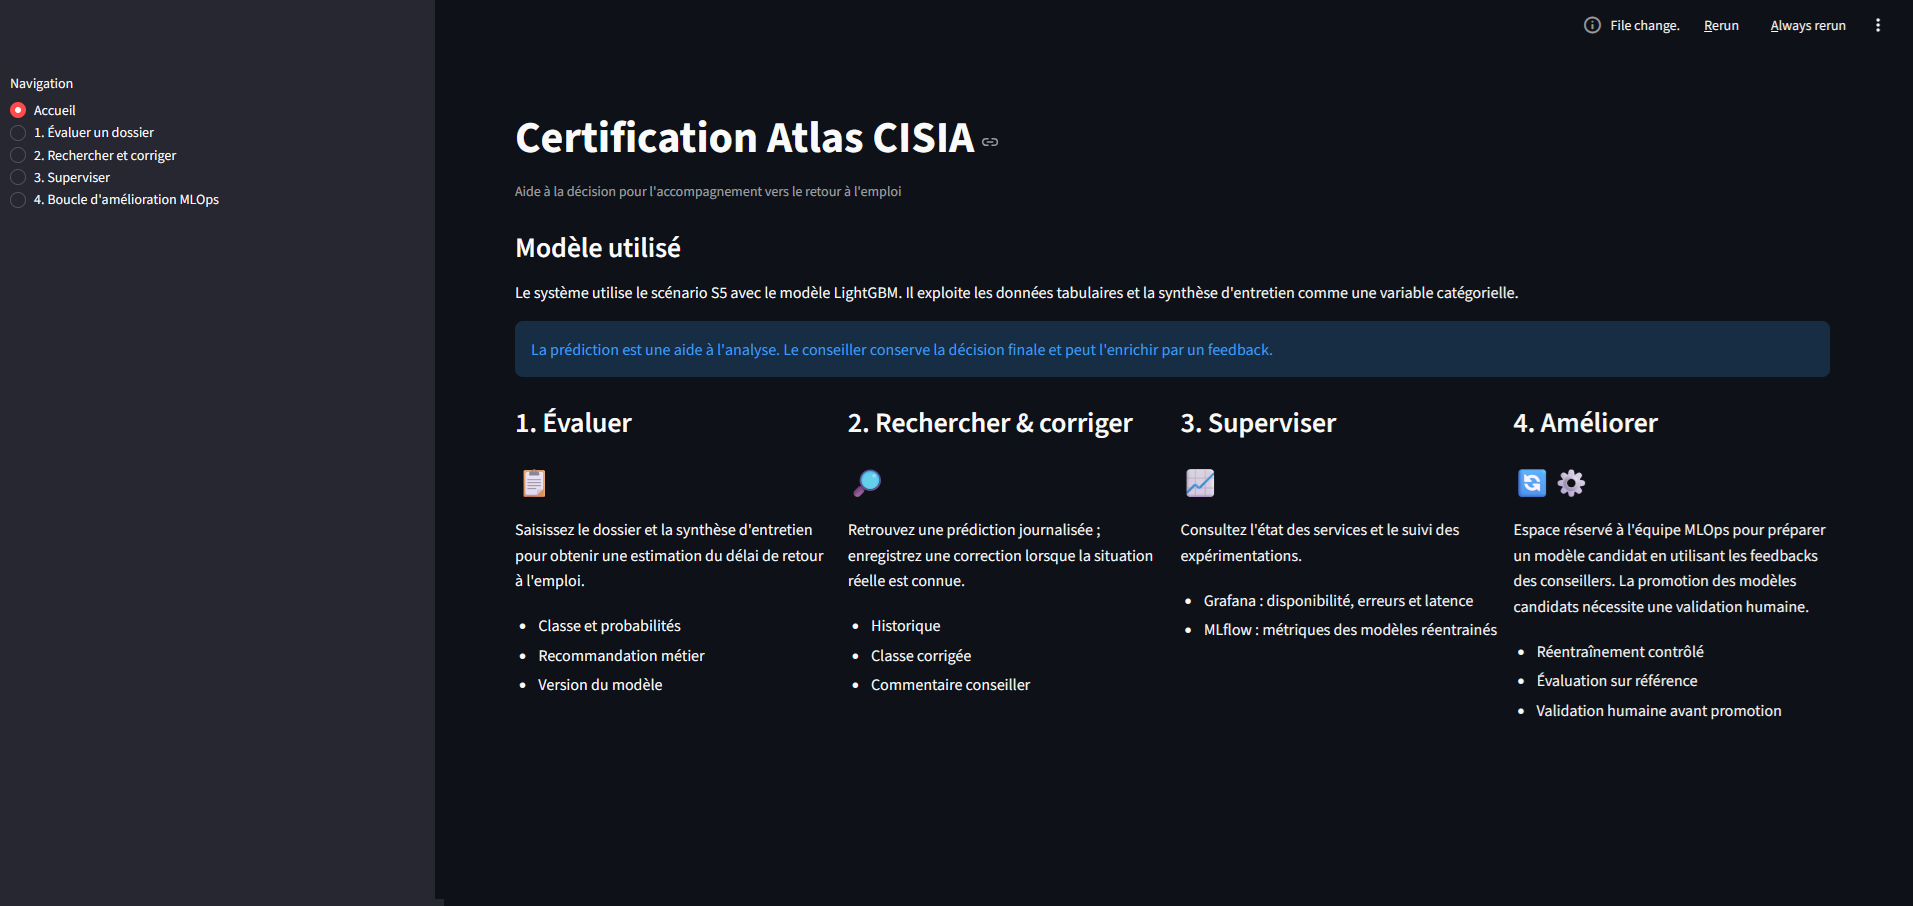

In [89]:
from IPython.display import Markdown, Image
display(Markdown("Ecran de prédiction :"))
Image("../Doc/AccueilStreamlit.png", width=1200)

Saisie d'un feedback :

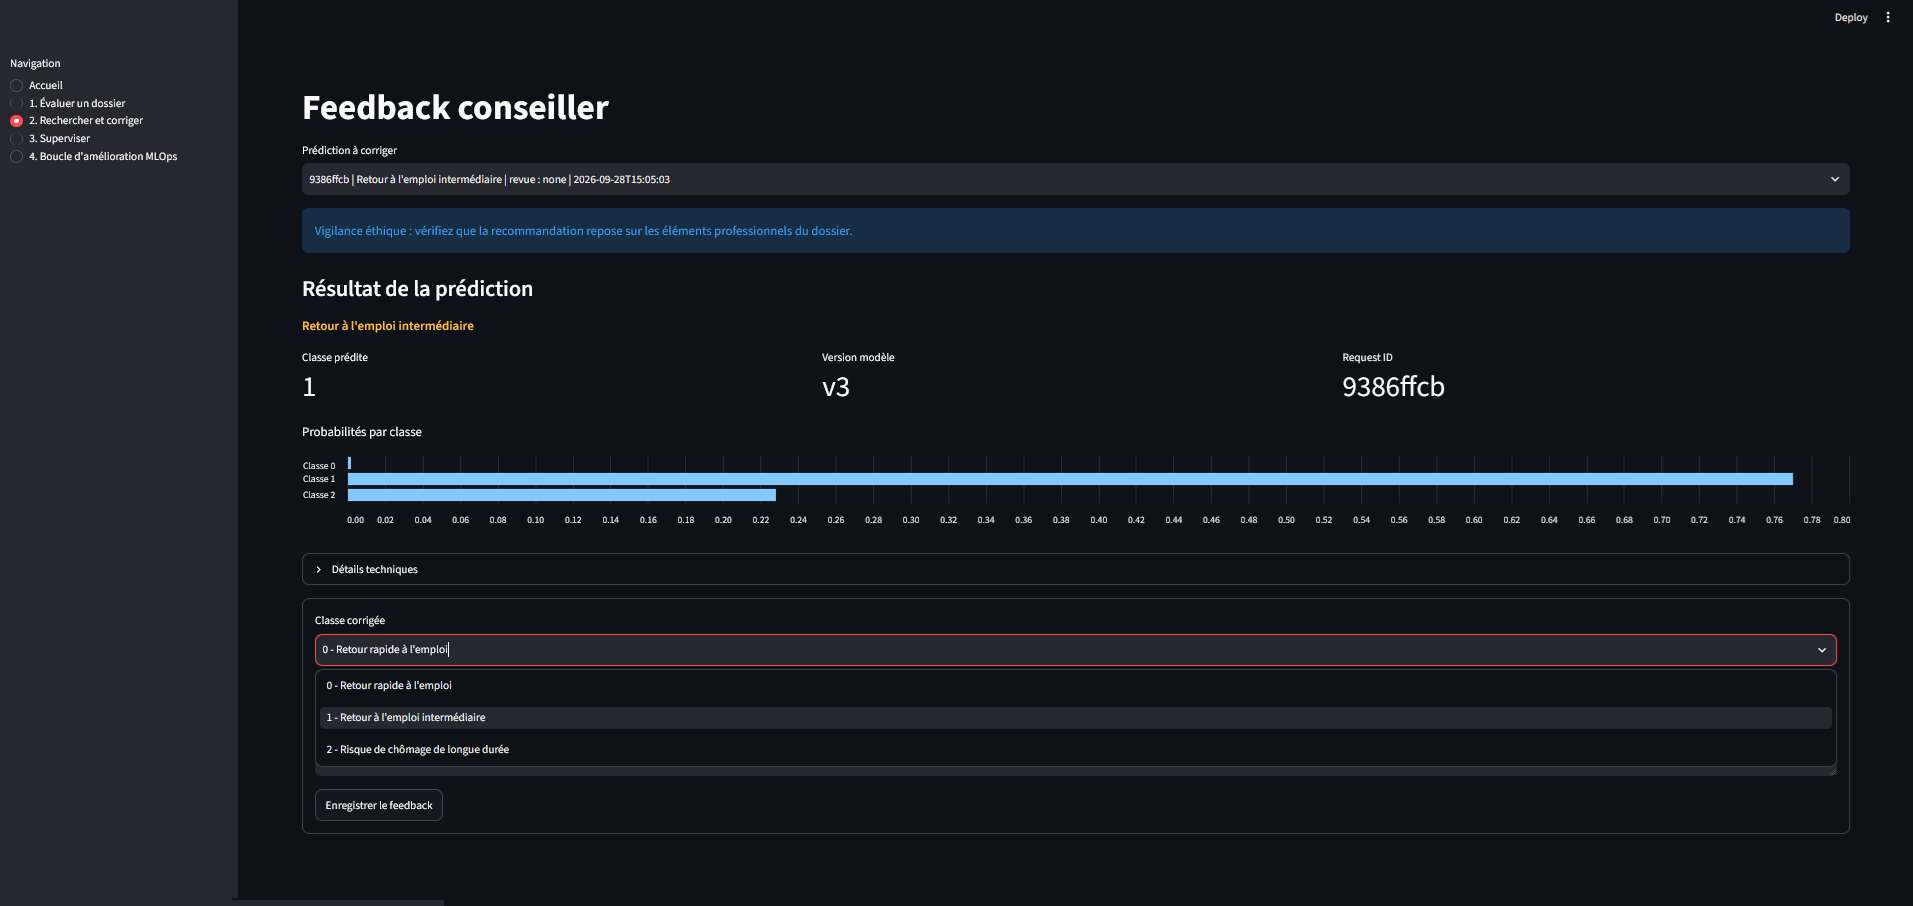

In [90]:
from IPython.display import Markdown, Image
display(Markdown("Saisie d'un feedback :"))
Image("../Doc/CorrectionFeedback.png", width=1200)

Accès aux tableaux de suivi :

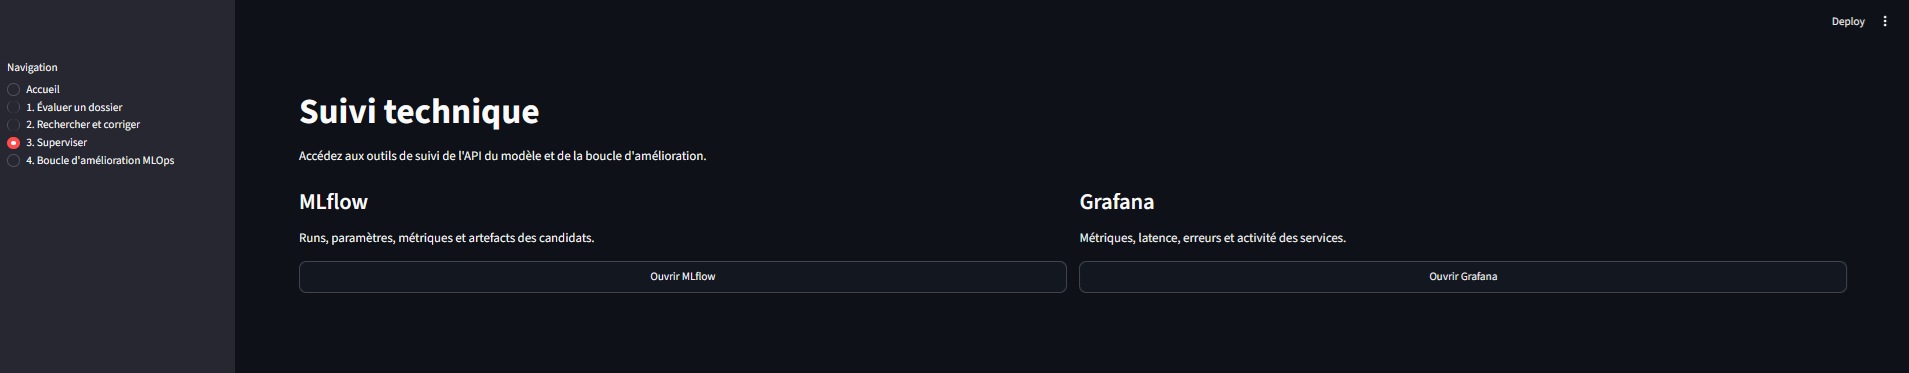

In [91]:
from IPython.display import Markdown, Image
display(Markdown("Accès aux tableaux de suivi :"))
Image("../Doc/Superviser.png", width=1200)

### 8.3 Service API model

**Repository associé** : [Certification-Atlas-Cisia](https://github.com/ddedomeni-j/Certification-Atlas-Cisia) - dossier `services/model_api/`

Ce service FastAPI charge le pipeline S5 LightGBM actif depuis le répertoire
`Models/`. Il est interne à l’architecture : le frontend ne l’appelle jamais
directement ; les requêtes passent par l’API métier.

| Route | Méthode | Rôle | Validation |
|---|---|---|---|
| `/health` | GET | Vérifie que le service est disponible et que le modèle actif a été chargé. | — |
| `/info` | GET | Retourne les informations du modèle actif : version et contrat des variables attendues. | — |
| `/predict` | POST | Reçoit un dossier déjà préparé, applique le pipeline LightGBM et renvoie la classe prédite, les probabilités par classe, la version du modèle et l’identifiant de requête. | Pydantic |
| `/metrics` | GET | Expose les métriques HTTP pour Prometheus. | — |

La réponse de `/predict` conserve les trois classes du modèle : `0`, `1` et `2`.
</br>Les règles d'abstention et de revue humaine ne sont pas appliquées ici : elles
relèvent du backend métier, après réception des probabilités.

### Métriques Prometheus

La route `/metrics` expose les métriques HTTP suivantes :

- disponibilité du service ;
- nombre de requêtes par route et code HTTP ;
- latence des requêtes ;
- nombre de prédictions par classe (`0`, `1`, `2`).

Ces métriques permettent de détecter une indisponibilité, une hausse de latence,
des erreurs techniques ou une évolution de la distribution des prédictions.

### Justification des choix techniques

**FastAPI** est retenu pour :

- sa simplicité pour construire une API REST
- la validation automatique des requêtes et réponses grâce à **Pydantic**
- la génération automatique de la documentation interactive **OpenAPI / Swagger**
- le support asynchrone, plus adaptée à une architecture de microservice

**Traçabilité** : chaque prédiction enregistrée peut
être reliée au modèle qui l'a produite, à ses probabilités et au feedback
ultérieur du conseiller via :

- la **version du modèle** utilisée ;
- un **identifiant de requête** (`request_id`).

Accès aux tableaux de suivi :

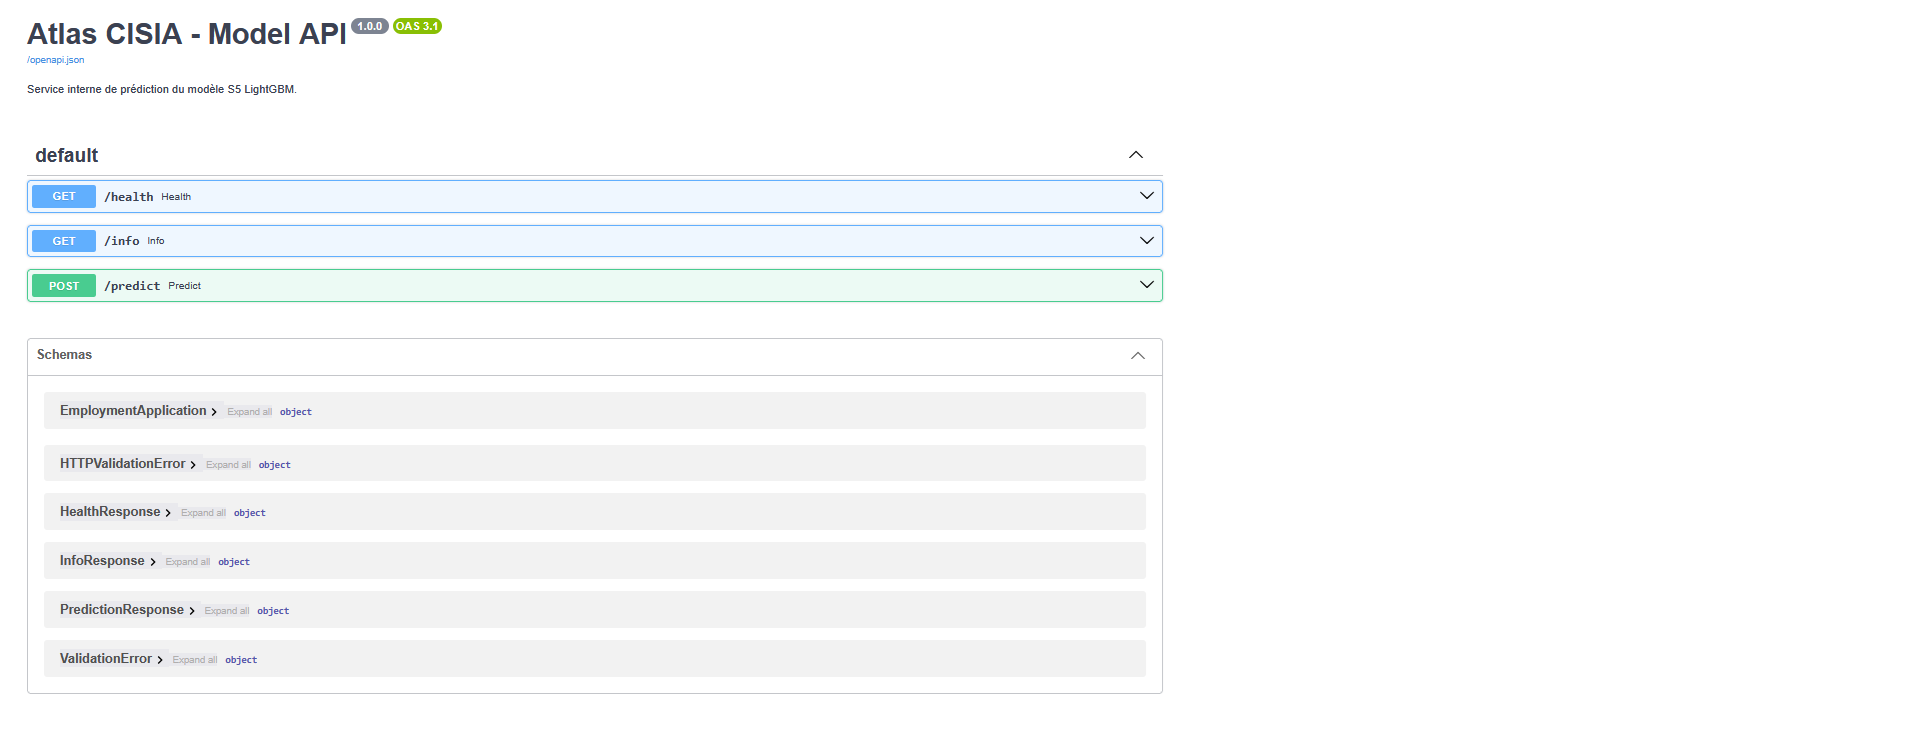

In [92]:
from IPython.display import Markdown, Image
display(Markdown("Accès aux tableaux de suivi :"))
Image("../Doc/DocApiModel.png", width=1200)

### 8.3 Service API métier

**Repository associé** : [Certification-Atlas-Cisia](https://github.com/ddedomeni-j/Certification-Atlas-Cisia) - dossier `services/backend_metier_api/`

Ce service FastAPI constitue le point d'entrée du frontend. Il reçoit le dossier
brut du conseiller, applique les transformations métier, appelle
le service de prédiction, puis enregistre la décision, les probabilités et les
feedbacks dans la base SQLite.

| Route | Méthode | Rôle | Validation |
|---|---|---|---|
| `/health` | GET | Vérifie la disponibilité du backend métier. | — |
| `/applications/predict` | POST | Prépare le dossier, appelle `model-api`, applique les règles de revue humaine et journalise la prédiction. | Pydantic |
| `/applications` | GET | Liste les prédictions journalisées afin de sélectionner un dossier à corriger. | — |
| `/applications/{request_id}` | GET | Retourne le détail d'une prédiction enregistrée. | — |
| `/feedback` | POST | Enregistre la correction et le commentaire du conseiller. | Pydantic |
| `/metrics` | GET | Expose les métriques HTTP pour Prometheus ; route non documentée dans Swagger. | — |

Le service applique les règles de sécurité définies en section 7 :

- une **abstention** lorsque la confiance maximale est inférieure à $0{,}60$
- une **revue humaine renforcée** pour une prédiction de classe `0` lorsque
  $0{,}60 \leq p_0 < 0{,}80$
- une **vigilance éthique** lorsque le dossier nécessite un contrôle humain
  renforcé selon les règles du démonstrateur

La classe prédite reste toujours l'une des trois classes du modèle (`0`, `1`
ou `2`). Les statuts `review_status` et `ethical_review_required` ajoutent des
informations de contrôle sans modifier la prédiction ou les
probabilités retournées par le modèle.

### Métriques Prometheus

La route `/metrics` expose :

- disponibilité du backend métier
- nombre de requêtes, codes HTTP et latence
- nombre de feedbacks enregistrés par classe corrigée

Elles permettent de suivre l'utilisation du parcours conseiller et l'activité
des corrections qui alimentent la boucle d'amélioration.

### Justification des choix techniques

**La séparation entre service métier et service de prédiction** permet :

- d'isoler le pipeline ML et son contrat technique dans `model-api`
- de centraliser les règles fonctionnelles, d'abstention et de revue humaine
- de conserver une trace complète des décisions et des feedbacks
- de faire évoluer les règles métier sans modifier le modèle entraîné

**La persistance SQLite** enregistre pour chaque prédiction :

- le dossier brut transmis
- la classe, les probabilités et la décision affichée
- les statuts de revue et de vigilance éthique
- la version du modèle et le `request_id`
- les corrections ultérieures apportées par le conseiller

Etant donné le faible volume de données à traiter, **SQLite** est retenu pour sa simplicité d'installation et d'utilisation.

Accès aux tableaux de suivi :

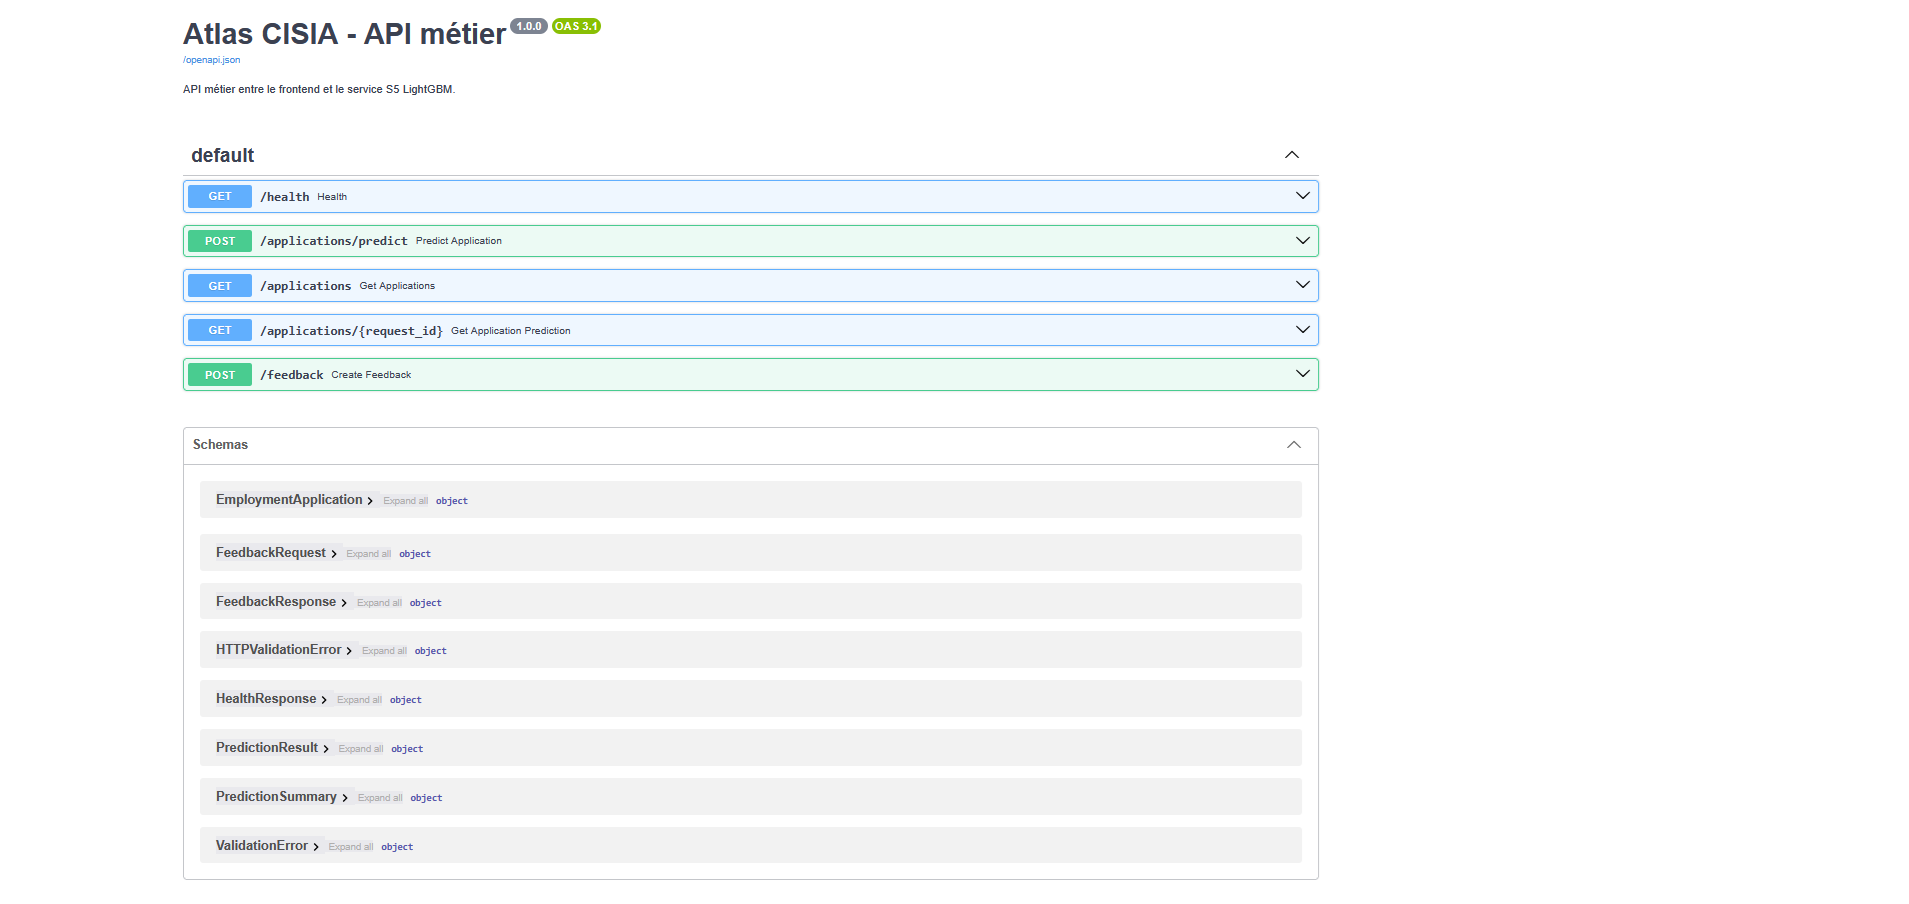

In [93]:
from IPython.display import Markdown, Image
display(Markdown("Accès aux tableaux de suivi :"))
Image("../Doc/DocApiMetier.png", width=1200)

### 8.4 Service API réentrainement

**Repository associé** : [Certification-Atlas-Cisia](https://github.com/ddedomeni-j/Certification-Atlas-Cisia) - dossier `services/retraining_api/`

Ce service FastAPI est réservé à l'équipe MLOps. Il exploite les feedbacks
conseillers non utilisés pour entraîner un modèle candidat, l'évaluer face au
modèle actif sur un jeu de référence, puis produire une recommandation de
promotion. Il ne promeut jamais automatiquement un candidat.

| Route | Méthode | Rôle | Validation |
|---|---|---|---|
| `/health` | GET | Vérifie la disponibilité du service de réentraînement. | — |
| `/retraining` | POST | Lance la préparation des données, l'entraînement du candidat, son évaluation et la recommandation de promotion. | Réponse Pydantic |
| `/metrics` | GET | Expose les métriques HTTP pour Prometheus ; route non documentée dans Swagger. | — |

Le cycle de réentraînement suit les étapes suivantes :

1. Lecture des feedbacks non utilisés dans la base SQLite
2. Ajout des dossiers corrigés au jeu d'entraînement initial
3. Entraînement et persistance d'un modèle candidat
4. Évaluation du candidat face au modèle actif sur le jeu de référence figé
5. Génération d'une recommandation de promotion
6. Marquage des feedbacks comme utilisés, uniquement si le cycle complet réussit

La promotion reste une action humaine distincte. Elle nécessite la validation
de l'équipe MLOps avant la mise à jour de `Models/active_model.json`.

### Justification du choix d'architecture

**La séparation entre le réentraînement et l'API métier** permet :

- de séparer le parcours opérationnel du conseiller de la maintenance du
modèle afin de préserver le modèle actif tant qu'un candidat n'a pas été évalué et validé
- de ne pas exposer la maintenance du modèle aux utilisateurs finaux
- d'éviter qu'un feedback ou un réentraînement déclenche le pipeline de réentrainement
- de conserver une recommandation de promotion traçable dans les rapports

**Les feedbacks sont marqués comme utilisés uniquement après succès complet** :

- un échec d'entraînement ou d'évaluation ne fait pas perdre les corrections
- les mêmes feedbacks ne sont pas intégrés plusieurs fois dans un candidat
- la boucle d'amélioration est contrôlée et reproductible

**Note** : une mise en production complète nécessiterait de protéger l'accès à `/retraining` par une authentification et des rôles dédiés à l'équipe MLOps.

Accès aux tableaux de suivi :

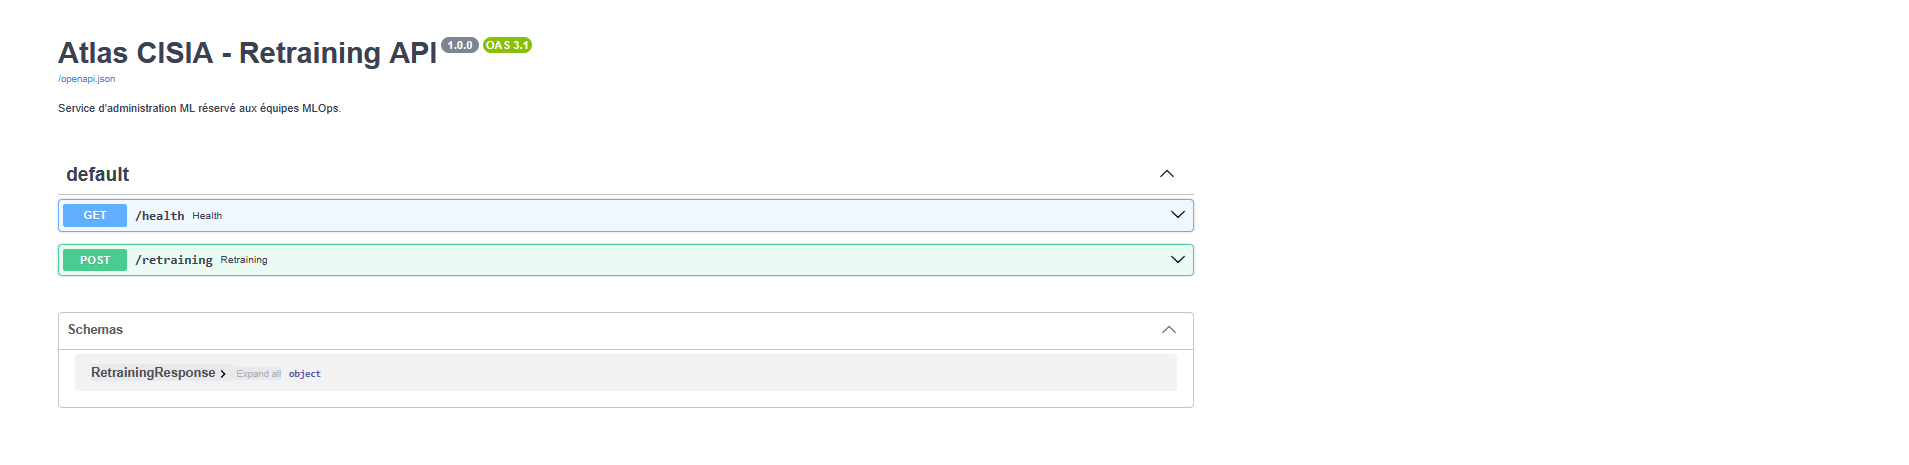

In [94]:
from IPython.display import Markdown, Image
display(Markdown("Accès aux tableaux de suivi :"))
Image("../Doc/DocApiRetraining.png", width=1200)

### 8.5 Persistance du modèle

Le service de prédiction charge le modèle actif depuis le dossier `Models/`.
Le modèle en production est identifié par le fichier `active_model.json`, qui contient
la version active.

Exemple :

```json
{
  "active_version": "v3"
}
```

Chaque version est constituée de deux fichers :

- pipeline_vXX.joblib : pipeline Scikit-learn complet contenant le
prétraitement appris et le classifieur LightGBM ;
- pipeline_vXX.json : métadonnées de la version, notamment le scénario, le
contrat des variables attendues, la date de création et les métriques
d'évaluation.

Le changement de modèle en production consiste à mettre à jour le pointeur
active_model.json après validation humaine d'un candidat. Cette stratégie
évite d'écraser un modèle existant et permet un retour arrière en rétablissant
une version antérieure.

Les artefacts binaires ne sont pas versionnés dans Git. En environnement de
démonstration ou en production, le dossier Models/ est monté dans le
conteneur Docker du service de prédiction. Les images Docker restent ainsi
indépendantes de la version de modèle effectivement servie.

Les entraînements, paramètres, métriques et artefacts candidats sont également tracés dans MLflow. MLflow assure la traçabilité des expérimentations ; active_model.json reste la source de vérité opérationnelle indiquant le modèle chargé par l'API.

L’illustration ci-dessous présente un run MLflow associé à l’entraînement d’un modèle candidat. Les métriques principales utilisées pour la recommandation de promotion sont :

- **F1 macro** : mesure l’équilibre global de la qualité des prédictions entre
  les trois classes. Le candidat doit dépasser le plancher défini et apporter
  un gain minimal par rapport au modèle actif
- **Taux d’erreurs critiques $2 \rightarrow 0$** : mesure la proportion de
  dossiers réellement à risque de chômage de longue durée, prédits à tort comme
  un retour rapide à l’emploi. Ce taux ne doit pas se dégrader au-delà de la
  tolérance définie par rapport au modèle de production.
- **Nombre d’erreurs critiques $2 \rightarrow 0$** : complète le taux par un
  effectif absolu, utile pour interpréter le résultat sur le jeu de référence
- **Version du modèle** et **jeu de référence évalué** : assurent que le modèle
  candidat et le modèle actif sont comparés sur le même jeu de données figé

Le nombre absolu d'**erreurs critiques \rightarrow 0$** est conservé dans les métriques pour interpréter le taux observé, sans constituer un critère de rejet autonome.

Accès aux tableaux de suivi :

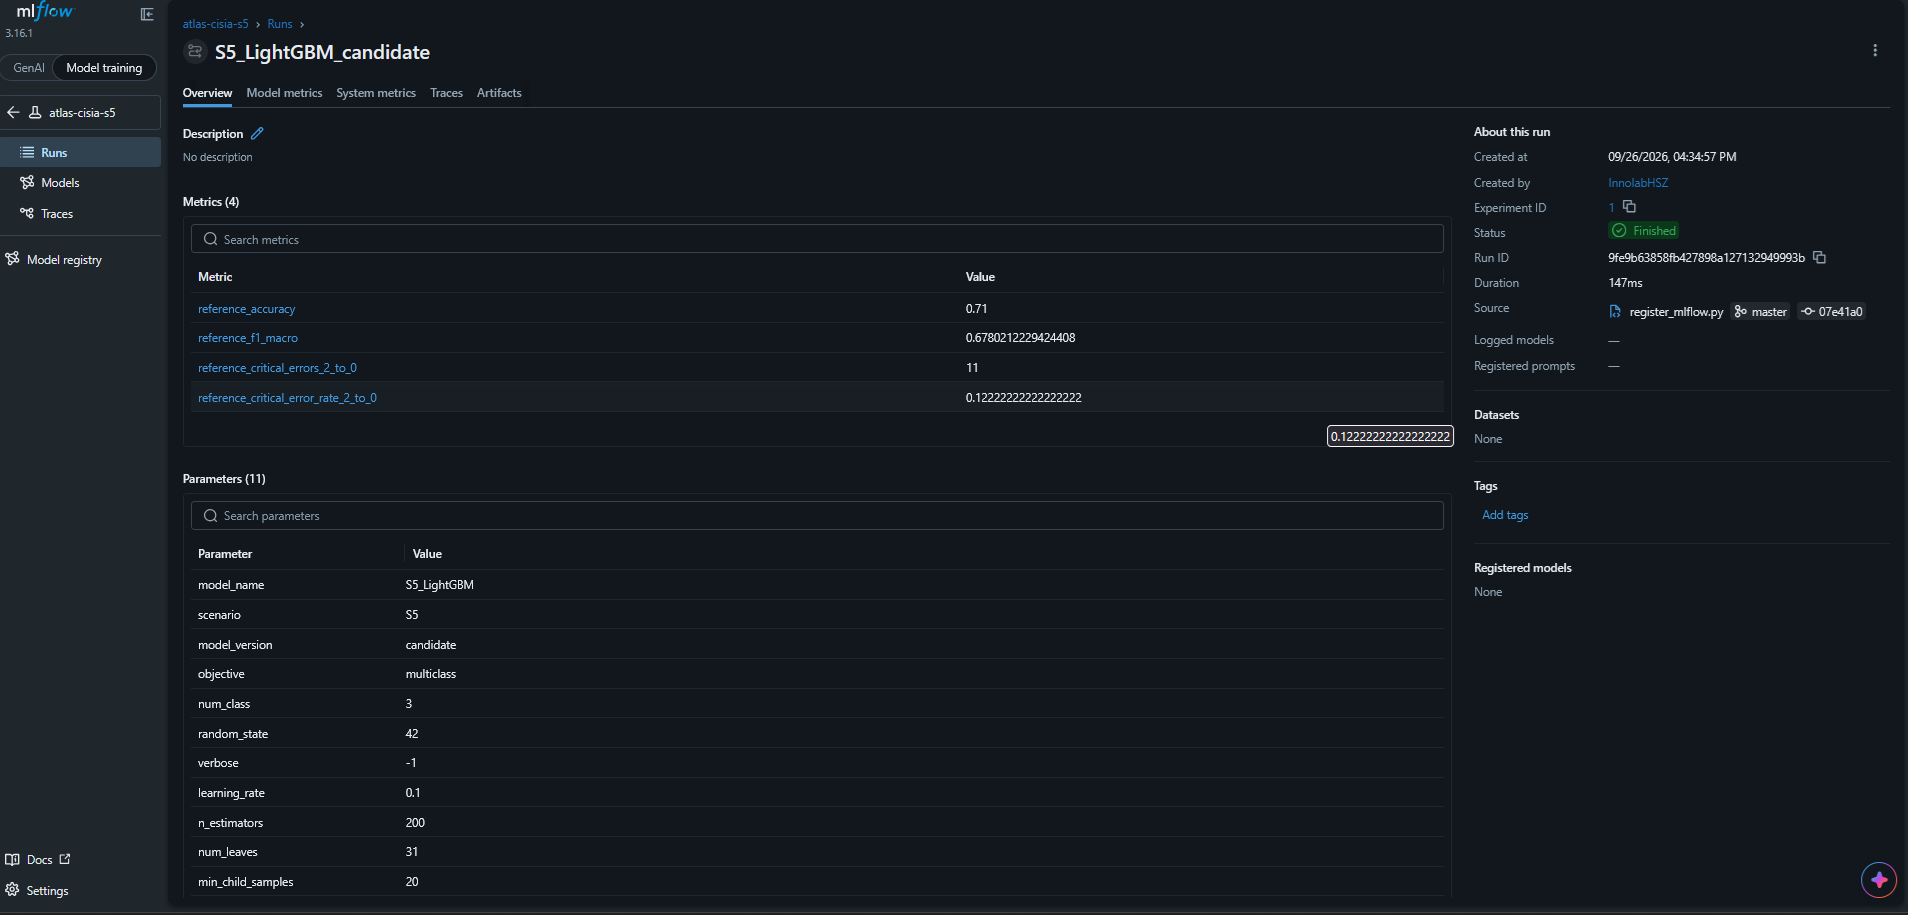

In [95]:
from IPython.display import Markdown, Image
display(Markdown("Accès aux tableaux de suivi :"))
Image("../Doc/DashboardMlFlow.png", width=1200)

La recommandation est affichée à l'équipe MlOps dans l'interface

Accès aux tableaux de suivi :

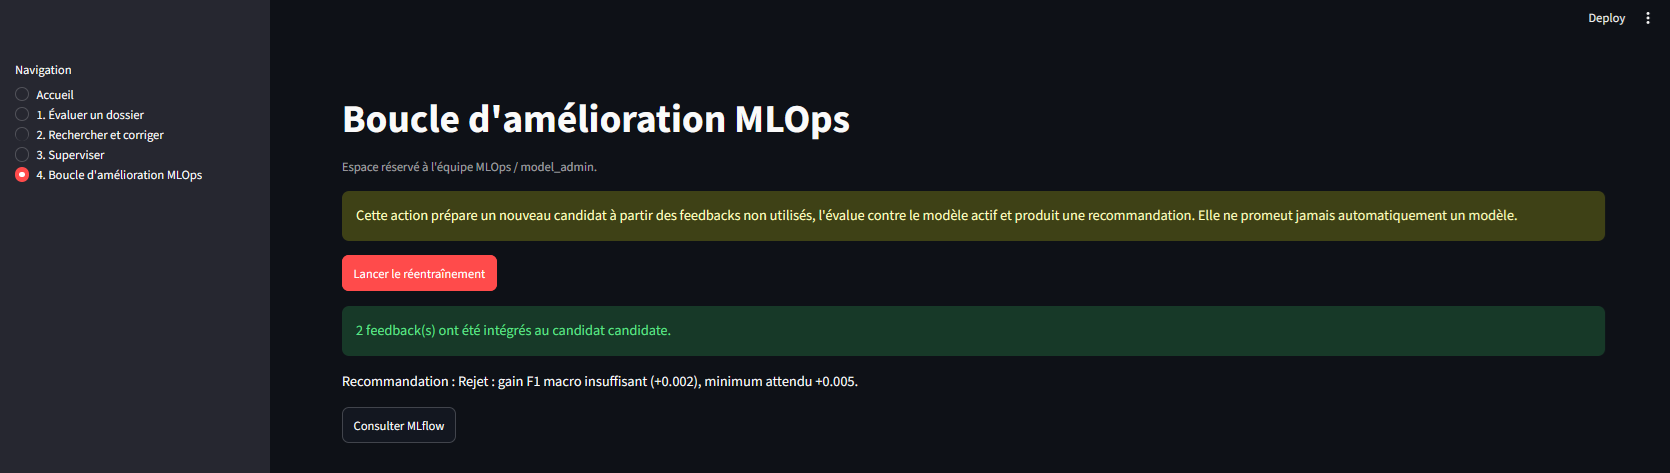

In [2]:
from IPython.display import Markdown, Image
display(Markdown("Accès aux tableaux de suivi :"))
Image("../Doc/RetourUtilisateurReentrainement.png", width=1200)

### 8.6 Observabilité

Les dashboard créés permettent de suivre le bon fonctionnement des services en
production et de détecter rapidement une indisponibilité ou une dégradation des
performances.

Prometheus collecte périodiquement les métriques exposées par les API sur leurs
routes `/metrics`. Grafana interroge ensuite Prometheus pour les présenter sous
forme de tableaux de bord.

Les indicateurs suivis sont :

- la disponibilité des 3 services
- les codes de réponse HTTP, afin d'identifier une augmentation des erreurs 502 et 503 entre l’API métier et l’API modèle
- la répartition des prédictions par classe, utilisée comme signal de
  surveillance métier : une évolution inhabituelle peut révéler un changement
  du flux de dossiers ou un comportement anormal du modèle, sans constituer à
  elle seule une mesure de qualité prédictive.
- la latence des requêtes, afin de détecter une dégradation des temps de
  réponse

Les dashboards Grafana ci-dessous permettent donc une surveillance technique
des API et du flux de retours utilisateurs. Ils ne mesurent pas directement la
qualité prédictive ou le drift du modèle : ces éléments sont évalués lors du
processus de réentraînement, sur le jeu de référence figé.

#### Procédure à suivre en cas d'alerte

En cas d'anomalie détectée dans Grafana, l'équipe identifie d'abord le service
concerné, puis consulte ses logs, l'état des conteneurs Docker et les métriques
disponibles dans Prometheus. Ces éléments permettent de qualifier l'incident
**avant d'envisager la mise en œuvre d'une action corrective**.

Accès aux tableaux de suivi :

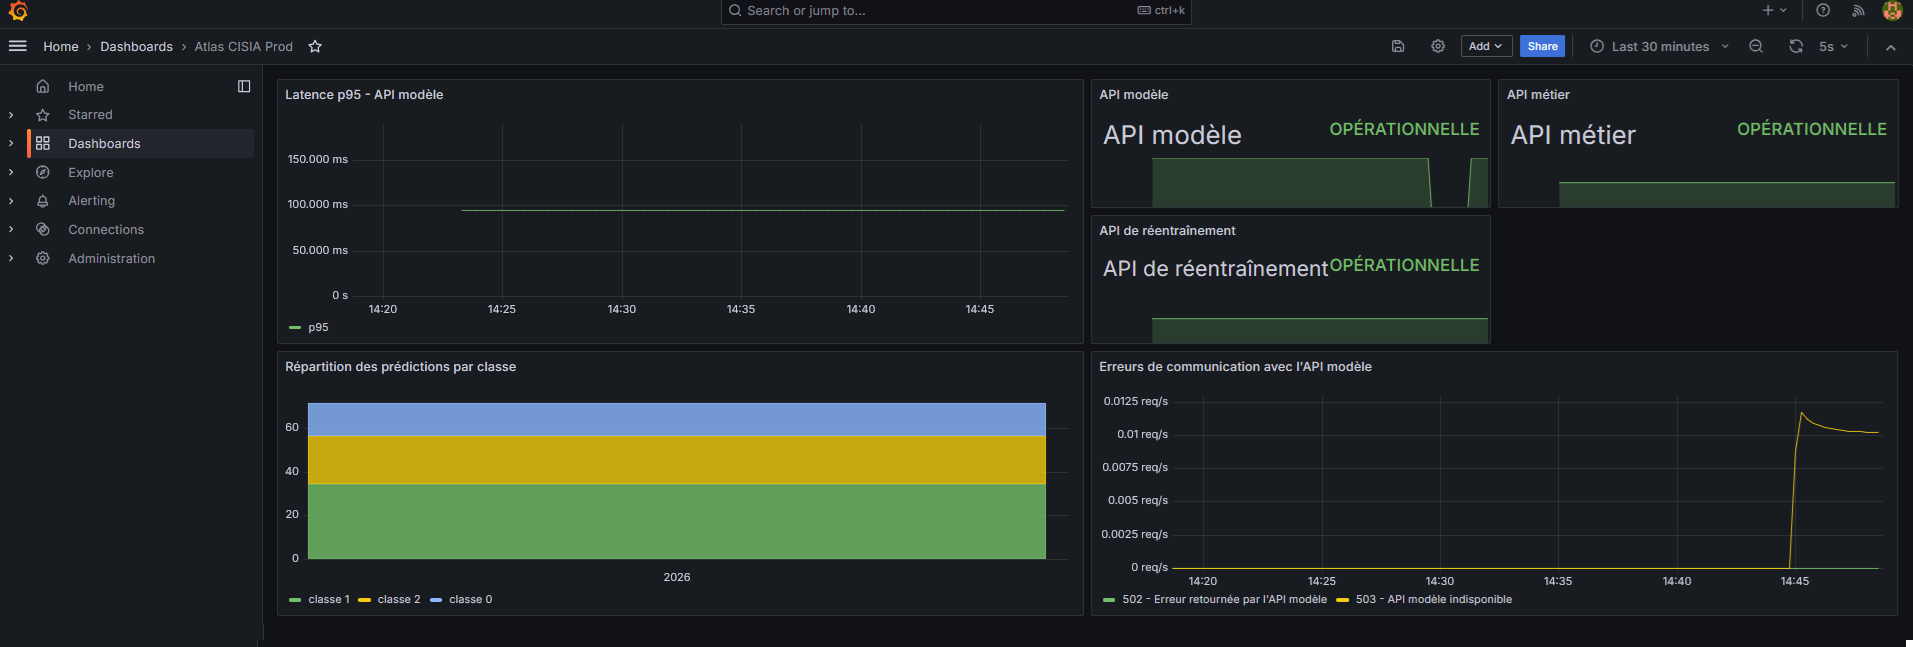

In [96]:
from IPython.display import Markdown, Image
display(Markdown("Accès aux tableaux de suivi :"))
Image("../Doc/DashboardGrafana.png", width=1200)

### 8.7 Conteneurisation

L'application est conteneurisée afin de garantir un environnement d'exécution
reproductible et de faciliter le déploiement des différents services. Chaque
composant possède son propre **`Dockerfile`** : API de modèle, API métier, API de
réentraînement et interface Streamlit.

Le fichier **`docker-compose.yml`** orchestre l'environnement local complet. Il
démarre les API, l'interface utilisateur, Prometheus, Grafana et MLflow, tout
en définissant les dépendances et les vérifications de santé nécessaires au bon
ordre de démarrage. Les données, les modèles et les rapports sont montés en
volumes afin d'être conservés indépendamment des conteneurs.

Pour simuler un déploiement en production, le fichier
**`docker-compose.prod.yml`** s'appuie sur les images versionnées publiées dans
GitHub Container Registry (GHCR). Il permet ainsi d'exécuter et de tester les
conteneurs correspondant précisément au SHA du commit sélectionné, sans
reconstruire les images depuis le code local.

### 8.8 CI/CD

L'intégration continue est assurée par **GitHub Actions**. À chaque mise à jour de
la branche **`master`**, le workflow prépare l'artefact du modèle actif, exécute
les tests automatisés, construit les images Docker puis les publie dans GHCR
lorsque les vérifications sont satisfaites. 

Pour faciliter les tests, la stratégie CI/CD distingue la validation du code de la publication des images. Lorsqu'une pull request est ouverte depuis une branche, le workflow prépare l'artefact du modèle actif puis exécute les tests automatisés afin de valider la modification proposée.

Dans ce cas, la construction et la publication des images dans GitHub Container Registry ne sont réalisées qu'après acceptation et fusion de la pull request dans la branche `master`. Seules les versions validées sont ainsi rendues disponibles pour la simulation ou le déploiement.

La validation métier des modèles est indépendante du processus de livraison des
services et du frontend. La CI/CD valide et publie les images techniques, tandis
que la promotion d'un modèle candidat repose sur son évaluation, le respect des
seuils métier et une validation humaine. Ni la publication d'une image ni
l'entraînement d'un candidat ne modifient automatiquement le modèle actif.

Les captures ci-dessous présentent un workflow GitHub Actions terminé avec
succès ainsi que les images publiées et versionnées dans le registre.

Accès aux tableaux de suivi :

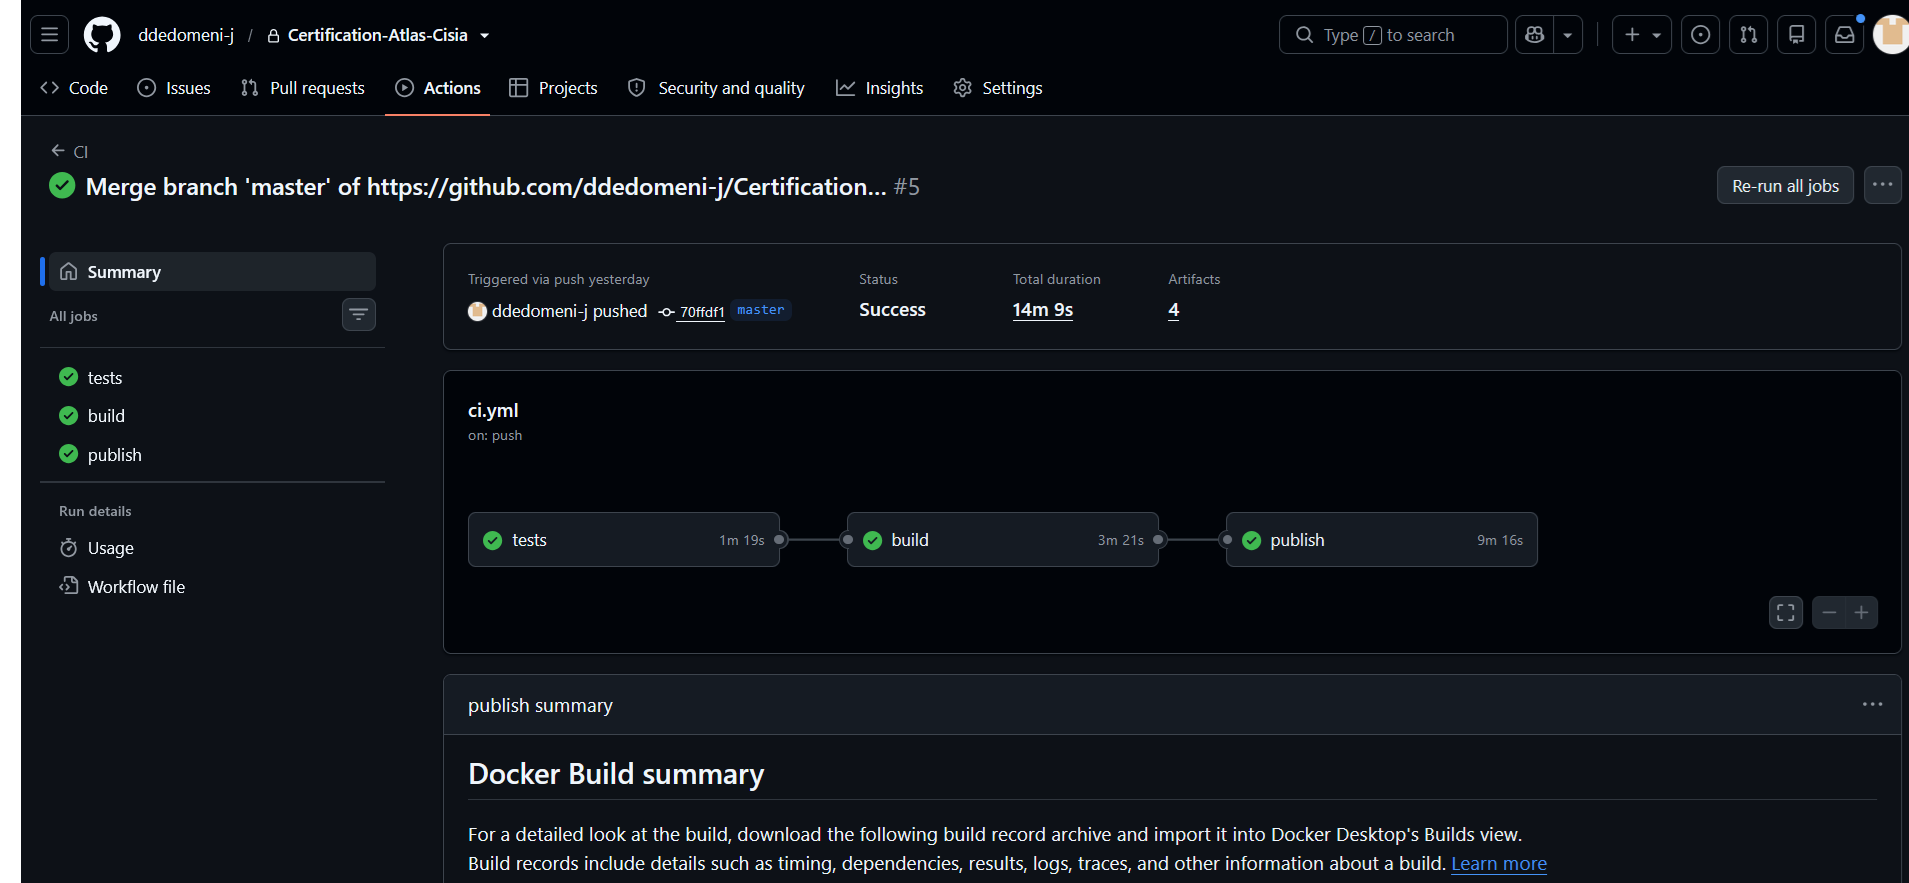

In [97]:
from IPython.display import Markdown, Image
display(Markdown("Accès aux tableaux de suivi :"))
Image("../Doc/WorkflowCICD.png", width=1200)

### 8.9 📝 Synthèse industrialisation

Le projet aboutit à une solution d’IA d’aide à la décision basée sur le modèle **S5 LightGBM**. Ce modèle a été retenu pour son compromis entre performance globale, stabilité et maîtrise des erreurs critiques $2 \rightarrow 0$.

L’architecture comprend :

- une application frontend **Streamlit** permettant aux conseillers de soumettre un dossier, de consulter les prédictions et d’enregistrer leurs feedbacks ; elle propose également à l’équipe MLOps des outils de supervision et le déclenchement du réentraînement
- une **API modèle**, dédiée au chargement et à l’exécution du modèle de prédiction
- une **API métier**, qui valide et prépare les données, appelle l’API modèle, applique les règles de revue humaine et journalise les prédictions ainsi que les requêtes associées
- une **API de réentraînement**, réservée à l’équipe MLOps, qui entraîne un modèle candidat à partir du jeu d’entraînement initial enrichi des feedbacks des conseillers, puis l’évalue avant une éventuelle promotion
- une base **SQLite** stockant les prédictions, les feedbacks et leur statut d’utilisation pour le réentraînement
- un répertoire d’artefacts organisé par version pour les modèles et leurs métadonnées ; **MLflow** assure la traçabilité des expérimentations, des paramètres, des métriques et des artefacts des candidats
- des dashboards **Grafana** pour le suivi opérationnel, alimentés par les métriques **Prometheus** exposées par les services

Cette architecture permet :

- de séparer le moteur de prédiction des règles métier : l’API métier applique une politique prudente d’abstention lorsque la confiance est insuffisante et prévoit une revue humaine renforcée pour certaines prédictions de retour rapide ;
- de distinguer la livraison technique des services par CI/CD de la validation métier des modèles ;
- d’évaluer les modèles candidats sur un jeu de référence figé avant toute promotion, selon un plancher de F1 macro, un gain minimal par rapport au modèle actif et l’absence de dégradation significative du taux d’erreurs critiques.

Plusieurs points restent à approfondir :

- enrichir le suivi en production avec des indicateurs de dérive et de qualité, lorsque les retours terrain seront disponibles
- automatiser les audits d’équité afin de suivre régulièrement les disparités éventuelles
- renforcer la sécurité des composants : mettre en place une authentification et une gestion des rôles et des accès, limiter les communications réseau aux seuls services nécessaires, protéger les secrets et les données sensibles, sécuriser les accès aux bases de données et prévoir le chiffrement, les sauvegardes et la surveillance des accès.

---
## 9. Suivi en production & amélioration continue

### 9.1 Métriques à surveiller

En production, aux métiques de **suivi de la qualité du système** suivies en continu via  Prometheus et Grafana, il faut ajouter le **suivi de la qualité du modèle**.  

Les métriques modèles ne peuvent pas toutes être mesurées en continu, certaines doivent être **recalculées périodiquement sur un lot de nouveaux dossiers labellisés ou corrigés**, par exemple après **x feedbacks qualifiés**. 

| Périmètre | Métrique | Seuil de référence | Suivi en production | Action si dérive |
|---|---|---:|---|---|
| Qualité modèle | **F1 macro** | **≥ 0,68** | Recalcul périodique sur un lot de nouveaux dossiers disposant d’un label ou d’un feedback exploitable | Si le score passe sous le seuil : analyser, puis réévaluer ou réentraîner un candidat |
| Qualité modèle | **Évolution du F1 macro** | Baisse tolérée de **0,018** | Comparaison avec la performance de référence du modèle actif | Si la baisse dépasse la tolérance : revue MLOps et nouvelle évaluation |
| Qualité modèle | **Taux d’erreur critique `2 → 0`** | **≤ 12 %** | Recalcul sur les nouveaux dossiers labellisés | Si le taux dépasse le seuil : analyser les cas critiques et envisager un nouveau cycle de réentraînement |
| Qualité modèle | **Disparate Impact (DI)** | **< 0,80** : vigilance ; **< 0,70** : blocage | Recalcul périodique par groupe d’âge et de nationalité | Si DI < 0,80 : analyse ; si DI < 0,70 : revue humaine renforcée et pas de promotion automatique |
| Qualité modèle / exploitation | **Part des dossiers en abstention ou revue humaine** | **≤ 20 %** | Suivi continu via le backend métier | Si la part dépasse durablement le seuil : revoir la charge et les règles de traitement |
| Qualité modèle / signal faible | **Répartition des prédictions par classe** | Pas de seuil fixé | Suivi continu dans Grafana, comparaison à une distribution de référence | Si la répartition change fortement : analyser le flux et déclencher une réévaluation du modèle |
| Qualité système | **Latence** | À définir | Suivi continu Prometheus / Grafana | Si dérive persistante : investigation technique |
| Qualité système | **Disponibilité** | À définir | Suivi continu Prometheus / Grafana | Si indisponibilité : alerte et diagnostic du service concerné |
| Qualité système | **Erreurs HTTP** | À définir | Suivi continu Prometheus / Grafana | Si hausse anormale : investigation technique sur l’API concernée |

Le **F1 macro**, le **taux d’erreur critique** et le **DI** ne sont donc pas des métriques Prometheus natives : ce sont des **métriques de qualité métier et modèle** à recalculer par lot sur de nouvelles données qualifiées.  
À l’inverse, la **latence**, la **disponibilité**, les **erreurs HTTP** et la **répartition des prédictions** sont des **signaux opérationnels continus** déjà exploitables pour la supervision.

### 9.2 Boucle de rétroaction

Le parcours de feedback est décrit en sections 8.2 à 8.4. Le conseiller peut corriger une prédiction. Le feedback est enregistré avec le dossier et peut ensuite être exploité par l’API de réentraînement.

Lors d’un cycle, les feedbacks non encore utilisés sont ajoutés au jeu d’entraînement initial. Un modèle candidat est entraîné, puis comparé au modèle actif sur le jeu de référence figé. Si le cycle réussit, les feedbacks concernés sont marqués comme utilisés. La recommandation de promotion est produite séparément : la promotion du candidat requiert une validation humaine et ne met donc pas automatiquement à jour le modèle actif.

### 9.3 Plan de réentraînement

Le déclenchement du réentraînement n’est pas encore associé à une cadence ni à un seuil de volume de feedbacks. Ces paramètres restent à définir avec l’équipe MLOps ; aucun seuil PSI ni seuil hebdomadaire de F1 n’est établi dans le notebook.

Un cycle peut être déclenché par l’équipe MLOps lorsqu’un volume de feedbacks jugé suffisant est disponible, ou lorsqu’une revue des indicateurs et des résultats observés justifie une nouvelle évaluation. Il ne s’agit pas d’un déclenchement automatique défini à ce stade.

### 9.4 Robustesse en exploitation

🎯 Cette section présente des **améliorations possibles** pour renforcer la surveillance en production, **non implémentées à ce stade**.

À ce jour, la supervision effectivement disponible porte surtout sur :
- la **qualité système** : latence, disponibilité, erreurs HTTP ;
- certains **signaux métier simples** : répartition des prédictions, volume de dossiers envoyés en revue humaine.

Des mécanismes plus avancés pourraient être ajoutés dans une version ultérieure pour mieux surveiller les conditions de défaillance du modèle :

| Axe d’amélioration | Exemple de métrique | Usage envisagé |
|---|---|---|
| **Détection OOD** | Distance de Mahalanobis, isolation score | Repérer des dossiers très différents des données d’entraînement et déclencher une abstention ou une revue humaine |
| **Suivi du rejet / abstention** | Taux d’abstention, part de prédictions sous seuil | Vérifier si les seuils définis en section 7 restent adaptés en production |
| **Calibration** | Brier score, courbe de calibration | Vérifier si les probabilités produites par le modèle restent fiables dans le temps |

Ces éléments ne font donc **pas partie du périmètre actuellement déployé**. Ils constituent des **évolutions recommandées** pour une version plus mature du système, en complément des règles de fallback définies en section 7.

---
## 📎 Annexes

### A. Glossaire métier & technique

### B. Sources & bibliographie

- *[Datasets, articles, documentation technique consultés]*

### C. Décisions techniques détaillées

*[Justifications longues qu'on ne met pas dans le corps du notebook pour le garder lisible.]*

### A. Hypothèses et conditions de réalisation

Les développements ont été réalisés avec l’assistance de GitHub Copilot, en mode conseil, à partir du contexte fonctionnel et technique fourni dans les briefs de formation.

L’architecture initiale prévoyait de conserver le code d’exploration, de préparation des données, de sélection et d’entraînement dans des fonctions Python externes appelées depuis les cellules du notebook. Cette organisation a été adaptée lorsqu’il a été demandé d’intégrer ces étapes directement au notebook afin de centraliser la démonstration et de faciliter sa lecture.

La totalité de l’EDA, la définition des scénarios, la sélection des modèles, l’optimisation et l’entraînement du modèle retenu ont donc été réalisés et documentés dans ce notebook.

Le code d’industrialisation reste séparé dans le dépôt Git afin de proposer une architecture exécutable et testable.

---
### B. Journal de bord

## 📅 Journal de bord – Jour 1 (10/08/2026)

### 🔧 Étapes / Actions réalisées
- Prise en main du jeu de données et cadrage dU SUJET
- Construction du notebook `EDA.ipynb` pour centraliser les premières analyses
- Le dataset a une taille moyenne (2500 lignes, 10 features), pandas suffira pour le chargement des données
- Vérification de la qualité globale des données par analyse descriptive avec `pandas` pour obtenir les premiers constats (`head`, `info`, `describe`)
- Analyse du contenu de la variable synthèse entretien

### 📝 Observations / Difficultés
- % valeurs manquantes OK, pas de doublons dans l'Id, pas de doublons hors Id, bonne répartition de la cible et des catégorielles, seule nationalite_hors_ue a une réparition 88,2/11,8
- Je remarque que code_insee_commune a 2407 valeurs -> à voir pour l'encodage si ça ne va pas faire trop de valeurs
- la variable niveau_diplome est ordonnable, on pourrait l'encoder en variable ordinale : est-ce qu'on peut comparer l'écart entre Bac+5 et Bac+2 et l'écart entre sans diplôme et Bac?
- Je cherchais à savoir si synthèse entretien contenait des données personnelles à anonymiser, et je constate qu'il n'y a que quelques valeurs différentes. Cela ressemble plus à une liste déroulante de textes prédéfinis qu'à un texte libre. Je n'ai pas de validation métier, mais c'est l'hypothèse que je ferai pour le reste du projet. Pas de données personnelles dans cette variable

## ✅ Prochaines étapes
- Approfondir l’analyse d’équité avec l’étude du disparate impact
- Identifier la ou les variables sensibles à examiner en priorité
- Gérer les manquants de la synthèse entretien : pour du texte, on privilégiera un remplacement par "TEXTE MANQUANT" pour matérialiser l'absence. Ca peut-être une information exploitable par le modèle.

## 📅 Journal de bord – Jour 2 (17/08/2026)

### 🔧 Étapes / Actions réalisées
- Je transfère le code dans le notebook final qui devra contenir l'ensemble du code
- Analyse de distribution des variables
- Correlation des variables à la cible
- Calcul de disparate impact (DI) sur les variables sensibles
- Analyse croisée âge / nationalité

### 📝 Observations / Difficultés
- Rien à signaler sur la répartition des variables
- Il y a bien un **disparate impact** sur les variables sensibles étudiées, en particulier sur l’**âge** et la **nationalité hors UE**
- L’analyse croisée montre une **aggravation des écarts** pour les personnes **de 50 ans et plus** ayant une **nationalité hors UE**

## ✅ Prochaines étapes
- Construire des scénarios de modélisation avec et sans variables sensibles.
- l'analyse du DI montre qu'il faudra tenir compte des variables sensibles dans la façon d'utiliser le modèle et dans les métriques d'évaluation

## 📅 Journal de bord – Jour 3 (18/08/2026)

### 🔧 Étapes / Actions réalisées
- Entrainement de plusieurs modèles sur le jeu de données complet (S1) pour me donner une idée des performances de différents types d'architecture
- Mise en place du pipeline d'entrainement
- ⚖️ Regroupement des code insee commune en departement (crée des classes plus représentatibes + moins de feature crées), regroupement des codes rome visés par lettre

### 📝 Observations / Difficultés
- Les modèles ont des performances bien supérieures à celles du dummy, donc les modèles apprennent à partir des features
- Je constate que certains dossiers mal classé par le modèle LightGBM ont des synthèses entretien qui ne correspondent pas sémantiquement à leur classement par le modèle

## ✅ Prochaines étapes
- Etudier l'importance des features sur des cas d'erreur avec SHAP pour déterminer les facteurs importants dans les mauvaises décisions du modèle. Ca me permettra de mieux comprendre aussi comment fonctionne TF-IDF

## 📅 Journal de bord – Jour 4 (24/08/2026)

### 🔧 Étapes / Actions réalisées
- Sélection de cas d'erreur et utilisation de shap.TreeExplainer pour tracer les graphes de dépendance

### 📝 Observations / Difficultés
- ⚠️ Dans les features les plus importantes il y a énormément de mots de liaisons (comme text_de). L'ajout de stop_words=list(STOP_WORDS) dans l'appel à TfidfVectorizer permet de ne pas prendre en compte ces mots de liaison et les graphiques deviennent plus lisibles
- Je comprends également que TF-IDF est un modèle statistique qui n'a pas de notion sémantique. J'envisage un moment l'utilisation d'un modèle d'embedding mais je renonce car les erreurs montrent qu'un score favorable peut etre associé à une synthèse négative et inversement
- Je n'y avais pas pensé en constatant que synthese_entretien a un nombre fini de valeurs, mais il est possible de considérer la variable synthèse entretien comme une variable catégorielle
- l'analyse SHAP montre que l'age a plus de poids que nationalite_hors_ue dans la prédiction du modèle

## ✅ Prochaines étapes
- Ajouter un scénario S5 : synthese_entretien encodé en variable catégorielle en plus des 4 scénarios de base
- Ajouter un scénario encodant le niveau de diplome en ordinal (S6), un scénario supprimant la variable sensible age (S7), 1 scénario supprimant la variable sensible nationalite_hors_ue (S8)

## 📅 Journal de bord – Jour 5 (31/08/2026)

### 🔧 Étapes / Actions réalisées
- Mise en place du pipeline final :
    - séparation stratifiée entre un jeu d'entraînement de 80 % et un jeu de test final de 20 %
    - validation croisée stratifiée à 5 folds sur le jeu d'entraînement
- Test du regroupement de la variable 'code_rome_vise' sur le scénario S1

### 📝 Observations / Difficultés
- ⚖️ Le regroupement de la variable 'code_rome_vise' par lettre dégrade les métriques. Le code complet de la variable sera conservé, sa cardinalité restant modérée

## ✅ Prochaines étapes
- Lancer le pipeline sur les 8 scénarios pour en tirer 2 modèles finalistes à optimiser
- les critères de sélection retenus sont le F1 macro comme critère principal arbitré par l'erreur critique et la stabilité du modèle entre les Folds

## 📅 Journal de bord – Jour 6 (07/09/2026)

### 🔧 Étapes / Actions réalisées
- Entrainement des 5 modèles choisis sur les différents scénarios et évaluation des métriques
- Sélection des scénarios pour l'optimisation

### 📝 Observations / Difficultés
- Les scénarios multimodaux (**S1, S5** et **S6**) obtiennent les meilleurs scores F1 macro. Les scores sont relativement bas, autour de 0.7
- Le scénario **S4** réduit les erreurs critiques (8,6% pour XGBoost et 9,7% pour RandomForest)
- Le scénario **S3** a un F1 macro plus faible 0.635 au mieux et présente un taux d'erreur critique de 19% pouvant atteindre 28% selon les folds
- Le scénario **S2** qui supprime les variables sensibles fait tomber le F1 macro à 0.644 au mieux pour la régression logistique, mais dégrade l'erreur critique à 16% au mieux
- Le scénario **S6** montre que l'encodage de la variable diplome en ordinale dégrade légèrement les performances

## ✅ Prochaines étapes
- Pour la suite je décide d'optimiser sur les scénarios S5 + LightGBM et S4 + Random Forest. Les performances des scénarios S2 et S3 sont pour moi trop basses, S6 n'apporte pas d'amélioration et S5 est légèrement supérieur à S1
- Je décide de garder deux modèles relativement différents en terme d'architecture pour essayer de voir si l'optimisation va produire des résultats différents


## 📅 Journal de bord – Jour 7 (11/09/2026)

### 🔧 Étapes / Actions réalisées
- On a utilisé GridSearchCV dans les briefs, je regarde les autres solutions mentionnées dans les ressources : Optuna et RandomizedSearchCV
- Choix des paramètres à optimiser
- Lancement de l'optimisation des 2 scénarios retenus
- Évaluation des configurations par validation croisée stratifiée à 5 folds sur le jeu d’entraînement

### 📝 Observations / Difficultés
- ⚖️ Je choisis de garder GridSearchCV pour sa simplicité et car c'est plus adapté à la comparaison de 2 modèles sur des ranges de paramètres définis. C'est une méthode reproductible à défaut d'être la plus performante.
- La taille du jeu de données étant modérée (2500 lignes) le nombre d'hyperparamètres testés sera limité et le coût de calcul supportable dans mon environnement
- ⚖️ Choix de min_child_samples plutôt que max_depth pour limiter l'overfitting. L'objectif reste le même (éviter des arbres trop complexes), mais cette approche impose un nombre minimum d'observations par feuille tout en laissant à l'algorithme davantage de liberté dans la structure des arbres
- ⚖️ Variation de num_leaves entre 15 (modèle plus simple, plus stable, risque d'overfitting limité) et 63 feuilles (davantage de règles apprises et de relations modélisées, mais risque d'overfitting plus élevé)
- Optimisation initiale réalisée sur le F1 macro -> mise en place d'une métrique personnalisée combinant F1 macro et taux d'erreur critique afin de rechercher un meilleur compromis entre performance globale et risque métier
- Le recall global obtenu sur le modèle final est décevant : 0.52 sur la classe 2 (bcp de 2 classé en 1, même si peu d'erreur 2 -> 0)

## ✅ Prochaines étapes
- Les résultats ne me conviennent pas, je décide de refaire une passe sur l'entrainement : 
    - ajout de 2 scénarios S7 (retrait de la variable âge) et S8 (retrait de la variable nationalite_hors_ue)
    - ajout du recall de la classe 2 dans le critère d'arbitrage

## 📅 Journal de bord – Jour 8 (12/09/2026)

### 🔧 Étapes / Actions réalisées
- Définition des 2 nouveaux scénarios et lancement de l'entrainement

### 📝 Observations / Difficultés
- Les résultats **S7** montrent que le retrait de la variable age dégrade fortement les métriques et notamment le F1 macro qui descend à 0.625
- Les résultats **S8** montrent que le retrait de la variable nationalite_hors_ue dégrade le F1 (0.689 vs 0.704 en S5) et le taux d'erreur critique (12.7% vs 10.8% en S5)
- le scénario **S4 + Random Forest** retenu précédemment a un recall sur la classe 2 de `0,547` sensiblement inférieurs à ceux des meilleurs candidats S5.
- Les deux modèles présentant le meilleur compromis sont :
    - **S5 + LightGBM** présente le meilleur compromis initial : F1 macro de `0,704`, stabilité élevée (écart-type de `0,018`). Son recall sur la classe 2 est de `0,602` et son taux d’erreur critique est de `10,8 %`
    - **S5 + Random Forest** obtient un F1 macro presque identique (`0,703`) et un meilleur recall de la classe 2, mais son taux d’erreur critique est plus élevé (`13,0 %`)

## ✅ Prochaines étapes
- Les résultats du scénario S8 pourraient pourraient en faire un scénario éthique crédible à discuter avec le client. Toutefois, Pour cette étude, la performance globale du modèle et la limitation du taux d’erreurs critiques sera privilégiée
- optimisation des deux candidats **S5 + LightGBM** et **S5 + Random Forest**

## 📅 Journal de bord – Jour 9 (13/09/2026)

### 🔧 Étapes / Actions réalisées
- Lancement de l’optimisation des hyperparamètres avec `GridSearchCV` sur les deux candidats retenus
- Évaluation de chaque configuration par validation croisée stratifiée à 5 folds
- Sélection, pour chaque candidat, d’une configuration de compromis F1 macro / stabilité / taux d'erreur critique / recall classe 2
- Calcul du disparate impact (DI) sur les prédictions out-of-fold des configurations retenues, pour les groupes d’âge et de nationalité
- Comparaison du DI prédit avec le DI observé dans les données d’entraînement afin d’identifier une amplification éventuelle des disparités

### 📝 Observations / Difficultés

- Après optimisation, S5 LightGBM obtient le meilleur F1 macro (`0,6955`) et la meilleure stabilité (`0,0089`), avec un taux d’erreur critique de `10,78 %`
- S5 Random Forest obtient un recall de la classe 2 plus élevé (`0,7516` contre `0,5886` pour LightGBM), tout en ayant le même taux d’erreur critique (`10,78 %`)
- Random Forest dégrade davantage les indicateurs d’équité : le DI prédit est de `0,642` pour les personnes de 60 ans et plus et de `0,643` pour les personnes hors UE, contre respectivement `0,671` et `0,714` avec LightGBM
- Les deux modèles présentent au moins un DI inférieur au seuil bloquant de `0,70`. Ils ne peuvent donc pas être utilisés pour une décision automatisée sans revue humaine renforcée pour les groupes concernés
- ⚖️ L'arbitrage est très compliqué entre performance globale, erreur critique et éthique : **S5 LightGBM** est conservé comme scénario final car malgré un **recall de la classe 2** plus faible il est le modèle qui **dégrade le moins le DI** par rapport aux données
- À l’issue de l’arbitrage, évaluation unique de **S5 LightGBM** sur le jeu de test gelé afin d’estimer sa généralisation sur des données non utilisées pendant la sélection et d'établir les métriques de référence du modèle de production.

## ✅ Prochaines étapes
- Dessiner l'architecture du système final
- Sauvegarder les modèles dans un répertoire Models sauvegardant le modèle versionné .joblib et ses metadata

## 📅 Journal de bord – Jour 10 (14/09/2026)

### 🔧 Étapes / Actions réalisées

- Conception du schéma d’architecture cible de l’application au format mermaid
- le système initial comprend :
    - 1 frontend **Streamlit** pour permettre aux conseillers de saisir un dossier et de consulter une recommandation
    - 2 services backend :
        - une **API métier**, responsable de la validation des données, des règles métier, de la traçabilité et de la communication avec le frontend
        - une **API modèle**, dédiée au chargement du modèle entraîné et au calcul des prédictions
- Ajout d’un flux MLOps distinct : entraînement/optimisation d’un candidat, évaluation, validation humaine, puis livraison d’une nouvelle version du modèle si les critères sont respectés
- Conteneurisation des services

### 📝 Observations / Difficultés
- Utilisation de l'architecture FastAPI /pydantic utilisée pendant la formation qui est très simple à mettre en place
- ⚖️ La séparation entre API métier et API modèle permet 
    - d’isoler les règles d’usage du modèle des règles propres au métier et à l’interface utilisateur
    - au frontend de ne pas appeler directement le modèle
- ⚠️ Je rencontre un premier problème avec Docker : LightGBM a besoin d'openMP qui n'est pas dans l'image choisie. J'ajoute l'installation de libgomp1
- ⚠️ Je rencontre un problème après réentrainement d'un modèle. La version est codée en dur dans les tests. Au delà de ça, le processus de réentrainement relivraison n'est pas intégré et difficile à exécuter et monitorer

## ✅ Prochaines étapes
- ⚖️ Ajouter un service pour la partie réentrainement appelable depuis l'interface streamlit dans une page dédiée pour l'équipe MLOps
- ⚖️ Versionner le modèle en "production" dans un fichier json placé dans le répertoire où sont stockés les modèles pour pouvoir charger la bonne version et tester Candidat vs Prod
- Ajouter la supervision des API des différents service et de MlFlow dans l'interface client

## 📅 Journal de bord – Jour 11 (21/09/2026)

### 🔧 Étapes / Actions réalisées
- Ajout de l'enregistrement des feedbacks dans une base SQLite et charger les données pour le réentrainement
- Ajout d'un fichier permettant de gérer la version du modèle effectivement en production
- Ajout d'un service Fast API qui lance un entrainement à partir des données de la base de tests enrichie des feedbacks, evalue le modele candidat pour calculer ses métriques et fait des recommandations pour la promotion à partir des règles établies
- La décision de promotion reste humaine et manuelle (changement du numéro de version et renommage du modele candidat). 
- Affichage de la recommandation dans l'interface Streamlit

### 📝 Observations / Difficultés
- ⚠️ Séparation initiale des données selon un ratio 80/20 : le jeu d’entraînement sert à la validation croisée et à l’optimisation, tandis que le jeu de test reste isolé pour l’évaluation finale du modèle retenu. Il manque un jeu de référence gelé, distinct des données utilisées pour entraîner les candidats de réentraînement. Ce jeu permet de comparer équitablement chaque candidat enrichi par les feedbacks au modèle actif
- ⚠️ Les métriques obtenues lors du réentraînement peuvent différer de celles de l’étude initiale, rendant les seuil moins précis. 
- ⚖️ Je ne relance pas le pipeline, l’important étant de montrer le workflow et que le candidat et le modèle actif soient comparés sur le même jeu de référence
- Le fichier contenant la version permet de revenir facilement à la version précédente dans la stratégie de fallback
- ⚠️ Echec du pipeline de réentraînement sur les données de réentrainement contenant des valeurs manquantes au format nullable Pandas (`pd.NA`). La conversion effectuée est de passer les variables au format `object`, puis de normaliser en `numpy.nan` leurs valeurs manquantes

## ✅ Prochaines étapes
- Orchestration et déploiement

## 📅 Journal de bord – Jour 12 (25/09/2026)

### 🔧 Étapes / Actions réalisées
- Centralisation des URL et récupération dans des variables d'environnement pour le lancement des services conteneurisés
- Création du fichier docker-compose pour l'orchestration des services et du frontend

### 📝 Observations / Difficultés
- Réorganisation de l'UI streamlit pour enchainer les différentes étapes du workflow

## ✅ Prochaines étapes
- Connexion des services à Prometheus
- Visualisation des indicateurs dans des dashboard Grafana
- Connexion des écrans de suivi à l'interface client streamlit

## 📅 Journal de bord – Jour 13 (26/09/2026)

### 🔧 Étapes / Actions réalisées
- Connexion des trois APIs (`model-api`, `backend-metier-api` et `retraining-api`) à Prometheus via leurs routes `/metrics`.
- Configuration de Prometheus via `Prometheus.yml` pour collecter les métriques de disponibilité, de requêtes HTTP, de latence et de prédictions
- Configuration de Prometheus pour interroger les routes `/metrics` des trois APIs toutes les `5` secondes.
- Création d’un dashboard Grafana pour visualiser l’état des services, la latence de l’API modèle, la distribution des prédictions et les erreurs HTTP entre les services.
- Ajout dans Streamlit d’accès aux écrans de suivi MLflow et Grafana afin de centraliser les outils de supervision.

### 📝 Observations / Difficultés
- ⚖️ Utilisation de panneaux **Stat** avec un code couleur pour visualiser immédiatement la disponibilité opérationnelle de chaque service
- ⚖️ Utilisation de **séries temporelles** pour suivre les erreurs HTTP et la latence de l’API modèle. Ce format permet d’observer l’évolution du signal, d’identifier une hausse progressive de la latence ou de situer un incident dans le temps
- ⚖️ Utilisation d’un **Bar chart** pour représenter les prédictions par classe et le nombre de prédictions. Ce graphique facilite la comparaison entre les catégories sur une période donnée
- Le suivi porte sur des métriques techniques et des compteurs simples. Le calcul continu du **F1 macro**, du **recall de la classe 2**, du **taux d’erreur critique** nécessitent les vérités terrain, disponibles avec délai via les feedbacks et est plus long à mettre en place
- ⚠️ Le service `retraining-api` ne lançait initialement pas `register_mlflow.py`, il a été ajouté et les URL/hôtes Docker reconfigurées
- ⚠️ Résolution d'adresse inter-conteneurs : remplacement de `127.0.0.1:5000` par `http://mlflow:5000` via variable d'environnement Docker
- ⚠️ MLflow rejette les requêtes inter-services avec une erreur 403 (`Invalid Host header`) ; résolution par l'ajout du paramètre `--allowed-hosts mlflow:5000,localhost:5000,127.0.0.1:5000` dans la commande du conteneur MLflow

## ✅ Prochaines étapes
- Mettre en place un workflow CI/CD pour automatiser l’exécution des tests, la construction des images Docker et la publication d’images versionnées destinées au déploiement.

## 📅 Journal de bord – Jour 14 (27/09/2026)

### 🔧 Étapes / Actions réalisées
- Mise en place de GitHub Actions pour automatiser l’enchaînement des tests, de la construction des images Docker et de leur publication dans GitHub Container Registry (GHCR)
- Déclenchement du pipeline complet à chaque push sur la branche `master`
- Lors d’une pull request depuis une branche, exécution des tests et construction des images afin de valider les modifications avant intégration
- Après validation et merge de la pull request sur `master`, publication des images Docker dans GHCR

### 📝 Observations / Difficultés
- Création de `docker-compose.prod.yml`, qui utilise pour le déploiement les images versionnées publiées dans GHCR et taguées par le SHA du commit. Les artefacts de modèle restent fournis séparément par le volume `Models/`
- L’utilisation d’images taguées par SHA garantit que la version déployée est traçable et correspond à une version précise du code validé par le pipeline
